<a href="https://colab.research.google.com/github/Pascingo/CTA-media-analysis/blob/main/Stage_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage 3: RAG System for Question Answering (Track 1: AI Governance)

In this notebook we build and evaluate a RAG system for questions about AI Governance (AI security, accountability, bias and fairness, regulatory landscape). It combines text retrieval with our knowledge graph.

Before we build the RAG system, we address the feedback on Stage 1: a RAG system can only be as good as its corpus and its graph.


**Structure**

0. Setup and loading the Stage 1 data
1. Addressing the Stage 1 feedback
   - 1.1 Tightened topic filter
   - 1.2 Limitation: no quantitative evaluation of the topic filter
   - 1.3 Splitting the articles into passages
   - 1.4 Reproducible relation extraction with a controlled predicate schema
   - 1.5 Validation of the important relations
   - 1.6 Knowledge graph v2: factual layer and co-occurrence layer
   - 1.7 Export of the Part 1 results
2. Q&A dataset construction
3. Text-only RAG baseline
   - 3.1 Search corpus
   - 3.2 Embeddings
   - 3.3 Retrieval strategies
   - 3.4 Answer generation
   - 3.5 Evaluation of retrieval
4. Graph-enhanced RAG
5. System evaluation: text-only vs. graph-enhanced RAG
6. RAG enhancement
7. Insights: RAG and knowledge graphs for trend monitoring in AI Governance
8. Contributions and AI tools disclosure

# 0. Setup

We use the same settings as in Stage 1 (time frame, keywords, threshold), so that both stages work with exactly the same articles. Results and caches of Stage 3 are saved on Google Drive (`NLP_Projekt/stage3`), so they survive a runtime reset and can be shared within the team. Libraries that are only needed in later parts are installed and imported in those parts.

In [3]:
!pip install -q -r https://raw.githubusercontent.com/Pascingo/CTA-media-analysis/main/requirements.txt

import os
import re
import json
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import gdown
from tqdm.auto import tqdm
import hashlib
from sentence_transformers import SentenceTransformer
from google.colab import drive
import textwrap
import time
from IPython.display import Markdown, display

# Same settings as in Stage 1
TEXT_COLUMN = "content"
START_DATE = "2024-09-01"
END_DATE = "2026-08-31"

GOVERNANCE_KEYWORDS = [
    "security", "accountability", "bias", "fairness",
    "regulatory", "regulation", "governance", "policy",
    "ethics", "compliance", "law"
]
MIN_KEYWORD_HITS = 5
RANDOM_STATE = 42

# Folders and files
DATA_FOLDER = "data"

# Stage 3 results are saved on Google Drive, so that caches survive a runtime reset

drive.mount("/content/drive")
STAGE3_FOLDER = "/content/drive/MyDrive/NLP_Projekt/stage3"
os.makedirs(STAGE3_FOLDER, exist_ok=True)

DRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/14cAxvtxuTfwENtSDCmGcRpl6qhl-z62z"

DATASET_FILE     = os.path.join(DATA_FOLDER, "ai_media_dataset_20260911.csv")
STAGE1_GOV_FILE  = os.path.join(DATA_FOLDER, "ai_governance_cleaned.csv")
ENTITIES_FILE    = os.path.join(DATA_FOLDER, "entities_spacy.csv")
LANGEXTRACT_FILE = os.path.join(DATA_FOLDER, "langextract_ollama_25pm.jsonl")

Mounted at /content/drive


### Download of the Stage 1 data (Pascal)

We download the files from our public Google Drive folder: the fixed dataset version (2026-09-11), the Stage 1 governance corpus, the spaCy entities and the LangExtract results. The download is skipped if the files are already in the folder `data`.

In [ ]:
STAGE1_FILES = [DATASET_FILE, STAGE1_GOV_FILE, ENTITIES_FILE, LANGEXTRACT_FILE]

if not all(os.path.exists(f) for f in STAGE1_FILES):
    gdown.download_folder(DRIVE_FOLDER_URL, output=DATA_FOLDER, quiet=True)

for f in STAGE1_FILES:
    if not os.path.exists(f):
        raise FileNotFoundError(f"{f} not found. Please check the Google Drive folder.")
    print(f"{f:<45} {os.path.getsize(f) / 1e6:>8.1f} MB")

### Reconstructing the Stage 1 corpus with document IDs (Pascal)

In Stage 1 we saved the governance corpus without its index. The spaCy entities and the LangExtract results, however, refer to the articles by this index (`doc_id`). We therefore repeat the cleaning steps of Stage 1 on the original dataset. The steps are deterministic, so we get the same articles with the same `doc_id`.

Two checks make sure this worked:

1. The number of articles and the titles must be identical to `ai_governance_cleaned.csv`.
2. All `doc_id`s in the LangExtract results must exist in the reconstructed corpus.

We keep the **full cleaned corpus** (`df`), and not only the 12,393 Stage 1 articles. The new topic filter in Part 1 has to be evaluated on all articles, so that we also see relevant articles that the Stage 1 filter missed (recall). The column `in_stage1` marks the articles of the Stage 1 corpus.

In [9]:
# 1. Same cleaning as in Stage 1 (sections 2 and 3)
df = pd.read_csv(DATASET_FILE, usecols=["title", "date", "content", "domain", "url", "tags"])
df = df.dropna(subset=[TEXT_COLUMN])
df = df.drop_duplicates(subset=[TEXT_COLUMN])

df["published_at"] = pd.to_datetime(df["date"], errors="coerce")
df = df[(df["published_at"] >= START_DATE) & (df["published_at"] <= END_DATE)].copy()

df["cleaned_text"] = df[TEXT_COLUMN].apply(
    lambda t: unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode()
)
df["cleaned_text"] = (
    df["cleaned_text"]
    .str.lower()
    .str.replace(r"<[^>]+>", " ", regex=True)
    .str.replace(r"[-/]", " ", regex=True)
    .str.replace(r"[^a-z0-9\s.,!?]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

pattern = r"\b(?:" + "|".join(GOVERNANCE_KEYWORDS) + r")\b"
df["gov_keyword_hits"] = df["cleaned_text"].str.count(pattern)
df["in_stage1"] = df["gov_keyword_hits"] >= MIN_KEYWORD_HITS
df.index.name = "doc_id"

# 2. Check 1: same articles as the saved Stage 1 corpus
df_gov_s1 = pd.read_csv(STAGE1_GOV_FILE)
stage1_ids = df.index[df["in_stage1"]]

assert len(stage1_ids) == len(df_gov_s1), "Number of articles differs from Stage 1."
assert (
    df.loc[stage1_ids, "title"].fillna("").values == df_gov_s1["title"].fillna("").values
).all(), "Titles differ from Stage 1."

# Take over the columns computed in Stage 1 (spaCy lemmas, sentiment)
for col in ["processed_text", "sentiment_polarity"]:
    df.loc[stage1_ids, col] = df_gov_s1[col].values

# 3. Check 2: the LangExtract results refer to existing articles
lx_doc_ids = pd.read_json(LANGEXTRACT_FILE, lines=True)["doc_id"]
share_found = lx_doc_ids.isin(stage1_ids).mean()
assert share_found == 1.0, f"Only {share_found:.1%} of the LangExtract doc_ids were found."

print(f"Full cleaned corpus:        {len(df):>6,} articles")
print(f"Stage 1 governance corpus:  {df['in_stage1'].sum():>6,} articles")
print(f"LangExtract articles found: {lx_doc_ids.nunique():>6,} (100%)")

Full cleaned corpus:        47,444 articles
Stage 1 governance corpus:  12,393 articles
LangExtract articles found:    599 (100%)


# 1. Addressing the Stage 1 feedback

The feedback on Stage 1 named three problems:

1. Several topics of our corpus are about **broader politics, energy and enterprise technology** rather than AI Governance. Our topic filter was too broad.
2. The relation extraction produced many **inconsistent predicates** and **source-alignment problems**. After schema filtering, very few factual relations remained.
3. The co-occurrence graph is useful for exploration, but it is **not factual evidence**.

These problems directly affect the RAG system: irrelevant articles become irrelevant retrieved passages, and wrong relations become wrong "facts" in the answers. We therefore address them first.

## 1.1 Tightened topic filter (Pascal)

The Stage 1 filter counted eleven general keywords and kept every article with at least 5 hits. It had two weaknesses:

- **Generic words** such as *security*, *policy* and *law* also appear in articles about cybersecurity products, US domestic politics or company policies.
- **Absolute counts** favour long articles: a 4,000-word article about energy markets reaches 5 hits easily, even if governance is only a side remark.

The new filter works in three steps:

1. **Governance score:** We count specific governance terms in two groups. *Strong terms* (e.g. *AI Act*, *code of practice*, *AI safety institute*, *copyright*, *lawsuit*) are clearly about governance on their own and get weight 3. *Medium terms* (e.g. *regulation*, *accountability*, *bias*, *oversight*) get weight 1. The generic words *security*, *policy* and *law* are no longer counted. We divide the weighted hits by the article length (**hits per 1,000 words**), so that long articles are not favoured.
2. **Off-topic score:** For the three confounders named in the feedback (politics, energy, enterprise technology), we count typical terms in the same way. The term lists are based on our Stage 1 topics 2, 3, 4, 5 and 7.
3. **Decision rule:** An article is kept if governance is dense enough, appears in the title or across several distinct terms, and is **at least as dense as the strongest off-topic vocabulary**. In other words, governance has to be the main subject, not a side remark.

We chose the thresholds by inspecting the results qualitatively (sample titles per group and per score range). A quantitative evaluation was not possible within the time of the project (see section 1.2).

In [10]:
import hashlib

# Strong terms: clearly about AI Governance on their own (weight 3)
STRONG_TERMS = [
    r"ai act", r"code of practice", r"ai (?:safety|security) institutes?",
    r"executive orders?", r"gdpr", r"digital services act", r"responsible ai",
    r"ai governance", r"ai regulations?", r"ai safety", r"ai ethics",
    r"algorithmic bias", r"sb 53", r"sb 1047", r"frontier ai", r"deepfakes?",
    r"copyright", r"lawsuits?", r"data protection", r"ai liability",
    # AI security is part of our track
    r"ai security", r"prompt injections?", r"adversarial attacks?", r"(?:data|model) poisoning",
]

# Medium terms: typical governance vocabulary (weight 1)
MEDIUM_TERMS = [
    r"regulations?", r"regulatory", r"regulators?", r"legislation", r"lawmakers?",
    r"governance", r"accountability", r"fairness", r"bias(?:es|ed)?", r"discrimination",
    r"ethic(?:s|al)", r"transparency", r"oversight", r"liability", r"compliance",
    r"privacy", r"audits?", r"watermark(?:s|ing)?", r"red teaming", r"jailbreaks?",
    r"misinformation", r"ai risks?",
]

# Off-topic vocabulary for the three confounders named in the feedback
OFFTOPIC_TERMS = {
    "politics": [
        r"elections?", r"campaigns?", r"voters?", r"democrats?", r"republicans?",
        r"tariffs?", r"trade war", r"immigration", r"ukraine", r"russia",
        r"israel", r"gaza", r"iran", r"nato", r"military",
    ],
    "energy": [
        r"energy", r"electricity", r"power grids?", r"grid", r"nuclear",
        r"gigawatts?", r"megawatts?", r"utilities", r"oil", r"gas", r"solar",
        r"emissions", r"data centers?",
    ],
    "enterprise": [
        r"revenue", r"earnings", r"quarterly", r"shares", r"stock", r"investors?",
        r"valuation", r"funding round", r"ipo", r"customers?", r"enterprises?",
        r"saas", r"hybrid cloud", r"red hat", r"kubernetes", r"apis?",
        r"developers?", r"workflows?", r"productivity", r"mcp",
    ],
}


def count_terms(texts, terms, desc):
    """Count every term in every text in ONE pass per text.
    Each term is its own capture group; match.lastindex tells us which term matched."""
    regex = re.compile("|".join(rf"(\b{t}\b)" for t in terms))
    counts = np.zeros((len(texts), len(terms)), dtype=np.int32)
    for i, text in enumerate(tqdm(texts, desc=desc)):
        for match in regex.finditer(text):
            counts[i, match.lastindex - 1] += 1
    return pd.DataFrame(counts, columns=terms, index=texts.index)


# Cache: the file name contains a hash of the term lists,
# so the features are recomputed automatically when a list changes
term_hash = hashlib.md5(
    json.dumps([STRONG_TERMS, MEDIUM_TERMS, OFFTOPIC_TERMS]).encode()
).hexdigest()[:8]
TOPIC_FEATURES_FILE = os.path.join(STAGE3_FOLDER, f"topic_features_{term_hash}.parquet")

df["cleaned_title"] = (
    df["title"].fillna("").astype(str).str.lower()
    .str.replace(r"[-/]", " ", regex=True)
    .str.replace(r"[^a-z0-9\s.,!?]", "", regex=True)
)
df["n_words"] = df["cleaned_text"].str.count(" ") + 1

if os.path.exists(TOPIC_FEATURES_FILE):
    features = pd.read_parquet(TOPIC_FEATURES_FILE)
    print("Loaded topic features from cache.")
else:
    strong_counts = count_terms(df["cleaned_text"], STRONG_TERMS, "strong terms")
    medium_counts = count_terms(df["cleaned_text"], MEDIUM_TERMS, "medium terms")

    features = pd.DataFrame(index=df.index)
    features["gov_strong_hits"] = strong_counts.sum(axis=1)
    features["gov_medium_hits"] = medium_counts.sum(axis=1)
    features["gov_distinct_terms"] = (strong_counts > 0).sum(axis=1) + (medium_counts > 0).sum(axis=1)

    title_pattern = "|".join(rf"\b{t}\b" for t in STRONG_TERMS + MEDIUM_TERMS)
    features["gov_in_title"] = df["cleaned_title"].str.contains(title_pattern, regex=True)

    for category, terms in OFFTOPIC_TERMS.items():
        features[f"off_{category}_hits"] = count_terms(df["cleaned_text"], terms, category).sum(axis=1)

    features.to_parquet(TOPIC_FEATURES_FILE)

df = df.drop(columns=features.columns, errors="ignore").join(features)

# Densities per 1,000 words
df["gov_score_per_1k"] = 1000 * (3 * df["gov_strong_hits"] + df["gov_medium_hits"]) / df["n_words"]
for category in OFFTOPIC_TERMS:
    df[f"off_{category}_per_1k"] = 1000 * df[f"off_{category}_hits"] / df["n_words"]

OFF_COLUMNS = [f"off_{c}_per_1k" for c in OFFTOPIC_TERMS]
df["off_max_per_1k"] = df[OFF_COLUMNS].max(axis=1)
df["off_main_category"] = df[OFF_COLUMNS].idxmax(axis=1).str.replace("off_", "").str.replace("_per_1k", "")

df[["n_words", "gov_score_per_1k", "gov_distinct_terms"] + OFF_COLUMNS].describe().round(2)

Loaded topic features from cache.


,n_words,gov_score_per_1k,gov_distinct_terms,off_politics_per_1k,off_energy_per_1k,off_enterprise_per_1k
count,47444.00,47444.00,47444.00,47444.00,47444.00,47444.00
mean,1659.03,3.61,1.92,0.83,1.47,5.95
std,1154.28,7.45,2.50,2.84,5.01,8.03
min,210.00,0.00,0.00,0.00,0.00,0.00
25%,969.00,0.00,0.00,0.00,0.00,0.67
50%,1248.00,1.15,1.00,0.00,0.00,2.98
75%,1853.00,3.80,3.00,0.00,0.84,8.15
max,9533.00,129.73,28.00,61.77,96.92,80.00


### Lexical candidate filter (Pascal)

A first run showed that the lexical score alone is not precise enough. Articles about healthcare, construction, solar panels or tax reached a governance score of 5–9 only through general words such as *privacy*, *compliance* or *transparency*. Such topics cannot all be covered by off-topic lists. The lexical step is therefore used as a **high-recall candidate filter**: it should keep almost all real governance articles, and precision is added in the next step with a semantic score.

An article becomes a candidate (`gov_lexical`) if all three conditions are met:

1. `gov_score_per_1k >= MIN_GOV_SCORE`;
2. the title contains a governance term, **or** the text contains at least `MIN_DISTINCT_TERMS` different governance terms;
3. `gov_score_per_1k >= off_max_per_1k`: governance is at least as dense as the strongest off-topic vocabulary.

We also added four AI-security terms (e.g. *prompt injection*, *data poisoning*). The first run had removed an article about securing agentic AI systems, although AI security is part of our track.

In [11]:
# Loose thresholds: the candidate filter should favour recall
MIN_GOV_SCORE = 3
MIN_DISTINCT_TERMS = 3


def apply_lexical_filter(data, min_score, min_distinct):
    return (
        (data["gov_score_per_1k"] >= min_score)
        & (data["gov_in_title"] | (data["gov_distinct_terms"] >= min_distinct))
        & (data["gov_score_per_1k"] >= data["off_max_per_1k"])
    )


for min_score in [2, 3, 5, 8]:
    n = apply_lexical_filter(df, min_score, MIN_DISTINCT_TERMS).sum()
    print(f"gov_score_per_1k >= {min_score}: {n:>6,} articles ({n / len(df):.1%})")

df["gov_lexical"] = apply_lexical_filter(df, MIN_GOV_SCORE, MIN_DISTINCT_TERMS)

print()
display(pd.crosstab(df["in_stage1"], df["gov_lexical"], margins=True))

gov_score_per_1k >= 2:  7,667 articles (16.2%)
gov_score_per_1k >= 3:  7,264 articles (15.3%)
gov_score_per_1k >= 5:  6,105 articles (12.9%)
gov_score_per_1k >= 8:  4,464 articles (9.4%)



gov_lexical,False,True,All
in_stage1,,,
False,32747,2304,35051
True,7433,4960,12393
All,40180,7264,47444


### First check: which articles change? (Pascal)

We compare three groups: the articles that **both** filters keep, the articles that **only Stage 1** kept (removed by the new filter), and the articles that **only the new filter** keeps (added). If the new filter works as intended, the removed articles should have a much higher off-topic density. A random sample of titles from each group gives a first qualitative impression.

In [12]:
# Remove the column of the first, discarded filter version
df = df.drop(columns=["gov_v2"], errors="ignore")

groups = {
    "kept by both":           df["in_stage1"] & df["gov_lexical"],
    "removed (only Stage 1)": df["in_stage1"] & ~df["gov_lexical"],
    "added (only lexical)":   ~df["in_stage1"] & df["gov_lexical"],
}

comparison = pd.DataFrame({
    name: df.loc[mask, ["gov_score_per_1k"] + OFF_COLUMNS].mean() for name, mask in groups.items()
}).T
comparison.insert(0, "articles", [mask.sum() for mask in groups.values()])
display(comparison.round(2))

print("Main off-topic category of the removed articles:")
display(df.loc[groups["removed (only Stage 1)"], "off_main_category"].value_counts())

for name, mask in groups.items():
    print(f"\n--- {name} ---")
    sample = df.loc[mask].sample(n=min(10, mask.sum()), random_state=RANDOM_STATE)
    for title, score, off in zip(sample["title"], sample["gov_score_per_1k"], sample["off_max_per_1k"]):
        print(f"gov={score:5.1f}  off={off:5.1f}  {str(title)[:110]}")

,articles,gov_score_per_1k,off_politics_per_1k,off_energy_per_1k,off_enterprise_per_1k
kept by both,4960,16.80,0.51,0.51,3.68
removed (only Stage 1),7433,3.62,1.86,1.90,8.42
added (only lexical),2304,9.29,0.56,0.49,2.24


Main off-topic category of the removed articles:


,count
off_main_category,
enterprise,4940
politics,1642
energy,851



--- kept by both ---
gov=  5.7  off=  3.5  Tesla Cybercab Prototypes Tested in Austin for Robotaxi Launch
gov= 19.3  off=  1.2  No ‘ woke AI’ in Washington, says Trump, as he launches AI action plan
gov=  7.4  off=  1.4  Laura Zommer
gov=  5.0  off=  0.8  The Revolutionizing Impact of IoT on Manufacturing Inspection: A Comprehensive Guide
gov= 17.0  off=  1.4  Privacy notice
gov= 20.4  off=  1.9  Enhancing India's Defense with Indigenous UAVs: A Tata Elxsi and Garuda Aerospace Initiative
gov= 50.1  off=  4.3  What is explainable AI?
gov=  8.6  off=  1.6  Getting Secure, Scalable Payment Processing Right for Global Users — Omvaris Limited's Take
gov=  8.7  off=  5.4  Supply chain metrics that matter in 2026
gov=  8.3  off=  3.7  On-Device Annotation: Labeling Data for Real-Time Models

--- removed (only Stage 1) ---
gov=  3.0  off= 15.7  What is MLOps?
gov=  0.4  off= 16.4  Military Land Vehicles Market Size, Share, and Regional Trends 2026-2033
gov=  1.5  off= 15.5  Foreword: An Elect

### Results of the lexical candidate filter (Pascal)

The candidate filter keeps **7,264 articles** (15.3% of the corpus). 4,960 of them were already in the Stage 1 corpus, and 2,304 are new. 7,433 Stage 1 articles are removed.

| Group | Articles | Governance score | Politics | Energy | Enterprise |
|---|---:|---:|---:|---:|---:|
| kept by both | 4,960 | 16.80 | 0.51 | 0.51 | 3.68 |
| removed (only Stage 1) | 7,433 | 3.62 | 1.86 | 1.90 | 8.42 |
| added (only lexical) | 2,304 | 9.29 | 0.56 | 0.49 | 2.24 |

*(densities per 1,000 words)*

**Removed articles:** Their governance density is almost five times lower than in the kept articles, and their off-topic density is three to four times higher. The main off-topic category of the removed articles is **enterprise technology (4,940)**, followed by **politics (1,642)** and **energy (851)**. These are exactly the three confounders named in the Stage 1 feedback. The sample titles confirm this: MLOps, API management, election forewords, military vehicle market reports.

**Added articles:** The new filter finds governance articles that Stage 1 missed, e.g. *"Copyright Office Publishes Report on Copyrightability of AI Works"* or *"EU Fines Google €2.95 Billion"*. These articles are often short, so they did not reach 5 absolute keyword hits, although governance is their main subject.

**Remaining problems:** The lexical score alone is not precise enough. Near the threshold (score 3–5) we still find unrelated articles (AI for SEO, meme culture, AI PCs). Some kept articles are not about governance at all: a Tesla robotaxi test, IoT in manufacturing, payment processing. Others are not news articles: a website *"Privacy notice"* and a person profile page. General words such as *privacy* or *compliance* appear in many industries, and we cannot write off-topic lists for every industry. We therefore add a semantic score in the next step.

### Semantic score (Pascal)

For every candidate article we compute a sentence embedding of the **title and the first 200 words**. The first paragraph of a news article usually states its main subject. We compare this embedding with two groups of short descriptions (**prototypes**):

- **Governance prototypes** describe the sub-themes of our track: regulation, enforcement, lawsuits, bias and fairness, AI safety and security, transparency and accountability, privacy, deepfakes.
- **Off-topic prototypes** describe the false positives we observed: politics, energy, enterprise software, earnings and funding, AI applications in industries, market reports, general cybersecurity products and website boilerplate.

The **semantic margin** is the highest similarity to a governance prototype minus the highest similarity to an off-topic prototype. A positive margin means that the article is closer to governance than to any off-topic theme.

We use `BAAI/bge-small-en-v1.5`, a small and fast embedding model. The embeddings are only computed for the 7,264 candidates and are cached on Google Drive.

In [13]:


EMBEDDING_MODEL = "BAAI/bge-small-en-v1.5"
LEAD_WORDS = 200

GOV_PROTOTYPES = {
    "regulation":     "Governments and lawmakers pass laws and regulations for artificial intelligence, such as the EU AI Act.",
    "enforcement":    "A regulator investigates an AI company, imposes a fine or orders it to change its practices.",
    "lawsuits":       "A lawsuit about copyright infringement or liability for AI-generated content.",
    "bias_fairness":  "Concerns about algorithmic bias, discrimination and fairness of AI systems.",
    "safety_security":"AI safety and security: testing frontier models, red teaming, prompt injection and misuse risks.",
    "accountability": "Debate about transparency, accountability and human oversight of AI systems.",
    "privacy":        "Data protection authorities examine how AI models use personal data and privacy.",
    "deepfakes":      "Rules and policies against deepfakes, AI-generated misinformation and harmful content.",
}

OFF_PROTOTYPES = {
    "politics":       "Election campaigns, political parties, wars and foreign policy.",
    "energy":         "Energy demand of data centers, electricity grids and power plants.",
    "earnings":       "A company reports revenue and earnings, or a startup raises a funding round.",
    "enterprise":     "An enterprise software vendor launches a new product for developers and IT teams.",
    "industry_use":   "How AI is used in healthcare, manufacturing, finance or supply chains to improve efficiency.",
    "market_report":  "A market research report with market size, growth forecast and key players.",
    "cybersecurity":  "A cybersecurity company offers threat detection and protection against hackers.",
    "boilerplate":    "Privacy notice, cookie policy, terms of use or a personal profile page on a website.",
}


def lead_text(title, content, n_words=LEAD_WORDS):
    content = re.sub(r"<[^>]+>", " ", str(content))
    return f"{title}. " + " ".join(content.split()[:n_words])


candidates = df[df["gov_lexical"]]
LEAD_EMB_FILE = os.path.join(STAGE3_FOLDER, "lead_embeddings.npz")

embedder = SentenceTransformer(EMBEDDING_MODEL)

# Load the cached embeddings only if they belong to exactly the same candidate articles
lead_emb = None
if os.path.exists(LEAD_EMB_FILE):
    cached = np.load(LEAD_EMB_FILE)
    if np.array_equal(cached["doc_ids"], candidates.index.to_numpy()):
        lead_emb = cached["embeddings"]
        print("Loaded lead embeddings from cache.")

if lead_emb is None:
    leads = [lead_text(t, c) for t, c in zip(candidates["title"].fillna(""), candidates["content"])]
    lead_emb = embedder.encode(leads, batch_size=64, normalize_embeddings=True, show_progress_bar=True)
    np.savez(LEAD_EMB_FILE, doc_ids=candidates.index.to_numpy(), embeddings=lead_emb)

gov_proto_emb = embedder.encode(list(GOV_PROTOTYPES.values()), normalize_embeddings=True)
off_proto_emb = embedder.encode(list(OFF_PROTOTYPES.values()), normalize_embeddings=True)

# Cosine similarity (embeddings are normalized, so the dot product is enough)
gov_sim = lead_emb @ gov_proto_emb.T
off_sim = lead_emb @ off_proto_emb.T

df.loc[candidates.index, "sem_gov"] = gov_sim.max(axis=1)
df.loc[candidates.index, "sem_off"] = off_sim.max(axis=1)
df.loc[candidates.index, "sem_margin"] = gov_sim.max(axis=1) - off_sim.max(axis=1)
df.loc[candidates.index, "sem_gov_label"] = np.array(list(GOV_PROTOTYPES))[gov_sim.argmax(axis=1)]
df.loc[candidates.index, "sem_off_label"] = np.array(list(OFF_PROTOTYPES))[off_sim.argmax(axis=1)]

df.loc[candidates.index, ["sem_gov", "sem_off", "sem_margin"]].describe().round(3)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Loaded lead embeddings from cache.


,sem_gov,sem_off,sem_margin
count,7264.000,7264.000,7264.000
mean,0.628,0.621,0.007
std,0.066,0.055,0.063
min,0.362,0.435,-0.287
25%,0.586,0.583,-0.032
50%,0.633,0.621,0.008
75%,0.673,0.658,0.049
max,0.832,0.800,0.283


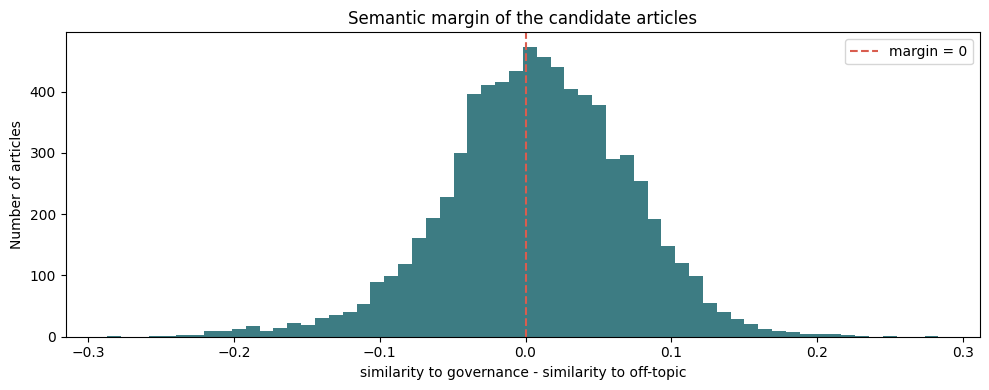


--- Q1 (lowest): margin -0.287 to -0.041 ---
-0.047  [industry_use   ] LumiQuant Academy Leads the Global Smart Trading Education Revolution with Quantyraxis AI, the 
-0.073  [market_report  ] OnlyFans in 2026: Is It Still Worth It for Gen Z Creators?
-0.195  [market_report  ] E-Learning Market Growth, Size, and Business Forecast 2026-2033
-0.046  [energy         ] New Smart Windows that are Self-Cleaning & Energy Efficient
-0.075  [industry_use   ] AI is Transforming Consumer Packaged Goods ( CPG): Are You Keeping Up?
-0.080  [market_report  ] Midyear update 2025 AI predictions: PwC
-0.062  [enterprise     ] Leona Health Raises $ 14M from a16z for WhatsApp AI Co-Pilot Aiding LatAm Doctors
-0.093  [market_report  ] KPMG Careers: Experienced Professionals

--- Q2: margin -0.040 to -0.007 ---
-0.033  [industry_use   ] Vendor Payment Automation
-0.026  [enterprise     ] Discussion with Professor Marina Jirotka, Human Centered Computing, University of Oxford
-0.011  [industry_use   ] Adva

gov_v2,False,True,All
in_stage1,,,
False,33759,1292,35051
True,9655,2738,12393
All,43414,4030,47444


In [15]:
cand = df[df["gov_lexical"]].copy()

# 1. Distribution of the semantic margin
plt.figure(figsize=(10, 4))
plt.hist(cand["sem_margin"], bins=60, color="#3D7C83")
plt.axvline(0, color="#D95D4F", linestyle="--", label="margin = 0")
plt.title("Semantic margin of the candidate articles")
plt.xlabel("similarity to governance - similarity to off-topic")
plt.ylabel("Number of articles")
plt.legend()
plt.tight_layout()
plt.show()

# 2. Random titles per margin quintile (from "clearly off-topic" to "clearly governance")
cand["margin_bin"] = pd.qcut(cand["sem_margin"], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
for bin_name, group in cand.groupby("margin_bin", observed=True):
    print(f"\n--- {bin_name}: margin {group['sem_margin'].min():.3f} to {group['sem_margin'].max():.3f} ---")
    for _, row in group.sample(n=8, random_state=RANDOM_STATE).iterrows():
        label = row["sem_gov_label"] if row["sem_margin"] > 0 else row["sem_off_label"]
        print(f"{row['sem_margin']:+.3f}  [{label:<15}] {str(row['title'])[:95]}")

# 3. Articles we discussed in the lexical step
CHECK_TITLES = ["Privacy notice", "Tesla Cybercab", "IoT on Manufacturing", "Laura Zommer",
                "SEO", "Copyright Office", "EU Fines Google", "AI safety amid Trump", "woke AI"]
print("\n--- Known examples ---")
for keyword in CHECK_TITLES:
    rows = cand[cand["title"].str.contains(keyword, regex=False, na=False)]
    for _, row in rows.head(2).iterrows():
        print(f"{row['sem_margin']:+.3f}  {str(row['title'])[:95]}")

# 4. Combined filter: lexical candidate AND positive semantic margin
df["gov_v2"] = df["gov_lexical"] & (df["sem_margin"] > 0)
print(f"\nCandidates (lexical):      {df['gov_lexical'].sum():,}")
print(f"Lexical + semantic (> 0):  {df['gov_v2'].sum():,}")
display(pd.crosstab(df["in_stage1"], df["gov_v2"], margins=True))

### Results of the semantic score (Pascal)

The semantic margin separates the candidates roughly, but not sharply: its standard deviation is only 0.063. A random sample per quintile shows:

- **Q1–Q2 (margin below −0.007):** almost only off-topic articles, e.g. market reports, trading software, a KPMG careers page and healthcare applications. The *"Privacy notice"* page (−0.177) and the IoT manufacturing guide (−0.071) are correctly removed.
- **Q3 (around 0):** mixed. Funding rounds of compliance startups and articles about AGI or quantum partnerships appear next to real governance articles such as the DOJ antitrust case.
- **Q4–Q5:** mostly governance articles, e.g. caste bias in OpenAI models, the Reddit vs. Perplexity lawsuit, the Digital Markets Act, the US Copyright Office report and Trump's AI Action Plan.

With a threshold of 0, the combined filter keeps **4,030 articles**: 2,738 from the Stage 1 corpus and 1,292 new ones. Some false positives remain, e.g. *"Tesla Cybercab Prototypes Tested in Austin"* (+0.053) and articles about AI and SEO.

We use this combination as the final topic filter (`gov_v2`): an article belongs to the governance corpus if it is a lexical candidate and has a positive semantic margin. Both the threshold of 0 and the combination of the two scores were set by hand.

## 1.2 Limitation: no quantitative evaluation of the topic filter (Pascal)

The Stage 1 feedback asked us to tighten **and evaluate** the topic filter. We tightened it (section 1.1), but we could not evaluate it quantitatively within the time of the project. The final filter `gov_v2` was chosen by qualitative checks only:

- random titles of the articles that the new filter removes, keeps and adds compared with Stage 1;
- random titles per quintile of the semantic margin;
- known examples of false positives (e.g. a website privacy notice, an IoT guide for manufacturing) and of relevant articles (e.g. the US Copyright Office report, the EU fine against Google).

These checks show that the new filter removes most of the politics, energy and enterprise articles named in the feedback, and that it adds relevant articles that the Stage 1 filter missed. They do **not** measure precision and recall. Some false positives remain, e.g. *"Tesla Cybercab Prototypes Tested in Austin for Robotaxi Launch"*, and we cannot say how many relevant articles the filter misses.

**Consequences for the following parts.** Off-topic articles in the corpus can be retrieved as passages and lower the quality of the answers. The retrieval and answer evaluation in Parts 3 and 5 therefore also measures the effect of the filter indirectly: a retrieved off-topic passage counts as a retrieval error.

**How the filter should be evaluated.** A stratified random sample of about 200 articles (quintiles of the semantic margin among the candidates, and articles that the filter rejects), labelled by two annotators with a written guideline. The strata are then weighted by the inverse of their sampling rate, so that precision and recall estimate the performance on the whole corpus, and Cohen's κ shows how consistent the labels are.

## 1.3 Splitting the articles into passages (Pascal)

The RAG system does not retrieve whole articles, but **passages**: our articles have a median of about 1,250 words, while embedding models can only read 512 tokens. Passages are also the unit for the relation extraction in section 1.4. Every relation in the knowledge graph therefore points to a passage that the RAG system can retrieve and cite. This makes the evidence of every relation traceable, which was a main problem of the Stage 1 extraction.

We split all **7,264 lexical candidates**, not only the final corpus. The final filter (`gov_v2`) can only remove candidates, so the final passages are a subset that we select later by `doc_id`.

**Text cleaning.** For RAG we use the original `content` and not `cleaned_text`: answers and entity names need upper and lower case and punctuation. We only apply light cleaning:

- repair wrong encodings with `ftfy` (e.g. *"Itâs"* → *"It's"*);
- remove HTML tags and URLs;
- remove spaces inside contractions (e.g. *"Office’ s"* → *"Office's"*), an artefact we found in many titles.

**Splitting.** We split the text into sentences with the spaCy `sentencizer` and combine consecutive sentences into passages of at most **180 words** (about 240 tokens). Neighbouring passages overlap by **one sentence**, so that information at a passage border is not lost.

**List format.** Some articles are stored as a Python list of paragraphs (`['First paragraph.', 'Second paragraph.']`). A first run left the separators `', '` inside the passages. We therefore convert these texts back into continuous text before splitting.

**Boilerplate.** In Stage 1 we found recurring source boilerplate (navigation texts, newsletter boxes, footers, job-posting templates). A first run that removed only identical *passages* missed boilerplate sentences inside otherwise relevant passages (e.g. *"Explore new launches, feature updates, and innovations from Rippling."*). We therefore remove boilerplate at the **sentence level**: a sentence that appears in **three or more articles of the same domain** is removed before the passages are built. We count per domain so that agency reports that several outlets publish are kept. Finally, we remove very short passages (under 25 words).

In [16]:
!pip install -q ftfy

import ast
import html
import ftfy
from collections import Counter


def join_list_content(text):
    """Some articles are stored as a Python list of paragraphs: "['First.', 'Second.']"."""
    stripped = str(text).strip()
    if not (stripped.startswith("['") or stripped.startswith('["')):
        return text
    try:
        parts = ast.literal_eval(stripped)
        if isinstance(parts, list):
            return " ".join(str(p) for p in parts)
    except (ValueError, SyntaxError):
        pass
    # Fallback for lists that cannot be parsed (e.g. truncated texts)
    stripped = stripped.strip("[]")
    return re.sub(r"""['"]\s*,\s*['"]""", " ", stripped).strip("'\" ")


def clean_for_rag(text):
    """Light cleaning for RAG: keep case and punctuation, repair encoding errors."""
    if not isinstance(text, str):
        return ""
    text = join_list_content(text)
    text = ftfy.fix_text(text)                                       # "Itâs" -> "It's"
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)                            # HTML tags
    text = re.sub(r"https?://\S+", " ", text)                       # URLs
    text = re.sub(r"(['’])\s+(s|t|re|ve|ll|d|m)\b", r"\1\2", text)  # "Office’ s" -> "Office's"
    text = re.sub(r"\s+", " ", text).strip()
    return text


# Test 1: titles with encoding problems
test_titles = df.loc[df["title"].str.contains("â|’ s|’ t", regex=True, na=False), "title"].head(3)
for title in test_titles:
    print(f"before: {title[:90]}")
    print(f"after:  {clean_for_rag(title)[:90]}\n")

# Test 2: an article in list format
list_example = df.loc[df["content"].astype(str).str.startswith("['"), "content"].iloc[0]
print(f"before: {list_example[:200]}")
print(f"after:  {clean_for_rag(list_example)[:200]}")

before: Celebrating student entrepreneurship at delta v’ s 2024 Demo Day
after:  Celebrating student entrepreneurship at delta v's 2024 Demo Day

before: IBM’ s Quantum-Centric Supercomputing Vision Is Coming
after:  IBM's Quantum-Centric Supercomputing Vision Is Coming

before: Open-source imagery is transforming investigations of international crimes – but how do ju
after:  Open-source imagery is transforming investigations of international crimes – but how do ju

before: ['With the field of AI accelerating all the time, keeping track of the developments can prove difficult.', "Luckily, certain companies, who's core offerings are made up of AI products, can sometimes s
after:  With the field of AI accelerating all the time, keeping track of the developments can prove difficult. Luckily, certain companies, who's core offerings are made up of AI products, can sometimes serve 


In [17]:
import spacy

PASSAGES_FILE = os.path.join(STAGE3_FOLDER, "passages_candidates_v2.parquet")
MAX_PASSAGE_WORDS = 180
OVERLAP_SENTENCES = 1
MIN_PASSAGE_WORDS = 25
BOILERPLATE_MIN_DOCS = 3   # same sentence in >= 3 articles of the same domain

nlp_sent = spacy.blank("en")
nlp_sent.add_pipe("sentencizer")
nlp_sent.max_length = 2_000_000


def get_sentences(spacy_doc):
    """Sentences of a document; very long 'sentences' (e.g. lists) are cut into pieces."""
    sentences = []
    for sent in spacy_doc.sents:
        words = sent.text.split()
        for i in range(0, len(words), MAX_PASSAGE_WORDS):
            sentences.append(" ".join(words[i:i + MAX_PASSAGE_WORDS]))
    return sentences


def build_passages(sentences):
    """Combine consecutive sentences into passages of at most MAX_PASSAGE_WORDS words."""
    passages, start = [], 0
    while start < len(sentences):
        current, n_words, end = [], 0, start
        while end < len(sentences) and (
            not current or n_words + len(sentences[end].split()) <= MAX_PASSAGE_WORDS
        ):
            current.append(sentences[end])
            n_words += len(sentences[end].split())
            end += 1
        passages.append(" ".join(current))
        if end >= len(sentences):
            break
        start = max(end - OVERLAP_SENTENCES, start + 1)   # overlap of one sentence
    return passages


def sentence_key(sentence):
    return re.sub(r"\W+", " ", sentence.lower()).strip()


candidates = df[df["gov_lexical"]]

if os.path.exists(PASSAGES_FILE):
    passages = pd.read_parquet(PASSAGES_FILE)
    print("Loaded passages from cache.")
else:
    # 1. Clean and split into sentences
    texts = [clean_for_rag(c) for c in tqdm(candidates["content"], desc="cleaning")]
    titles = [clean_for_rag(t) for t in candidates["title"]]
    sentence_lists = [
        get_sentences(d) for d in tqdm(nlp_sent.pipe(texts, batch_size=50),
                                       total=len(texts), desc="sentences")
    ]

    # 2. In how many articles of the same domain does each sentence occur?
    docs_per_sentence = Counter()
    for domain, sentences in zip(candidates["domain"], sentence_lists):
        for key in {sentence_key(s) for s in sentences}:
            docs_per_sentence[(domain, key)] += 1
    boilerplate_keys = {k for k, n in docs_per_sentence.items() if n >= BOILERPLATE_MIN_DOCS}

    # 3. Remove boilerplate sentences and build the passages
    rows, n_sentences, n_removed = [], 0, 0
    for doc_id, title, date, domain, url, sentences in zip(
        candidates.index, titles, candidates["published_at"],
        candidates["domain"], candidates["url"], sentence_lists
    ):
        kept = [s for s in sentences if (domain, sentence_key(s)) not in boilerplate_keys]
        n_sentences += len(sentences)
        n_removed += len(sentences) - len(kept)
        for k, text in enumerate(build_passages(kept)):
            rows.append({
                "passage_id": f"{doc_id}_{k:03d}", "doc_id": doc_id, "chunk_index": k,
                "title": title, "published_at": date, "domain": domain, "url": url, "text": text,
            })

    passages = pd.DataFrame(rows)
    passages["n_words"] = passages["text"].str.split().str.len()
    n_raw = len(passages)
    passages = passages[passages["n_words"] >= MIN_PASSAGE_WORDS].reset_index(drop=True)
    passages.to_parquet(PASSAGES_FILE, index=False)

    print(f"Sentences:                    {n_sentences:>9,}")
    print(f"Removed boilerplate sentences: {n_removed:>8,} ({n_removed / n_sentences:.1%})")
    print(f"Passages:                     {n_raw:>9,}")
    print(f"Removed as too short:         {n_raw - len(passages):>9,}")
    print(f"Final passages:               {len(passages):>9,}")

    # Most frequent boilerplate sentences
    top_boilerplate = sorted(
        ((n, domain, key) for (domain, key), n in docs_per_sentence.items() if n >= BOILERPLATE_MIN_DOCS),
        reverse=True
    )[:12]
    print("\nMost frequent boilerplate sentences (domain, articles, text):")
    for n, domain, key in top_boilerplate:
        print(f"  {domain:<15} {n:>4}  {key[:90]}")

# Check: no list separators left
n_left = passages["text"].str.contains(r"""['"], ['"]""", regex=True).sum()
print(f"\nPassages with remaining list separators: {n_left:,}")

Loaded passages from cache.

Passages with remaining list separators: 177


,articles,passages,median_passages_per_article,median_words_per_passage,max_words_per_passage
0,7247,72576,8.0,168.0,180


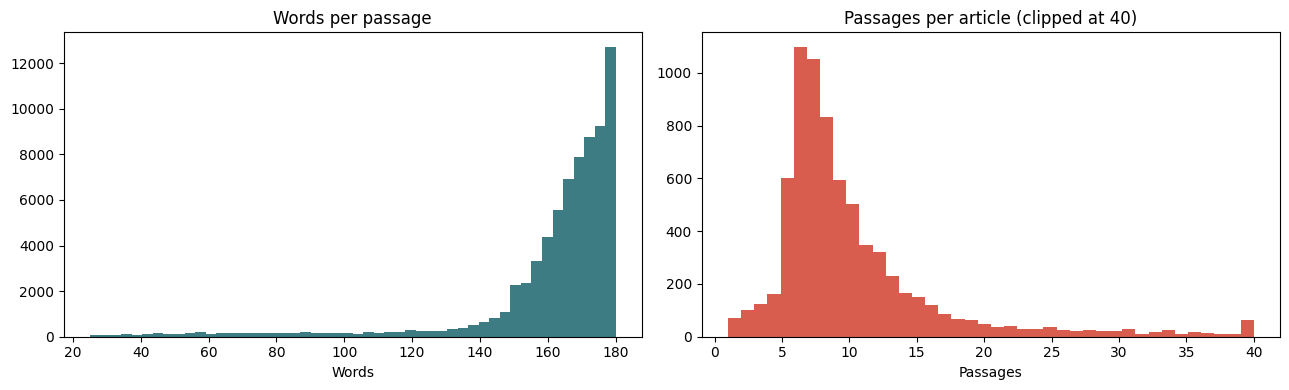

[20063_000] 2025-07-12 | Meta's Joel Kaplan: UK can lead in AI, if it avoids Brussels' failures
The UK is not alone in facing big economic challenges. Governments around the world are wrestling with vast
deficits, strains on public services, productivity crises and high prices. But crises can also be the jolt
that governments need to think and act big. The UK is better placed than most countries to establish itself as
a major AI power. It has a deep talent pool, world-leading universities and a long-standing culture of
innovation. But that won't count for much without strong political leadership. Sir Keir Starmer is certainly
talking the talk. He has called AI " the greatest force for change in the world right now " and laid out an
ambitious strategy to position the UK as an " AI maker, not an AI taker " by encouraging home-grown
innovation, investment in AI infrastructure and a transformation of the delivery of public services, such as
the NHS. 

[20063_001] 2025-07-12 | Meta's Joel K

In [18]:
passages_per_doc = passages.groupby("doc_id").size()

stats = pd.DataFrame({
    "articles": [passages["doc_id"].nunique()],
    "passages": [len(passages)],
    "median_passages_per_article": [passages_per_doc.median()],
    "median_words_per_passage": [passages["n_words"].median()],
    "max_words_per_passage": [passages["n_words"].max()],
})
display(stats)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.hist(passages["n_words"], bins=50, color="#3D7C83")
ax1.set_title("Words per passage")
ax1.set_xlabel("Words")
ax2.hist(passages_per_doc.clip(upper=40), bins=40, color="#D95D4F")
ax2.set_title("Passages per article (clipped at 40)")
ax2.set_xlabel("Passages")
plt.tight_layout()
plt.show()

# Example: the first three passages of one article
example_doc = passages["doc_id"].sample(1, random_state=RANDOM_STATE).iloc[0]
for _, row in passages[passages["doc_id"] == example_doc].head(3).iterrows():
    print(f"[{row['passage_id']}] {row['published_at']:%Y-%m-%d} | {row['title'][:70]}")
    print(textwrap.fill(row["text"], 110), "\n")

### Source check (Pascal)

The most frequent boilerplate passages come from a few sources: job postings on *builtin*, report templates on *skyquestt* and product text on *hiddenlayer*. In Stage 1 we already excluded *builtin*, *skyquestt* and *zbrain* from topic modeling, because they publish highly templated, non-journalistic content. These sources are still part of the RAG candidates, and removing the repeated passages does not change the character of these pages.

We therefore check the sources of the candidates: how many articles each domain contributes, how many of its passages were boilerplate, and how many of its texts are stored as a Python list (`['...`), which points to scraping artefacts.

In [19]:
STAGE1_EXCLUDED_DOMAINS = ["builtin", "skyquestt", "zbrain"]

candidates = df[df["gov_lexical"]]

domain_stats = candidates.groupby("domain").agg(
    articles=("title", "size"),
    list_format_share=("content", lambda s: s.astype(str).str.startswith("['").mean()),
)
domain_stats["passages"] = passages.groupby("domain").size()
domain_stats["passages_per_article"] = domain_stats["passages"] / domain_stats["articles"]
domain_stats = domain_stats.sort_values("articles", ascending=False)

print(f"Candidate articles: {len(candidates):,} from {len(domain_stats):,} domains\n")
print("Top 25 domains:")
display(domain_stats.head(25).round(2))

print("Domains excluded in Stage 1 (topic modeling):")
display(domain_stats.reindex(STAGE1_EXCLUDED_DOMAINS).round(2))

print("Domains with list-formatted content:")
display(domain_stats[domain_stats["list_format_share"] > 0.5].round(2))

# Random titles of the excluded and list-formatted sources
suspicious = STAGE1_EXCLUDED_DOMAINS + list(domain_stats[domain_stats["list_format_share"] > 0.5].index)
for domain in dict.fromkeys(suspicious):
    titles = candidates.loc[candidates["domain"] == domain, "title"]
    if len(titles) == 0:
        continue
    print(f"\n--- {domain} ({len(titles)} articles) ---")
    for title in titles.sample(n=min(5, len(titles)), random_state=RANDOM_STATE):
        print("  ", str(title)[:100])

Candidate articles: 7,264 from 288 domains

Top 25 domains:


,articles,list_format_share,passages,passages_per_article
domain,,,,
aijourn,476,1.00,3854,8.10
builtin,284,0.98,1911,6.73
kpmg,236,0.99,1768,7.49
theconversation,223,1.00,1603,7.19
skyquestt,189,0.97,2443,12.93
apnews,178,1.00,1754,9.85
zbrain,167,1.00,1312,7.86
ey,154,0.82,1571,10.20
aithority,151,1.00,1557,10.31


Domains excluded in Stage 1 (topic modeling):


,articles,list_format_share,passages,passages_per_article
domain,,,,
builtin,284,0.98,1911,6.73
skyquestt,189,0.97,2443,12.93
zbrain,167,1.00,1312,7.86


Domains with list-formatted content:


,articles,list_format_share,passages,passages_per_article
domain,,,,
aijourn,476,1.00,3854,8.10
builtin,284,0.98,1911,6.73
kpmg,236,0.99,1768,7.49
theconversation,223,1.00,1603,7.19
skyquestt,189,0.97,2443,12.93
...,...,...,...,...
smmt.co,1,1.00,8,8.00
spglobal,1,1.00,15,15.00
speedinvest,1,1.00,11,11.00



--- builtin (284 articles) ---
   How to Overcome Algorithmic Confirmation Bias
   Engineering Manager, Switchboard - GitLab
   4 New Year’ s Resolutions The AI Industry Needs in 2026
   Senior Backend Engineer, SSCS: Pipeline Security - GitLab
   What Is xAI? The Company Behind Grok

--- skyquestt (189 articles) ---
   ESD Face Shield Market Size, Share
   Middle School Market Size, Share
   Enterprise Data Management Market Growth Drivers, Trends, and Opportunities
   Cloud Managed Service Market Size, Share, and Regional Growth Insights 2026-2033
   Endpoint Security Market Size, Share, and Regional Outlook 2026-2033

--- zbrain (167 articles) ---
   GDPR Compliance Monitoring Agent
   RFQ Broadcast AI Agent
   RFQ Creation Agent
   Procurement Contract Compliance Agent
   Treasury Compliance Monitoring Agent

--- aijourn (476 articles) ---
   How Human Security Teams and AI Agents Work Together in Modern Security Operations
   How AI is Advancing Network Management System Developm

In [20]:
remaining = passages[passages["text"].str.contains(r"""['"], ['"]""", regex=True)]
print(remaining["domain"].value_counts().head(5), "\n")
for _, row in remaining.sample(n=2, random_state=RANDOM_STATE).iterrows():
    match = re.search(r"""['"], ['"]""", row["text"])
    print(f"[{row['passage_id']}] ...{row['text'][max(0, match.start() - 120):match.end() + 120]}...\n")

domain
skyquestt         73
algorithmwatch    12
hbr                5
metro.co           5
dev                5
Name: count, dtype: int64 

[6076_002] ... craft a effective strategy, organisations must focus on a need for an " obsessive focus on results and sharp execution ", " value first " principles and " future cases " to enhance scalability and imagine new possibilities. Becky Power, Managi...

[16838_001] ...obtain, monitor or store all or any part of the content or Site, including whether manually or by way of any ' bot/robot', ' spider', ' scraper' or other automated software, device, algorithm, code, methodology, tool, process or similar technol...



### Source exclusions (Pascal)

The source check showed three groups of domains:

1. **Sources that are structurally not news articles:** job postings (*builtin*, e.g. "Senior Backend Engineer – GitLab"), market report templates (*skyquestt*), product pages of AI agents (*zbrain*) and model cards (*huggingface*, e.g. "microsoft/phi-4"). These pages describe no event and have no meaningful publication date, so they are not suitable evidence for a time-aware RAG system. We exclude these four domains completely. Three of them were already excluded from topic modeling in Stage 1.
2. **Mixed sources** such as consultancies (KPMG, EY, PwC) or vendor blogs publish both relevant and irrelevant articles. We do not exclude them by domain. The article-level topic filter (`gov_v2`) decides for each article.
3. **Specialised sources** that are valuable for our track, e.g. *hiddenlayer* (AI security research), *partnershiponai*, *algorithmwatch* or *ai-regulation*, are kept.

We also found that almost all articles in the dataset are stored as a Python list of paragraphs, not only a few sources. The conversion to continuous text in section 1.3 therefore affects the whole corpus.

In [21]:
EXCLUDED_DOMAINS = {
    "builtin":     "job postings and company profiles (also excluded in Stage 1)",
    "skyquestt":   "market report templates (also excluded in Stage 1)",
    "zbrain":      "product pages of AI agents (also excluded in Stage 1)",
    "huggingface": "model cards and dataset pages",
}

df["excluded_source"] = df["domain"].isin(EXCLUDED_DOMAINS)

excluded_overview = pd.DataFrame({
    "reason": EXCLUDED_DOMAINS,
    "candidate_articles": df[df["gov_lexical"]].groupby("domain").size().reindex(list(EXCLUDED_DOMAINS)),
    "passages": passages.groupby("domain").size().reindex(list(EXCLUDED_DOMAINS)),
}).fillna(0)
display(excluded_overview)

n_cand = df["gov_lexical"].sum()
n_cand_kept = (df["gov_lexical"] & ~df["excluded_source"]).sum()
n_pass_kept = (~passages["domain"].isin(EXCLUDED_DOMAINS)).sum()
print(f"Candidate articles: {n_cand:,} -> {n_cand_kept:,} after source exclusion")
print(f"Passages:           {len(passages):,} -> {n_pass_kept:,} after source exclusion")

# The passage file stays complete; the exclusion is applied together with
# the topic filter (gov_v2) when we select the final corpus in section 1.7.

,reason,candidate_articles,passages
builtin,job postings and company profiles (also exclud...,284,1911
skyquestt,market report templates (also excluded in Stag...,189,2443
zbrain,product pages of AI agents (also excluded in S...,167,1312
huggingface,model cards and dataset pages,57,433


Candidate articles: 7,264 -> 6,567 after source exclusion
Passages:           72,576 -> 66,477 after source exclusion


## 1.4 Reproducible relation extraction with a controlled predicate schema (Gaël)

In Stage 1, LangExtract with `gemma3:4b` produced 998 relations with **421 distinct predicates**. Only 17 of 30 checked relations matched their source offsets, and after schema filtering only 29 relations remained. The Stage 1 feedback asked us to make the extraction **reproducible with a smaller, controlled predicate schema**. We changed four things:

1. **Smaller schema focused on governance.** The Stage 1 schema contained 8 entity types and general technology relations (e.g. `DEVELOPS`, `PARTNERS_WITH`). The new schema has **5 entity types and 9 predicates**. Every predicate describes a governance action and has a fixed **type signature** (allowed subject and object types).
2. **Schema enforced during generation.** The schema is not only described in the prompt: we pass it as a JSON schema to the model, which can then only generate predicates, entity types and type combinations of our schema.
3. **Passages as the extraction unit.** We extract from the passages of section 1.3, the same unit the RAG system retrieves. Every relation contains its `passage_id` and a **verbatim evidence quote**, which we check against the passage text.
4. **Reproducibility.** We use an open model with a recorded version, temperature 0 and a fixed seed. Every response is cached, so a second run gives exactly the same result.

### Schema definition (Gaël)

**Entity types**

| Type | Description | Examples |
|---|---|---|
| `LEGAL_INSTRUMENT` | Law, bill, regulation, executive order, code of practice, standard or official framework | EU AI Act, SB 53, GPAI Code of Practice, NIST AI RMF |
| `PUBLIC_AUTHORITY` | Government, legislature, regulator, agency, court or international organisation | European Commission, FTC, US Congress, Ofcom, UN |
| `ORGANIZATION` | Company, AI lab, NGO, publisher or industry association | OpenAI, Meta, The New York Times |
| `AI_SYSTEM` | Named AI model or AI product | ChatGPT, Grok, Claude, Llama |
| `PERSON` | Named individual | Gavin Newsom, Henna Virkkunen |

**Predicates**

| Predicate | Subject → Object | Meaning |
|---|---|---|
| `PROPOSES` | PUBLIC_AUTHORITY, PERSON → LEGAL_INSTRUMENT | drafts, introduces or proposes |
| `ADOPTS` | PUBLIC_AUTHORITY, PERSON → LEGAL_INSTRUMENT | passes, enacts, signs into law, formally publishes |
| `ENFORCES` | PUBLIC_AUTHORITY → LEGAL_INSTRUMENT | is responsible for or applies the enforcement of |
| `APPLIES_TO` | LEGAL_INSTRUMENT → ORGANIZATION, AI_SYSTEM | imposes obligations on, covers |
| `INVESTIGATES_OR_SANCTIONS` | PUBLIC_AUTHORITY → ORGANIZATION, AI_SYSTEM | investigates, fines, bans or orders |
| `SUES` | ORGANIZATION, PERSON, PUBLIC_AUTHORITY → ORGANIZATION | files a lawsuit against |
| `COMPLIES_WITH` | ORGANIZATION → LEGAL_INSTRUMENT | signs, commits to or complies with |
| `SUPPORTS` | ORGANIZATION, PERSON, PUBLIC_AUTHORITY → LEGAL_INSTRUMENT | publicly endorses or lobbies for |
| `OPPOSES` | ORGANIZATION, PERSON, PUBLIC_AUTHORITY → LEGAL_INSTRUMENT | criticises, refuses, vetoes, challenges or lobbies against |

Every relation also has a **modality**: `actual` (it happened) or `planned` (announced or intended). For questions such as "When did the EU adopt the AI Act?", it matters whether something was done or only announced.

In [22]:
L, A, O, S, P = "LEGAL_INSTRUMENT", "PUBLIC_AUTHORITY", "ORGANIZATION", "AI_SYSTEM", "PERSON"

KG_SCHEMA = {
    "version": "stage3_v1",
    "entity_types": {
        L: "Law, bill, regulation, executive order, code of practice, standard or official framework",
        A: "Government, legislature, regulator, agency, court or international organisation",
        O: "Company, AI lab, NGO, publisher or industry association",
        S: "Named AI model or AI product",
        P: "Named individual",
    },
    "predicates": {
        "PROPOSES":                  {"subject": [A, P],    "object": [L],    "meaning": "drafts, introduces or proposes"},
        "ADOPTS":                    {"subject": [A, P],    "object": [L],    "meaning": "passes, enacts, signs into law, formally publishes"},
        "ENFORCES":                  {"subject": [A],       "object": [L],    "meaning": "is responsible for or applies the enforcement of"},
        "APPLIES_TO":                {"subject": [L],       "object": [O, S], "meaning": "imposes obligations on, covers"},
        "INVESTIGATES_OR_SANCTIONS": {"subject": [A],       "object": [O, S], "meaning": "investigates, fines, bans or orders"},
        "SUES":                      {"subject": [O, P, A], "object": [O],    "meaning": "files a lawsuit against"},
        "COMPLIES_WITH":             {"subject": [O],       "object": [L],    "meaning": "signs, commits to or complies with"},
        "SUPPORTS":                  {"subject": [O, P, A], "object": [L],    "meaning": "publicly endorses or lobbies for"},
        "OPPOSES":                   {"subject": [O, P, A], "object": [L],    "meaning": "criticises, refuses, vetoes, challenges or lobbies against"},
    },
    "modalities": ["actual", "planned"],
}

ENTITY_TYPES = list(KG_SCHEMA["entity_types"])
PREDICATES = list(KG_SCHEMA["predicates"])

# Save the schema as part of our data dictionary
SCHEMA_FILE = os.path.join(STAGE3_FOLDER, "kg_schema_stage3.json")
with open(SCHEMA_FILE, "w", encoding="utf-8") as f:
    json.dump(KG_SCHEMA, f, indent=2)

print(f"{len(ENTITY_TYPES)} entity types, {len(PREDICATES)} predicates -> saved to {SCHEMA_FILE}")
pd.DataFrame([
    {"predicate": p, "subject": " | ".join(v["subject"]), "object": " | ".join(v["object"]), "meaning": v["meaning"]}
    for p, v in KG_SCHEMA["predicates"].items()
])

5 entity types, 9 predicates -> saved to /content/drive/MyDrive/NLP_Projekt/stage3/kg_schema_stage3.json


,predicate,subject,object,meaning
0,PROPOSES,PUBLIC_AUTHORITY | PERSON,LEGAL_INSTRUMENT,"drafts, introduces or proposes"
1,ADOPTS,PUBLIC_AUTHORITY | PERSON,LEGAL_INSTRUMENT,"passes, enacts, signs into law, formally publi..."
2,ENFORCES,PUBLIC_AUTHORITY,LEGAL_INSTRUMENT,is responsible for or applies the enforcement of
3,APPLIES_TO,LEGAL_INSTRUMENT,ORGANIZATION | AI_SYSTEM,"imposes obligations on, covers"
4,INVESTIGATES_OR_SANCTIONS,PUBLIC_AUTHORITY,ORGANIZATION | AI_SYSTEM,"investigates, fines, bans or orders"
5,SUES,ORGANIZATION | PERSON | PUBLIC_AUTHORITY,ORGANIZATION,files a lawsuit against
6,COMPLIES_WITH,ORGANIZATION,LEGAL_INSTRUMENT,"signs, commits to or complies with"
7,SUPPORTS,ORGANIZATION | PERSON | PUBLIC_AUTHORITY,LEGAL_INSTRUMENT,publicly endorses or lobbies for
8,OPPOSES,ORGANIZATION | PERSON | PUBLIC_AUTHORITY,LEGAL_INSTRUMENT,"criticises, refuses, vetoes, challenges or lob..."


### Selection of passages for extraction (Gaël)

Most passages contain no governance relation at all, e.g. introductions or background explanations. Sending them to the LLM would only cost time. We therefore pre-select passages with three simple rules:

1. 1. The article is in the **governance corpus** (lexical candidate, positive semantic margin, not an excluded source).
2. The passage mentions at least one **legal instrument** (e.g. "... Act", "Executive Order", "Code of Practice", "SB 53") **and** at least one **public authority or organisation** (e.g. "Commission", "FTC", "Congress", "court", or a known AI company).
3. The passage contains a **trigger verb** for one of our predicates (e.g. *passed, signed, proposed, fined, sued, comply, oppose*).

From the eligible passages we draw **25 per month** (about 600 for 24 months) with a fixed random seed. This way the extraction covers the whole observation period and is not dominated by the peak months. Stage 1 used the same principle with 25 articles per month.

In [24]:
PASSAGES_PER_MONTH = 25

# 1. Legal instruments: generic patterns (case-sensitive, the text keeps its upper case)
LEGAL_PATTERN = re.compile(
    r"\b(?:[A-Z][\w.'-]*\s){0,5}(?:Act|Bill|Directive|Regulation|Executive Order|Code of Practice|"
    r"Framework|Convention|Treaty|Action Plan)\b"
    r"|\b(?:SB|AB|HB|S\.|H\.R\.)\s?\d{1,5}\b"
    r"|\b(?:GDPR|DSA|DMA|AI Act|NIST AI RMF|ISO/IEC 42001|ISO 42001)\b"
)

# 2. Public authorities and organisations
ACTOR_PATTERN = re.compile(
    r"\b(?:Commission|Parliament|Council|Congress|Senate|House|White House|Administration|Government|"
    r"Ministry|Department|Agency|Authority|Regulator|Court|Judge|Attorney General|Governor|President|"
    r"FTC|SEC|FCC|DOJ|NIST|CAISI|Ofcom|CNIL|Garante|ICO|AI Office|AI (?:Safety|Security) Institute|"
    r"United Nations|OECD|UNESCO|G7|"
    r"OpenAI|Anthropic|Google|DeepMind|Meta|Microsoft|Apple|Amazon|Nvidia|xAI|Mistral|DeepSeek|"
    r"TikTok|ByteDance|IBM|Perplexity|Stability AI|Midjourney|Character\.AI)\b"
)

# 3. Trigger verbs for our predicates
TRIGGER_PATTERN = re.compile(
    r"\b(?:propos\w*|introduc\w*|draft\w*|pass(?:ed|es)?|adopt\w*|enact\w*|sign(?:ed|s|ing)?|approv\w*|"
    r"publish\w*|enforc\w*|appl(?:y|ies|ied)|fin(?:ed|es)|investigat\w*|prob(?:e|ed|es|ing)|ban(?:s|ned)?|"
    r"order(?:ed|s)?|su(?:e|ed|es|ing)|lawsuit|compl(?:y|ies|ied|iance)|commit\w*|endors\w*|back(?:ed|s)?|"
    r"support\w*|oppos\w*|criticiz\w*|criticis\w*|challeng\w*|lobb\w*|veto\w*|block\w*)\b",
    re.IGNORECASE,
)

# Governance corpus: topic filter gov_v2 without the excluded sources
governance_docs = df.index[df["gov_v2"] & ~df["excluded_source"]]
pool = passages[passages["doc_id"].isin(governance_docs)].copy()

pool["n_legal"] = pool["text"].str.count(LEGAL_PATTERN)
pool["n_actor"] = pool["text"].str.count(ACTOR_PATTERN)
pool["has_trigger"] = pool["text"].str.contains(TRIGGER_PATTERN)
pool["eligible"] = (pool["n_legal"] >= 1) & (pool["n_actor"] >= 1) & pool["has_trigger"]
pool["month"] = pool["published_at"].dt.to_period("M").astype(str)

eligible = pool[pool["eligible"]]
print(f"Passages of the governance corpus:  {len(pool):,}")
print(f"Eligible for extraction:            {len(eligible):,} ({len(eligible) / len(pool):.1%})")

# 25 passages per month, reproducible: shuffle once, then take the first 25 per month
extraction_set = (
    eligible.sample(frac=1, random_state=RANDOM_STATE)
    .groupby("month")
    .head(PASSAGES_PER_MONTH)
    .sort_values("passage_id")
    .reset_index(drop=True)
)
print(f"Selected for extraction:            {len(extraction_set):,} passages "
      f"from {extraction_set['doc_id'].nunique():,} articles\n")

display(extraction_set.groupby("month").size().rename("passages").to_frame().T)

# Two examples
for _, row in extraction_set.sample(n=2, random_state=RANDOM_STATE).iterrows():
    print(f"\n[{row['passage_id']}] {row['published_at']:%Y-%m-%d} | {row['title'][:80]}")
    print(textwrap.fill(row["text"], 110))

Passages of the governance corpus:  37,786
Eligible for extraction:            1,670 (4.4%)
Selected for extraction:            598 passages from 417 articles



month,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,...,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
passages,23,25,25,25,25,25,25,25,25,25,...,25,25,25,25,25,25,25,25,25,25



[1815_000] 2024-10-14 | Breaking Down the Arguments for and against U.S. Antitrust Legislation
In many areas of the world, including the European Union, United Kingdom, South Korea, and Australia,
governments are considering new legislation to check the market power of a few dominant technology platforms.
Yet some of the most sweeping proposals are taking place within the U.S. Congress. In October 2020, the
majority staff of the House Subcommittee on Antitrust, Commercial, and Administrative Law published a set of
recommendations to promote competition in technology markets, the result of a 16-month investigation that
directed attention to the actions of Alphabet ( the parent company of Google), Amazon, Apple, and Facebook (
now Meta). The House Judiciary Committee advanced six bills in June 2021 that paralleled many of these
recommendations, focusing on the anticompetitive impacts of self-preferencing, mergers and acquisitions, data
accumulation, and network effects related to digita

### Extraction with an open model and an enforced JSON schema (Gaël)

**Why not the Gemini API?** We first tested the free tier of the Gemini API. It was not usable for this task: the daily request limit was reached after a few requests, and many requests failed because of server overload (error 503). In Stage 1 the token limit had also been reached immediately. We therefore run an **open model locally on the Colab GPU** with **Ollama**. This has two further advantages: there are no rate limits, and the exact model version (the Ollama *digest*) can be recorded, so nobody can replace the model behind a name.

**Model.** We use **Qwen3** (4-bit quantised) on a T4 GPU, with the "thinking" mode switched off. Qwen3 is one of the compact open model families of Stage 2. In Stage 1 we used `gemma3:4b`, which did not follow the schema.

**Enforced schema.** We pass our response schema as a JSON schema to Ollama (`format=`). Ollama restricts the generation to this schema:

- The schema contains **one variant per predicate** with only its allowed subject and object types. Invalid type combinations, e.g. a law as the object of `INVESTIGATES_OR_SANCTIONS`, cannot be generated.
- The **order of the fields** is the order of generation. The model first copies the **evidence** sentence, then determines **subject, object and their types**, and only then the **predicate**. At this point the schema only allows predicates that fit the chosen types. Copying the evidence first makes the model derive the relation from the text instead of inventing it.
- The schema allows at most 20 relations per batch and 300 characters per evidence quote.

**Prompt.** We send the passages in **batches of 10**. The prompt contains the entity types, the predicates with their type signatures, our extraction rules and **three invented examples** (a fictional country, company and politicians): relations of an authority, a person and a company, a passage **without** any relation, and a veto. We do not use passages from our corpus as examples, so that the examples do not leak into the results.

**Reproducibility.** Temperature 0, a fixed seed, a fixed prompt version and the recorded model digest. Every response is cached on Google Drive. The cache key contains the model, its digest, the prompt version and the passage texts, so every change automatically leads to a new extraction.

**Development of the prompt.** We tested every version on the same batch of 10 passages:

- **v1** (simple schema, one example): `qwen3:8b` extracted more than 40 relations from 10 passages. The answer was cut off, and many relations were wrong, e.g. *Gavin Newsom ENFORCES SB 1047* (he vetoed it) or *Trump administration INVESTIGATES_OR_SANCTIONS Digital Services Act* (the object of this predicate must be an organisation).
- **v2** (one variant per predicate, length limits, negative example): 2 relations. When the model chose a wrong predicate first, the schema forced it to choose a wrong type as well (*SB 1047* was typed as an organisation).
- **v3** (types before predicate, examples for a person and a veto, names without titles): 3 relations with correct types, e.g. *Gavin Newsom OPPOSES Safe and Secure Innovation for Frontier AI Models Act*.

**Choice of the model.** We compared `qwen3:8b` and `qwen3:14b` with prompt v3 on the same test batch. Both found 3 relations. Both found *Gavin Newsom OPPOSES Senate Bill 1047* and the borderline case *Trump administration OPPOSES Digital Services Act*. The third relation of `qwen3:8b` (*EU Commission PROPOSES Digital Services Act*) was acceptable. The third relation of `qwen3:14b` had an unnamed group as subject (*"U.S. politicians"*). The test is too small to show a clear difference, and both models missed a criticism of the AI Act by a Meta manager. We use `qwen3:14b`: larger models usually follow instructions more reliably across many different passages, and the longer runtime (about 70 instead of 35 minutes) is needed only once because of the cache. Relations with generic names are removed by an additional automatic check.

In [25]:
import shutil
import subprocess

# Install Ollama only if it is not installed yet
if shutil.which("ollama") is None:
    !apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1
!pip install -q ollama

import ollama

OLLAMA_LOG_FILE = "/content/ollama_server.log"


def ollama_running():
    try:
        ollama.list()
        return True
    except Exception:
        return False


def start_ollama_server():
    """Start the Ollama server in the background; its log is written to OLLAMA_LOG_FILE."""
    log = open(OLLAMA_LOG_FILE, "a")
    subprocess.Popen(["ollama", "serve"], stdout=log, stderr=subprocess.STDOUT)
    for _ in range(30):
        if ollama_running():
            return True
        time.sleep(1)
    return False


if not ollama_running():
    start_ollama_server()

print("Ollama installed:", shutil.which("ollama"))
print("Ollama server running:", ollama_running())

Ollama installed: /usr/local/bin/ollama
Ollama server running: True


In [26]:
EXTRACTION_MODEL = "qwen3:14b"   # comparison test; alternative: "qwen3:8b"

# Download the model and show the progress
last_status, last_percent = None, -10
for progress in ollama.pull(EXTRACTION_MODEL, stream=True):
    if progress.total and progress.completed:
        percent = 100 * progress.completed / progress.total
        if progress.status != last_status or percent - last_percent >= 10:
            print(f"{progress.status[:40]:<40} {percent:5.0f}%")
            last_status, last_percent = progress.status, percent
    elif progress.status != last_status:
        print(progress.status)
        last_status, last_percent = progress.status, -10

# Exact model version, so the extraction can be reproduced with the same weights
model_digest = next(m.digest for m in ollama.list().models if m.model == EXTRACTION_MODEL)
print(f"\nModel: {EXTRACTION_MODEL} | digest: {model_digest[:12]}")
!nvidia-smi --query-gpu=name,memory.total --format=csv

pulling manifest
pulling a8cc1361f314
pulling a8cc1361f314                         0%
pulling a8cc1361f314                        10%
pulling a8cc1361f314                        20%
pulling a8cc1361f314                        30%
pulling a8cc1361f314                        40%
pulling a8cc1361f314                        50%
pulling a8cc1361f314                        61%
pulling a8cc1361f314                        71%
pulling a8cc1361f314                        81%
pulling a8cc1361f314                        91%
pulling ae370d884f10
pulling d18a5cc71b84
pulling cff3f395ef37
pulling 78b3b822087d                       100%
verifying sha256 digest
writing manifest
success

Model: qwen3:14b | digest: bdbd181c33f2
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [27]:
from typing import Annotated, List, Literal, Union
from pydantic import BaseModel, Field, create_model

PROMPT_VERSION = "v3"
BATCH_SIZE = 10
MAX_RELATIONS_PER_BATCH = 20

ModalityLiteral = Literal[tuple(KG_SCHEMA["modalities"])]
ShortName = Annotated[str, Field(max_length=80)]
Evidence = Annotated[str, Field(max_length=300)]

# One relation model per predicate, with only the allowed subject and object types.
# Order of the fields = order of generation:
#   1. evidence (the model copies the sentence first),
#   2. subject, object and their types (easy to recognise),
#   3. predicate: the schema only allows predicates that fit the chosen types.
relation_models = []
for predicate, spec in KG_SCHEMA["predicates"].items():
    relation_models.append(create_model(
        f"Relation_{predicate}",
        passage_id=(str, ...),
        evidence=(Evidence, ...),
        subject=(ShortName, ...),
        subject_type=(Literal[tuple(spec["subject"])], ...),
        object=(ShortName, ...),
        object_type=(Literal[tuple(spec["object"])], ...),
        predicate=(Literal[predicate], ...),
        modality=(ModalityLiteral, ...),
    ))


class ExtractionResult(BaseModel):
    relations: Annotated[List[Union[tuple(relation_models)]], Field(max_length=MAX_RELATIONS_PER_BATCH)]


RESPONSE_SCHEMA = ExtractionResult.model_json_schema()

# Prompt
entity_type_lines = "\n".join(f"- {t}: {d}" for t, d in KG_SCHEMA["entity_types"].items())
predicate_lines = "\n".join(
    f"- {p}: {' | '.join(v['subject'])} -> {' | '.join(v['object'])} ({v['meaning']})"
    for p, v in KG_SCHEMA["predicates"].items()
)

EXAMPLE_PASSAGES = (
    "[EX_1] (published 2025-03-04) The Freedonian Parliament passed the Robot Liability Act on Monday, "
    "and Prime Minister Jane Doe signed it into law on Friday. Acme AI said it would challenge the law "
    "in court. The Freedonian Data Authority also fined Acme AI 2 million euros over its chatbot Acmebot.\n\n"
    "[EX_2] (published 2025-05-10) Critics say the Robot Liability Act could slow innovation. "
    "The act would have required audits for large models, and regulators would have enforced it.\n\n"
    "[EX_3] (published 2025-09-30) Governor Tom Roe of Westland vetoed the Drone Privacy Bill on Sunday."
)
EXAMPLE_OUTPUT = json.dumps({"relations": [
    {"passage_id": "EX_1", "evidence": "The Freedonian Parliament passed the Robot Liability Act on Monday",
     "subject": "Freedonian Parliament", "subject_type": "PUBLIC_AUTHORITY",
     "object": "Robot Liability Act", "object_type": "LEGAL_INSTRUMENT",
     "predicate": "ADOPTS", "modality": "actual"},
    {"passage_id": "EX_1", "evidence": "Prime Minister Jane Doe signed it into law on Friday",
     "subject": "Jane Doe", "subject_type": "PERSON",
     "object": "Robot Liability Act", "object_type": "LEGAL_INSTRUMENT",
     "predicate": "ADOPTS", "modality": "actual"},
    {"passage_id": "EX_1", "evidence": "Acme AI said it would challenge the law in court.",
     "subject": "Acme AI", "subject_type": "ORGANIZATION",
     "object": "Robot Liability Act", "object_type": "LEGAL_INSTRUMENT",
     "predicate": "OPPOSES", "modality": "planned"},
    {"passage_id": "EX_1", "evidence": "The Freedonian Data Authority also fined Acme AI 2 million euros",
     "subject": "Freedonian Data Authority", "subject_type": "PUBLIC_AUTHORITY",
     "object": "Acme AI", "object_type": "ORGANIZATION",
     "predicate": "INVESTIGATES_OR_SANCTIONS", "modality": "actual"},
    {"passage_id": "EX_3", "evidence": "Governor Tom Roe of Westland vetoed the Drone Privacy Bill on Sunday.",
     "subject": "Tom Roe", "subject_type": "PERSON",
     "object": "Drone Privacy Bill", "object_type": "LEGAL_INSTRUMENT",
     "predicate": "OPPOSES", "modality": "actual"},
]})

PROMPT_TEMPLATE = f"""You extract AI-governance relations from news passages.

Entity types:
{entity_type_lines}

Predicates (allowed subject types -> allowed object types):
{predicate_lines}

Rules:
1. Extract a relation only if a sentence states that a named actor DID or WILL DO the action.
   Do not use background knowledge.
2. Do NOT extract: what a law would do or could do, opinions of unnamed groups ("critics", "experts"),
   descriptions of how institutions work in general, or recommendations of the author.
3. subject and object must be specific named entities. Write names without titles or job descriptions
   ("Gavin Newsom", not "California Governor Gavin Newsom"). If the passage says "the law" or
   "the company", use the name it refers to in the same passage.
4. A named person (e.g. a governor, president, minister or manager) is a PERSON, not a PUBLIC_AUTHORITY.
   A law, bill or regulation is always a LEGAL_INSTRUMENT.
5. evidence: copy the ONE shortest sentence or clause that states the relation, word for word.
6. modality: "actual" if it already happened, "planned" if it is announced, intended or expected.
7. Many passages contain no relation. Extract at most 3 relations per passage.

Example (EX_2 contains no relation):
{EXAMPLE_PASSAGES}
Output:
{EXAMPLE_OUTPUT}

Passages:
{{passages}}

Answer only with JSON in the format of the example.
"""


def build_prompt(batch):
    passage_lines = "\n\n".join(
        f"[{row.passage_id}] (published {row.published_at:%Y-%m-%d}) {row.text}"
        for row in batch.itertuples()
    )
    return PROMPT_TEMPLATE.replace("{passages}", passage_lines)


def batch_key(batch):
    content = json.dumps([EXTRACTION_MODEL, model_digest, PROMPT_VERSION,
                          list(batch["passage_id"]), list(batch["text"])])
    return hashlib.md5(content.encode()).hexdigest()


batches = [extraction_set.iloc[i:i + BATCH_SIZE] for i in range(0, len(extraction_set), BATCH_SIZE)]
print(f"{len(extraction_set)} passages -> {len(batches)} batches of up to {BATCH_SIZE}")

598 passages -> 60 batches of up to 10


**Extension to all eligible passages.** The first run used 25 passages per month (598 passages). After all filters, only 92 relations remained, and a few entities dominated the graph (e.g. Gavin Newsom with 13 relations). For graph-enhanced retrieval we need a denser graph, so we extend the extraction to **all 1,670 eligible passages**. The first 598 passages keep their batches, so their cached answers are reused, and only the additional passages are sent to the model. The additional passages are not balanced by month: months with more governance coverage contribute more relations. For temporal analyses we therefore look at relative shares, not absolute counts.

In [28]:
EXTEND_EXTRACTION = True

if EXTEND_EXTRACTION:
    # Additional passages: all eligible passages that are not in the first sample
    extra_set = (
        eligible[~eligible["passage_id"].isin(extraction_set["passage_id"])]
        .sort_values("passage_id")
        .reset_index(drop=True)
    )
    extra_batches = [extra_set.iloc[i:i + BATCH_SIZE] for i in range(0, len(extra_set), BATCH_SIZE)]

    # The first batches stay identical -> their answers come from the cache
    batches = batches + extra_batches
    extraction_set = pd.concat([extraction_set, extra_set], ignore_index=True)

print(f"Passages for extraction: {len(extraction_set):,} in {len(batches)} batches")

Passages for extraction: 1,670 in 168 batches


In [29]:
EXTRACTION_CACHE_FILE = os.path.join(STAGE3_FOLDER, "extraction_cache_ollama.jsonl")
MAX_BATCHES = None     # None = all batches; 1 = test mode
MAX_ATTEMPTS = 3

OLLAMA_OPTIONS = {
    "temperature": 0,
    "seed": RANDOM_STATE,
    "num_ctx": 8192,       # enough for the prompt with 10 passages
    "num_predict": 4096,   # maximum length of the answer
}


def load_extraction_cache():
    cache = {}
    if os.path.exists(EXTRACTION_CACHE_FILE):
        with open(EXTRACTION_CACHE_FILE, encoding="utf-8") as f:
            for line in f:
                record = json.loads(line)
                cache[record["batch_key"]] = record
    return cache


def request_batch(batch):
    response = ollama.chat(
        model=EXTRACTION_MODEL,
        messages=[{"role": "user", "content": build_prompt(batch)}],
        format=RESPONSE_SCHEMA,
        think=False,           # Qwen3: no reasoning tokens, only the JSON answer
        options=OLLAMA_OPTIONS,
    )
    return response.message.content


def request_with_retry(batch):
    """If the model runner crashes (e.g. GPU memory), Ollama restarts it with the next request."""
    for attempt in range(1, MAX_ATTEMPTS + 1):
        try:
            return request_batch(batch)
        except (ollama.ResponseError, ConnectionError) as e:
            print(f"  attempt {attempt}/{MAX_ATTEMPTS} failed: {str(e)[:100]}")
            if not ollama_running():
                start_ollama_server()
            time.sleep(15)
    return None


extraction_cache = load_extraction_cache()
todo = [b for b in batches if batch_key(b) not in extraction_cache]
n_cached = len(batches) - len(todo)
if MAX_BATCHES is not None:
    todo = todo[:MAX_BATCHES]
print(f"Batches: {len(batches)} | cached: {n_cached} | to process now: {len(todo)}")

failed_batches = []
for batch in tqdm(todo, desc="extraction"):
    raw = request_with_retry(batch)
    if raw is None:
        failed_batches.append(batch["passage_id"].iloc[0])
        continue
    record = {
        "batch_key": batch_key(batch), "model": EXTRACTION_MODEL, "model_digest": model_digest,
        "prompt_version": PROMPT_VERSION, "passage_ids": list(batch["passage_id"]), "response": raw,
    }
    with open(EXTRACTION_CACHE_FILE, "a", encoding="utf-8") as f:
        f.write(json.dumps(record) + "\n")
    extraction_cache[record["batch_key"]] = record

if failed_batches:
    print(f"\n{len(failed_batches)} batches failed (first passage: {failed_batches}). "
          "Run the cell again to retry them.")

# Flatten all cached responses of the current batches into one table
rows, n_invalid = [], 0
for batch in batches:
    record = extraction_cache.get(batch_key(batch))
    if record is None:
        continue
    try:
        rows.extend(json.loads(record["response"]).get("relations", []))
    except json.JSONDecodeError:
        n_invalid += 1   # e.g. answer cut off at num_predict

relations_raw = pd.DataFrame(rows)
print(f"\nBatches done: {sum(batch_key(b) in extraction_cache for b in batches)} / {len(batches)}")
print(f"Invalid JSON answers: {n_invalid}")
print(f"Raw relations: {len(relations_raw)}")
!ollama ps

Batches: 168 | cached: 168 | to process now: 0


extraction: 0it [00:00, ?it/s]


Batches done: 168 / 168
Invalid JSON answers: 0
Raw relations: 720
NAME    ID    SIZE    PROCESSOR    CONTEXT    RUNNER    UNTIL 


### Automatic checks of the extracted relations (Gaël)

The JSON schema guarantees valid predicates, entity types and type signatures, but not that a relation is supported by its passage. We therefore check every relation automatically:

1. **Known passage:** the `passage_id` must belong to the passages sent to the model.
2. **Evidence found:** the evidence quote must appear in the passage, word for word. We compare lowercase texts without punctuation and allow small differences (fuzzy match ≥ 90).
3. **Arguments grounded:** subject and object must appear in the passage (fuzzy match ≥ 90). This catches entities that the model adds from background knowledge.
4. **Valid type signature:** a second check of the schema rule (it should always pass).
5. **Specific names:** subject and object must not be generic groups such as "U.S. politicians", "lawmakers" or "tech companies". The prompt forbids them, but the model still returned one in a test.

Only relations that pass all five checks are kept for the knowledge graph. In section 1.5 we then validate the important relations against their passages.

In [30]:
!pip install -q rapidfuzz
from rapidfuzz import fuzz

FUZZY_THRESHOLD = 90
passage_text = passages.set_index("passage_id")["text"]

# Generic groups that are not specific named entities
GENERIC_NAME_PATTERN = re.compile(
    r"^(?:the\s+)?(?:u\.?s\.?|us|eu|european|american|chinese|state|federal|some|many|other)?\s*"
    r"(?:politicians?|lawmakers?|legislators?|regulators?|officials?|governments?|authorities|"
    r"companies|firms|tech companies|tech firms|big tech|developers?|providers?|platforms?|"
    r"critics|experts|users|states|countries|member states)$",
    re.IGNORECASE,
)


def normalize_for_match(text):
    return re.sub(r"\W+", " ", str(text).lower()).strip()


def check_relations(relations, sent_passage_ids):
    checked = relations.copy()
    norm_texts = checked["passage_id"].map(passage_text).fillna("").map(normalize_for_match)

    checked["known_passage"] = checked["passage_id"].isin(sent_passage_ids)
    checked["evidence_found"] = [
        fuzz.partial_ratio(normalize_for_match(e), t) >= FUZZY_THRESHOLD
        for e, t in zip(checked["evidence"], norm_texts)
    ]
    checked["subject_found"] = [
        fuzz.partial_ratio(normalize_for_match(s), t) >= FUZZY_THRESHOLD
        for s, t in zip(checked["subject"], norm_texts)
    ]
    checked["object_found"] = [
        fuzz.partial_ratio(normalize_for_match(o), t) >= FUZZY_THRESHOLD
        for o, t in zip(checked["object"], norm_texts)
    ]
    checked["specific_names"] = ~(
        checked["subject"].str.strip().str.match(GENERIC_NAME_PATTERN)
        | checked["object"].str.strip().str.match(GENERIC_NAME_PATTERN)
    )
    checked["signature_valid"] = [
        st in KG_SCHEMA["predicates"][p]["subject"] and ot in KG_SCHEMA["predicates"][p]["object"]
        for p, st, ot in zip(checked["predicate"], checked["subject_type"], checked["object_type"])
    ]
    check_columns = ["known_passage", "evidence_found", "subject_found", "object_found",
                     "specific_names", "signature_valid"]
    checked["passed_checks"] = checked[check_columns].all(axis=1)
    return checked, check_columns


relations_checked, CHECK_COLUMNS = check_relations(relations_raw, set(extraction_set["passage_id"]))

print("Relations passing each check:")
display(relations_checked[CHECK_COLUMNS + ["passed_checks"]].sum().to_frame("relations"))
print("Predicates of the relations that passed all checks:")
display(relations_checked.loc[relations_checked["passed_checks"], "predicate"].value_counts().to_frame())

# Full view of up to 10 random relations for the manual check
sample = relations_checked.sample(n=min(10, len(relations_checked)), random_state=RANDOM_STATE)
for _, r in sample.iterrows():
    print("=" * 110)
    print(f"[{r['passage_id']}]  {r['subject']} ({r['subject_type']})  --{r['predicate']} [{r['modality']}]-->  "
          f"{r['object']} ({r['object_type']})   passed: {r['passed_checks']}")
    print(f"EVIDENCE: {r['evidence']}")
    print("PASSAGE:")
    print(textwrap.fill(passage_text.get(r["passage_id"], ""), 110))

Relations passing each check:


,relations
known_passage,719
evidence_found,703
subject_found,684
object_found,691
specific_names,703
signature_valid,720
passed_checks,641


Predicates of the relations that passed all checks:


,count
predicate,
ADOPTS,166
PROPOSES,105
APPLIES_TO,82
OPPOSES,69
SUPPORTS,63
INVESTIGATES_OR_SANCTIONS,47
ENFORCES,41
SUES,37
COMPLIES_WITH,31


[18456_000]  The Administration (PUBLIC_AUTHORITY)  --ADOPTS [actual]-->  Ensuring a National Policy Framework for Artificial Intelligence (LEGAL_INSTRUMENT)   passed: True
EVIDENCE: The Administration has issued an executive order entitled "Ensuring a National Policy Framework for Artificial Intelligence,"
PASSAGE:
The Administration has issued an executive order entitled `` Ensuring a National Policy Framework for
Artificial Intelligence, '' which sets forth directives for the establishment of a federal policy framework
for AI laws and regulations. Its stated goal is to limit regulatory fragmentation and reduce perceived "
onerous and excessive " AI laws and regulations across the states, in favor of a " minimally burdensome
national policy framework " that promotes innovation. The framework is also expected to ensure that " children
are protected, censorship is prevented, copyrights are respected, and communities are safeguarded. " The
evaluation may additionally identify state laws

### Results of the extraction and additional quality filters (Gaël)

`qwen3:14b` extracted **720 relations** from 1,670 passages, with no invalid answers. **641 relations (89%)** passed the automatic checks, and all 9 predicates are used. In Stage 1, 421 different predicates had been produced, and only 29 relations had remained after schema filtering.

A manual check of 10 random relations of the first run (598 passages) showed that the automatic checks are not sufficient: only about half of the relations that passed the checks were correct. We found three systematic error types:

1. **Implausible entity types, mainly with `APPLIES_TO`.** When the subject is a law, the schema only allows `APPLIES_TO`. The model therefore used this predicate for almost every sentence of the form "law … somebody" and, if necessary, gave the object a wrong type (e.g. *Digital Age Assurance Act APPLIES_TO Gavin Newsom* with Newsom as an ORGANIZATION, or the FTC as an ORGANIZATION).
2. **Generic names** that the list of generic groups did not catch, e.g. *"The agreement"*, *"AI system"* or *"environmental group"*.
3. **Relations without AI context**, e.g. the adoption of an EU packaging regulation or a US stablecoin bill. These passages come from governance articles, but the relation itself is not about AI.

We therefore add three filters:

- **Plausible types:** names that contain words such as *Commission*, *Ministry*, *Agency* or *FTC* must not be typed as ORGANIZATION, and an entity must have the same type as in the majority of its other relations.
- **Specific names, stricter version:** a name must contain at least one capitalised word other than *The* or *AI*.
- **AI context:** the passage or the article title must contain an AI term (e.g. *AI*, *artificial intelligence*, *algorithm*, *chatbot*, *deepfake*).

Finally we remove duplicates (same passage, subject, predicate and object).

In [31]:
AI_TERM_PATTERN = re.compile(
    r"\b(?:AI|A\.I\.|artificial intelligence|algorithm\w*|machine learning|chatbots?|generative|"
    r"LLMs?|large language models?|deepfakes?|neural|automated decision\w*|GPT\w*)\b",
    re.IGNORECASE,
)
AUTHORITY_NAME_PATTERN = re.compile(
    r"\b(?:Commission|Parliament|Council|Congress|Senate|House|Government|Ministry|Department|Agency|"
    r"Authority|Regulator|Court|Office|Institute|Administration|White House|FTC|SEC|FCC|DOJ|NIST|"
    r"Ofcom|CNIL|ICO|Garante)\b"
)
NAME_STOP_TOKENS = {"the", "a", "an", "ai"}

title_by_passage = passages.set_index("passage_id")["title"]


def looks_generic(name):
    """Generic group (list) or no capitalised word apart from 'The'/'AI'."""
    name = str(name).strip()
    if GENERIC_NAME_PATTERN.match(name):
        return True
    tokens = [t for t in re.findall(r"[\w.&'-]+", name) if t.lower() not in NAME_STOP_TOKENS]
    return not any(t[0].isupper() or t[0].isdigit() for t in tokens)


rel = relations_checked[relations_checked["passed_checks"]].copy()
funnel = [("raw relations", len(relations_checked)), ("passed automatic checks", len(rel))]

# 1. AI context in passage or title
context = rel["passage_id"].map(passage_text).fillna("") + " " + rel["passage_id"].map(title_by_passage).fillna("")
rel = rel[context.str.contains(AI_TERM_PATTERN)]
funnel.append(("AI context in passage or title", len(rel)))

# 2. Specific names (stricter)
rel = rel[~rel["subject"].map(looks_generic) & ~rel["object"].map(looks_generic)]
funnel.append(("specific names (stricter)", len(rel)))

# 3. Plausible types
#    a) authority names must not be typed as ORGANIZATION
authority_as_org = (
    ((rel["subject_type"] == O) & rel["subject"].str.contains(AUTHORITY_NAME_PATTERN))
    | ((rel["object_type"] == O) & rel["object"].str.contains(AUTHORITY_NAME_PATTERN))
)
#    b) same type as in the majority of the entity's relations (if it occurs at least 3 times)
mentions = pd.concat([
    rel[["subject", "subject_type"]].set_axis(["name", "type"], axis=1),
    rel[["object", "object_type"]].set_axis(["name", "type"], axis=1),
])
mentions["key"] = mentions["name"].map(normalize_for_match)
type_counts = mentions.groupby("key")["type"].agg(["size", lambda s: s.mode().iat[0]])
type_counts.columns = ["n", "majority_type"]
majority = type_counts.loc[type_counts["n"] >= 3, "majority_type"]


def type_conflict(name, typ):
    key = normalize_for_match(name)
    return key in majority.index and majority[key] != typ


minority_type = [
    type_conflict(s, st) or type_conflict(o, ot)
    for s, st, o, ot in zip(rel["subject"], rel["subject_type"], rel["object"], rel["object_type"])
]
rel = rel[~authority_as_org & ~pd.Series(minority_type, index=rel.index)]
funnel.append(("plausible entity types", len(rel)))

# 4. Remove duplicates
rel["subject_key"] = rel["subject"].map(normalize_for_match)
rel["object_key"] = rel["object"].map(normalize_for_match)
rel = rel.drop_duplicates(["passage_id", "subject_key", "predicate", "object_key"])
funnel.append(("without duplicates", len(rel)))

relations_filtered = rel.reset_index(drop=True)
funnel_df = pd.DataFrame(funnel, columns=["step", "relations"])
funnel_df["share_of_raw"] = (100 * funnel_df["relations"] / funnel_df["relations"].iloc[0]).round(1)
display(funnel_df)

print("Predicates after all filters:")
display(relations_filtered["predicate"].value_counts().to_frame())

relations_filtered.to_parquet(os.path.join(STAGE3_FOLDER, "relations_filtered.parquet"), index=False)

# 10 random relations for a second manual check
for _, r in relations_filtered.sample(n=min(10, len(relations_filtered)), random_state=RANDOM_STATE + 1).iterrows():
    print("=" * 110)
    print(f"[{r['passage_id']}]  {r['subject']} ({r['subject_type']})  --{r['predicate']} [{r['modality']}]-->  "
          f"{r['object']} ({r['object_type']})")
    print(f"EVIDENCE: {r['evidence']}")

,step,relations,share_of_raw
0,raw relations,720,100.0
1,passed automatic checks,641,89.0
2,AI context in passage or title,502,69.7
3,specific names (stricter),386,53.6
4,plausible entity types,347,48.2
5,without duplicates,345,47.9


Predicates after all filters:


,count
predicate,
ADOPTS,106
PROPOSES,66
OPPOSES,51
SUPPORTS,29
ENFORCES,23
COMPLIES_WITH,20
APPLIES_TO,20
INVESTIGATES_OR_SANCTIONS,18
SUES,12


[25913_005]  Gavin Newsom (PERSON)  --ADOPTS [actual]-->  Transparency in Frontier Artificial Intelligence Act (LEGAL_INSTRUMENT)
EVIDENCE: California Gov. Gavin Newsom signed into law the most consequential regulation on AI to date in the U.S.
[31495_003]  President Trump (PERSON)  --PROPOSES [actual]-->  Ensuring a National Policy Framework for Artificial Intelligence (LEGAL_INSTRUMENT)
EVIDENCE: President Trump issued an executive order titled " Ensuring a National Policy Framework for Artificial Intelligence, "
[17123_000]  Texas Legislature (PUBLIC_AUTHORITY)  --ADOPTS [actual]-->  Texas Responsible Artificial Intelligence Governance Act (LEGAL_INSTRUMENT)
EVIDENCE: On June 2, 2025, the Texas Legislature passed the Texas Responsible Artificial Intelligence Governance Act ( TRAIGA); it is now awaiting the governor's signature.
[36587_000]  President Trump (PERSON)  --ADOPTS [actual]-->  Executive Order 14365 (LEGAL_INSTRUMENT)
EVIDENCE: On December 11, 2025, President Trump signed 

**Second manual check.** After these filters, 134 relations remained, and 6 of 10 random relations were clearly correct (e.g. *Gavin Newsom ADOPTS Transparency in Frontier Artificial Intelligence Act*, *European Commission PROPOSES Artificial Intelligence Act*). In most of the wrong relations, the evidence quote contained **no word that expresses the predicate**: *Amazon SUES Nova* was based on the sentence "Amazon's journey towards the creation of the Nova series…". Other relations were **speculative**: *FTC INVESTIGATES_OR_SANCTIONS YouTube* was based on "YouTube faces potential FTC Act violations".

We therefore add two final filters:

- **Predicate evidence:** the evidence quote must contain at least one typical word of its predicate (e.g. *sue, lawsuit, court* for `SUES`; *oppose, criticise, veto, revoke, repeal* for `OPPOSES`).
- **No speculation:** we remove evidence quotes with *could, might, may, potential, possibly* or *likely*. We keep *would*, because it is used for announced actions ("said it would challenge the law").

Wrong subjects or objects in an otherwise correct sentence (e.g. *Ziff Davis SUES GPTBot* instead of OpenAI) cannot be found automatically. These errors are the reason for the validation in section 1.5.

- **No self-loops:** relations whose subject and object are the same entity (e.g. *Copyright Act APPLIES_TO Copyright Act*) are removed.

In the speculation filter, *may* is only checked in lower case, because "May" at the start of a date (e.g. "on May 14, 2026") is the month. A first version had removed two correct relations for this reason.

In [32]:
PREDICATE_EVIDENCE_PATTERNS = {
    "PROPOSES": r"propos\w*|introduc\w*|draft\w*|unveil\w*|put(?:s)? forward|table[sd]?|submit\w*|announc\w*|plan\w*",
    "ADOPTS": r"pass(?:ed|es)?|adopt\w*|enact\w*|sign\w*|approv\w*|green light|publish\w*|issu\w*|"
              r"releas\w*|finaliz\w*|finalis\w*|into law|took effect|takes effect|entered into force|agree\w*",
    "ENFORCES": r"enforc\w*|oversee\w*|oversight|supervis\w*|implement\w*|responsible|monitor\w*|apply|applies",
    "APPLIES_TO": r"appl(?:y|ies|ied)|requir\w*|obligat\w*|cover\w*|subject to|must|ban\w*|prohibit\w*|"
                  r"restrict\w*|govern\w*|classif\w*|designat\w*",
    "INVESTIGATES_OR_SANCTIONS": r"investigat\w*|probe\w*|probing|fine[sd]?|ban\w*|order\w*|penal\w*|sanction\w*|"
                                 r"inquir\w*|proceeding\w*|charg\w*|block\w*|suspend\w*|warn\w*|request\w*|"
                                 r"scrutin\w*|audit\w*|settle\w*",
    "SUES": r"su(?:e|ed|es|ing)|lawsuit\w*|suit|litigation|court|complaint|filed",
    "COMPLIES_WITH": r"sign\w*|compl(?:y|ies|ied|iance)|commit\w*|adher\w*|join\w*|align\w*|meet\w*|conform\w*",
    "SUPPORTS": r"support\w*|back\w*|endors\w*|advocat\w*|champion\w*|welcom\w*|prais\w*|lobb\w*|"
                r"push\w*|urg\w*|favou?r\w*|call\w* for|sponsor\w*|co-sponsor\w*",
    "OPPOSES": r"oppos\w*|critici\w*|reject\w*|refus\w*|veto\w*|challeng\w*|revok\w*|repeal\w*|block\w*|"
               r"against|lobb\w*|object\w*|slam\w*|condemn\w*|attack\w*|resist\w*|delay\w*|pause|"
               r"too far|burden\w*|overreach\w*|rescind\w*|withdr\w*|argu\w*|warn\w*|complain\w*|hinder\w*",
}
PREDICATE_EVIDENCE_REGEX = {p: re.compile(rf"\b(?:{pat})", re.IGNORECASE)
                            for p, pat in PREDICATE_EVIDENCE_PATTERNS.items()}

# "may" only in lower case: "May" at the start of a date ("on May 14") is the month, not speculation
SPECULATION_PATTERN = re.compile(r"\b(?:[Cc]ould|[Mm]ight|[Pp]otential(?:ly)?|[Pp]ossibl[ey]|[Ll]ikely|may)\b")

rel = relations_filtered.copy()
funnel = funnel[:5]   # keep the steps of the previous cell up to "plausible entity types"

has_predicate_word = [bool(PREDICATE_EVIDENCE_REGEX[p].search(e)) for p, e in zip(rel["predicate"], rel["evidence"])]
removed_no_word = rel[[not x for x in has_predicate_word]]
rel = rel[has_predicate_word]
funnel.append(("evidence contains a predicate word", len(rel)))

is_speculative = rel["evidence"].str.contains(SPECULATION_PATTERN)
removed_speculative = rel[is_speculative]
rel = rel[~is_speculative]
funnel.append(("no speculation", len(rel)))

self_loop = rel["subject"].map(normalize_for_match) == rel["object"].map(normalize_for_match)
rel = rel[~self_loop]
funnel.append(("no self-loops", len(rel)))

relations_filtered = rel.reset_index(drop=True)
funnel_df = pd.DataFrame(funnel, columns=["step", "relations"])
funnel_df["share_of_raw"] = (100 * funnel_df["relations"] / funnel_df["relations"].iloc[0]).round(1)
display(funnel_df)

print("Removed because the evidence contains no predicate word:")
display(removed_no_word.groupby("predicate").size().rename("removed").to_frame())

print("Predicates after all filters:")
display(relations_filtered["predicate"].value_counts().to_frame())

relations_filtered.to_parquet(os.path.join(STAGE3_FOLDER, "relations_filtered.parquet"), index=False)
funnel_df.to_csv(os.path.join(STAGE3_FOLDER, "relation_filter_funnel.csv"), index=False)

# Examples of removed relations, to check that the filter does not remove correct ones
print("\nExamples removed (no predicate word):")
for _, r in removed_no_word.sample(n=min(5, len(removed_no_word)), random_state=RANDOM_STATE).iterrows():
    print(f"  {r['subject']} --{r['predicate']}--> {r['object']}  |  {r['evidence'][:120]}")
print("\nExamples removed (speculation):")
for _, r in removed_speculative.head(5).iterrows():
    print(f"  {r['subject']} --{r['predicate']}--> {r['object']}  |  {r['evidence'][:120]}")

,step,relations,share_of_raw
0,raw relations,720,100.0
1,passed automatic checks,641,89.0
2,AI context in passage or title,502,69.7
3,specific names (stricter),386,53.6
4,plausible entity types,347,48.2
5,evidence contains a predicate word,236,32.8
6,no speculation,230,31.9
7,no self-loops,230,31.9


Removed because the evidence contains no predicate word:


,removed
predicate,
ADOPTS,22
APPLIES_TO,12
COMPLIES_WITH,7
ENFORCES,12
INVESTIGATES_OR_SANCTIONS,4
OPPOSES,20
PROPOSES,14
SUES,8
SUPPORTS,10


Predicates after all filters:


,count
predicate,
ADOPTS,84
PROPOSES,51
OPPOSES,30
SUPPORTS,19
INVESTIGATES_OR_SANCTIONS,13
COMPLIES_WITH,13
ENFORCES,9
APPLIES_TO,7
SUES,4



Examples removed (no predicate word):
  FTC --INVESTIGATES_OR_SANCTIONS--> Rite Aid  |  The FTC's action against Rite Aid in December 2023 established a precedent for " algorithmic disgorgement " forcing comp
  German DPA --OPPOSES--> AI Act  |  the German DPA, which appears to adopt a cautious and demanding stance regarding the risks AI models and systems may pos
  EU AI Office --ENFORCES--> AI Act  |  The launch of an AI Act Service Desk in the EU AI Office, planned for July 2025, aims to serve the needs of smaller prov
  Washington state lawmakers --PROPOSES--> Driver Privacy Act  |  Washington state lawmakers are deliberating the Driver Privacy Act.
  LTF --OPPOSES--> Bores ' congressional bid  |  LTF's leaders, Zac Moffatt and Josh Vlasto, announced they plan to spend millions of dollars to try to sink Bores ' cong

Examples removed (speculation):
  state's Attorney General's office --ENFORCES--> Frontier AI Framework  |  The state's Attorney General's office may bring a civil ac

### Normalisation of entity names (Gaël)

The model writes the same entity in different ways, e.g. *SB 1047*, *Senate Bill 1047* and *Safe and Secure Innovation for Frontier Artificial Intelligence Models Act*, or *Commission*, *EU Commission* and *European Commission ( EC)*. Without normalisation, these would become separate nodes in the knowledge graph. We normalise the names in four steps:

1. **Cleaning:** remove titles (*President*, *Governor*, *Sen.* …), a leading *The* and spaces inside brackets.
2. **Acronyms in brackets:** a name such as *General Data Protection Regulation (GDPR)* is split into the full name and the acronym. Both are then mapped to the same entity.
3. **Manual alias list** for the most important governance entities, e.g. all names of SB 1047 → *SB 1047*. Two names depend on the context: *AI Act* is the EU AI Act unless the passage is about Japan or South Korea, and *Commission* is the European Commission only if the passage mentions the EU.
4. **Automatic merging** of very similar names of the same type (fuzzy match ≥ 92, e.g. *Digital Services Act* and *Digital Services Act's*). The more frequent form becomes the canonical name.

Every entity gets the type that it has in the majority of its relations. The resulting **entity table** (canonical name, type, aliases, number of relations) is part of our data dictionary.

Names that the model cut off after 80 characters, or that use an official title instead of a number, are matched by their beginning (e.g. *"Executive Order on Safe, Secure, and Trustworthy …"* → *Executive Order 14110*).

In [33]:
TITLE_PATTERN = re.compile(
    r"^(?:the|president|governor|gov\.|senator|sen\.|rep\.|representative|prime minister|chancellor|"
    r"commissioner|secretary|ceo|dr\.|mr\.|ms\.|mrs\.|state senator|u\.s\. senator)\s+",
    re.IGNORECASE,
)

# Manual alias list: canonical name -> surface forms (compared after normalize_for_match)
MANUAL_ALIASES = {
    "EU AI Act": ["eu ai act", "european ai act", "artificial intelligence act", "eu artificial intelligence act",
                  "eu s ai act", "european union ai act", "eu ai act regulation 2024 1689"],
    "SB 1047": ["sb 1047", "senate bill 1047", "california senate bill 1047",
                "safe and secure innovation for frontier artificial intelligence models act"],
    "SB 53": ["sb 53", "senate bill 53", "california senate bill 53",
              "transparency in frontier artificial intelligence act", "tfaia"],
    "GDPR": ["gdpr", "general data protection regulation", "eu general data protection regulation"],
    "Digital Services Act": ["digital services act", "dsa", "eu digital services act"],
    "Digital Markets Act": ["digital markets act", "dma", "eu digital markets act"],
    "GPAI Code of Practice": ["gpai code of practice", "gpai cop", "general purpose ai code of practice",
                              "code of practice for general purpose ai", "eu code of practice on general purpose ai"],
    "Executive Order 14110": ["executive order 14110", "eo 14110", "biden order", "biden executive order on ai"],
    "AI Action Plan (US)": ["ai action plan", "america s ai action plan", "american ai action plan"],
    "European Commission": ["european commission", "eu commission", "ec", "the european commission"],
    "European Parliament": ["european parliament", "eu parliament", "parliament of the european union"],
    "Council of the EU": ["council of the eu", "council of the european union", "eu council"],
    "European Union": ["european union", "eu"],
    "EU AI Office": ["ai office", "eu ai office", "european ai office"],
    "United States": ["united states", "u s", "us", "usa", "u s government", "us government", "united states government"],
    "US Congress": ["congress", "us congress", "u s congress"],
    "FTC": ["ftc", "federal trade commission", "u s federal trade commission"],
    "Donald Trump": ["donald trump", "trump", "donald j trump"],
    "Joe Biden": ["joe biden", "biden"],
    "Gavin Newsom": ["gavin newsom", "newsom"],
    "OpenAI": ["openai", "open ai"],
    "Google": ["google", "alphabet"],
    "Meta": ["meta", "meta platforms"],
    "RAISE Act (New York)": ["raise act", "responsible ai safety and education act", "new york raise act", "ny raise act"],
    "TRAIGA (Texas)": ["texas responsible artificial intelligence governance act", "traiga",
                       "texas responsible ai governance act"],
    "Colorado AI Act": ["colorado ai act", "colorado artificial intelligence act", "sb 24 205",
                        "consumer protections for artificial intelligence"],
    "NO FAKES Act": ["no fakes act", "nurture originals foster art and keep entertainment safe act"],
    "GAIN AI Act": ["gain ai act", "guaranteeing access and innovation for national artificial intelligence act"],
}
ALIAS_TO_CANONICAL = {alias: canon for canon, aliases in MANUAL_ALIASES.items() for alias in aliases}

# Names that depend on the passage context
CONTEXT_RULES = {
    "ai act": [(re.compile(r"\bJapan(?:ese)?\b"), "Japan AI Promotion Act"),
               (re.compile(r"\b(?:South )?Korea(?:n)?\b"), "South Korea AI Basic Act"),
               (re.compile(r".*", re.DOTALL), "EU AI Act")],
    "commission": [(re.compile(r"\b(?:EU|European|Brussels)\b"), "European Commission")],
}

# Names that were cut off after 80 characters or have several official titles:
# a name that starts with one of these normalised prefixes belongs to the given entity
PREFIX_ALIASES = [
    ("executive order 14110", "Executive Order 14110"),
    ("executive order on safe secure and trustworthy", "Executive Order 14110"),
    ("executive order 14179", "Executive Order 14179"),
    ("removing barriers to american leadership in artificial intelligence", "Executive Order 14179"),
    ("executive order 14365", "Executive Order 14365"),
    ("ensuring a national policy framework for artificial intelligence", "Executive Order 14365"),
    ("preventing woke ai in the federal government", "Preventing Woke AI Executive Order"),
    ("transparency in frontier artificial intelligence", "SB 53"),
    ("safe and secure innovation for frontier artificial intelligence", "SB 1047"),
]

ACRONYM_PATTERN = re.compile(r"^(.*?)\s*\(\s*([A-Z][A-Za-z0-9.\-/ ]{1,15}?)\s*\)$")


def clean_name(name):
    name = re.sub(r"\s+", " ", str(name)).strip(" .,;:'\"")
    previous = None
    while previous != name:                      # remove several titles, e.g. "The President ..."
        previous = name
        name = TITLE_PATTERN.sub("", name).strip()
    name = re.sub(r"['’]s$", "", name)          # "Digital Services Act's" -> "Digital Services Act"
    return name


def canonical_name(name, passage):
    name = clean_name(name)
    match = ACRONYM_PATTERN.match(name)
    full, acronym = (match.group(1).strip(), match.group(2).strip()) if match else (name, None)
    for candidate in [full, acronym]:
        if not candidate:
            continue
        key = normalize_for_match(candidate)
        if key in CONTEXT_RULES:
            for pattern, canon in CONTEXT_RULES[key]:
                if pattern.search(passage):
                    return canon
        if key in ALIAS_TO_CANONICAL:
            return ALIAS_TO_CANONICAL[key]
        for prefix, canon in PREFIX_ALIASES:
            if key.startswith(prefix):
                return canon
    return full


rel = relations_filtered.copy()
rel_passages = rel["passage_id"].map(passage_text).fillna("")
rel["subject_canonical"] = [canonical_name(n, p) for n, p in zip(rel["subject"], rel_passages)]
rel["object_canonical"] = [canonical_name(n, p) for n, p in zip(rel["object"], rel_passages)]

# Automatic merging of very similar names of the same type
mentions = pd.concat([
    rel[["subject_canonical", "subject_type"]].set_axis(["name", "type"], axis=1),
    rel[["object_canonical", "object_type"]].set_axis(["name", "type"], axis=1),
])
name_counts = mentions.groupby(["type", "name"]).size().sort_values(ascending=False)
merge_map = {}
for entity_type, group in name_counts.groupby(level="type"):
    names = list(group.droplevel("type").index)          # most frequent first
    for i, name in enumerate(names):
        if name in merge_map:
            continue
        for other in names[i + 1:]:
            if other not in merge_map and fuzz.token_sort_ratio(name.lower(), other.lower()) >= 92:
                merge_map[other] = name

rel["subject_canonical"] = rel["subject_canonical"].replace(merge_map)
rel["object_canonical"] = rel["object_canonical"].replace(merge_map)
rel = rel[rel["subject_canonical"] != rel["object_canonical"]]
rel = rel.drop_duplicates(["passage_id", "subject_canonical", "predicate", "object_canonical"])
relations_normalized = rel.reset_index(drop=True)

# Entity table: canonical name, majority type, surface forms, number of relations
surface = pd.concat([
    relations_normalized[["subject_canonical", "subject_type", "subject"]].set_axis(["entity", "type", "surface_form"], axis=1),
    relations_normalized[["object_canonical", "object_type", "object"]].set_axis(["entity", "type", "surface_form"], axis=1),
])
entities_kg = surface.groupby("entity").agg(
    type=("type", lambda s: s.mode().iat[0]),
    n_relations=("type", "size"),
    surface_forms=("surface_form", lambda s: sorted(set(s))),
).sort_values("n_relations", ascending=False)
entities_kg["n_surface_forms"] = entities_kg["surface_forms"].str.len()

n_before = pd.concat([relations_filtered["subject"], relations_filtered["object"]]).nunique()
print(f"Relations: {len(relations_filtered)} -> {len(relations_normalized)} after normalisation")
print(f"Distinct entity names: {n_before} -> {len(entities_kg)} canonical entities")
print(f"Merged automatically (fuzzy): {len(merge_map)} names\n")

print("Entities with several surface forms:")
display(entities_kg[entities_kg["n_surface_forms"] > 1][["type", "n_relations", "surface_forms"]].head(20))
print("Most frequent entities:")
display(entities_kg[["type", "n_relations"]].head(15))

relations_normalized.to_parquet(os.path.join(STAGE3_FOLDER, "relations_normalized.parquet"), index=False)
entities_kg.reset_index().to_parquet(os.path.join(STAGE3_FOLDER, "entities_kg.parquet"), index=False)

Relations: 230 -> 230 after normalisation
Distinct entity names: 268 -> 241 canonical entities
Merged automatically (fuzzy): 3 names

Entities with several surface forms:


,type,n_relations,surface_forms
entity,,,
EU AI Act,LEGAL_INSTRUMENT,27,"[AI Act, Artificial Intelligence Act, EU AI Ac..."
Donald Trump,PERSON,20,"[Donald Trump, President Donald Trump, Preside..."
Gavin Newsom,PERSON,20,"[Gavin Newsom, Governor Newsom]"
European Commission,PUBLIC_AUTHORITY,16,"[Commission, EU Commission, European Commission]"
SB 1047,LEGAL_INSTRUMENT,12,"[California Senate Bill 1047, SB 1047, Safe an..."
SB 53,LEGAL_INSTRUMENT,8,"[SB 53, Senate Bill 53, Transparency in Fronti..."
Take It Down Act,LEGAL_INSTRUMENT,8,"[Take It Down Act, Take it Down Act]"
RAISE Act (New York),LEGAL_INSTRUMENT,7,"[RAISE Act, Responsible AI Safety and Educatio..."
Executive Order 14110,LEGAL_INSTRUMENT,6,"[Executive Order 14110 on Safe, Secure, and Tr..."


Most frequent entities:


,type,n_relations
entity,,
EU AI Act,LEGAL_INSTRUMENT,27
Donald Trump,PERSON,20
Gavin Newsom,PERSON,20
European Commission,PUBLIC_AUTHORITY,16
SB 1047,LEGAL_INSTRUMENT,12
SB 53,LEGAL_INSTRUMENT,8
Take It Down Act,LEGAL_INSTRUMENT,8
OpenAI,ORGANIZATION,7
AI Action Plan (US),LEGAL_INSTRUMENT,7


### Summary of the relation extraction (Gaël)

| | Stage 1 | Stage 3 |
|---|---:|---:|
| Passages / articles processed | 599 articles | 1,670 passages |
| Raw relations | 998 | 720 |
| Distinct predicates | 421 | 9 |
| Relations after all filters | 29 | 230 |
| Canonical entities | – | 244 |

The filter funnel (raw → automatic checks → AI context → specific names → plausible types → predicate evidence → no speculation) keeps 32% of the raw relations. Most relations describe the legislative process (`ADOPTS` 84, `PROPOSES` 51) and positions towards laws (`OPPOSES` 30, `SUPPORTS` 19). The most connected entities are the **EU AI Act** (27 relations), **Gavin Newsom** and **Donald Trump** (20 each), the **European Commission** (16) and **SB 1047** (12).

The remaining relations are **candidate facts**, not verified knowledge. A manual check still found errors, e.g. *European Commission ADOPTS AI Act* based on the sentence "The European Commission has *introduced* the AI Act" (correct would be `PROPOSES`). Section 1.5 therefore validates the important relations against their passages before they enter the factual layer of the knowledge graph.

**Quick start for sections 1.5 and 1.6.** These sections only need the passages (section 1.3) and the normalised relations (section 1.4), which are saved on Google Drive. After the setup cell at the top of the notebook, the next cell loads them, so sections 1.5 and 1.6 run without a GPU and without the language model.

In [34]:
# Quick start: load the results of sections 1.3 and 1.4 from Google Drive
# (needs only the setup cell at the top; no GPU, no Ollama)
passages = pd.read_parquet(os.path.join(STAGE3_FOLDER, "passages_candidates_v2.parquet"))
relations_normalized = pd.read_parquet(os.path.join(STAGE3_FOLDER, "relations_normalized.parquet"))
entities_kg = pd.read_parquet(os.path.join(STAGE3_FOLDER, "entities_kg.parquet")).set_index("entity")
with open(os.path.join(STAGE3_FOLDER, "kg_schema_stage3.json"), encoding="utf-8") as f:
    KG_SCHEMA = json.load(f)

passage_text = passages.set_index("passage_id")["text"]


def normalize_for_match(text):
    return re.sub(r"\W+", " ", str(text).lower()).strip()


print(f"Passages: {len(passages):,} | relations: {len(relations_normalized)} | "
      f"entities: {len(entities_kg)} | predicates: {len(KG_SCHEMA['predicates'])}")

Passages: 72,576 | relations: 230 | entities: 241 | predicates: 9


## 1.5 Validation of the important relations (Gaël)

The Stage 1 feedback asked us to validate the important graph relationships against their original passages. We first merge identical relations from several passages into one **edge** (same subject, predicate and object). An edge is more important if it is reported in more articles and if it connects central entities. We then check two sets of edges manually against their evidence and passage:

- the **30 most important edges**: they shape the answers of the graph-enhanced RAG system most;
- **20 random edges** from the rest: they estimate how reliable the edges are that nobody checked.

Each edge gets one of four verdicts: `correct`; `wrong_predicate` (the relation exists, but with another predicate, which is entered in `corrected_predicate`); `wrong_entity` (subject or object is wrong); `not_supported` (the passage does not state the relation).

In [35]:
VALIDATION_FOLDER = os.path.join(STAGE3_FOLDER, "validation")
os.makedirs(VALIDATION_FOLDER, exist_ok=True)
REVIEW_FILE = os.path.join(VALIDATION_FOLDER, "edge_review.csv")
REVIEW_LABELED_FILE = os.path.join(VALIDATION_FOLDER, "edge_review_labeled.csv")
N_TOP, N_RANDOM = 30, 20

# Date and article of every passage
passage_info = passages.set_index("passage_id")[["doc_id", "published_at"]]
rel = relations_normalized.copy()
rel["doc_id"] = rel["passage_id"].map(passage_info["doc_id"]).astype(str)
rel["date"] = rel["passage_id"].map(passage_info["published_at"])

# 1. One edge per (subject, predicate, object)
edges = (
    rel.sort_values("date")
    .groupby(["subject_canonical", "predicate", "object_canonical"], as_index=False)
    .agg(
        subject_type=("subject_type", lambda s: s.mode().iat[0]),
        object_type=("object_type", lambda s: s.mode().iat[0]),
        modality=("modality", lambda s: s.mode().iat[0]),
        n_mentions=("passage_id", "size"),
        n_docs=("doc_id", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        passage_ids=("passage_id", list),
        doc_ids=("doc_id", lambda s: sorted(set(s))),
        evidence=("evidence", "first"),
        evidence_passage_id=("passage_id", "first"),
    )
    .rename(columns={"subject_canonical": "subject", "object_canonical": "object"})
)

# 2. Importance: reported in many articles, between well-connected entities
degree = pd.concat([edges["subject"], edges["object"]]).value_counts()
edges["endpoint_degree"] = edges["subject"].map(degree) + edges["object"].map(degree)
edges = edges.sort_values(["n_docs", "endpoint_degree", "n_mentions"], ascending=False).reset_index(drop=True)
edges["edge_id"] = [f"E{i:03d}" for i in range(len(edges))]
edges["importance_rank"] = range(1, len(edges) + 1)

print(f"{len(rel)} relations -> {len(edges)} distinct edges")
print(f"Edges reported in >= 2 articles: {(edges['n_docs'] >= 2).sum()}")
display(edges[["edge_id", "subject", "predicate", "object", "n_docs", "endpoint_degree", "first_date"]].head(15))

# 3. Review sheet (written only once, so a started review is never overwritten)
if os.path.exists(REVIEW_FILE):
    print(f"\nReview sheet already exists: {REVIEW_FILE}")
else:
    top = edges.head(N_TOP).assign(review_set="top")
    rest = edges.iloc[N_TOP:]
    random_sample = rest.sample(n=min(N_RANDOM, len(rest)), random_state=RANDOM_STATE).assign(review_set="random")
    review = pd.concat([top, random_sample])
    review["date"] = review["first_date"].dt.strftime("%Y-%m-%d")
    review["passage"] = review["evidence_passage_id"].map(passage_text)
    for col in ["verdict", "corrected_predicate", "reviewer", "comment"]:
        review[col] = ""
    review[["edge_id", "review_set", "subject", "subject_type", "predicate", "object", "object_type",
            "modality", "n_docs", "date", "evidence", "passage",
            "verdict", "corrected_predicate", "reviewer", "comment"]].to_csv(REVIEW_FILE, index=False)
    print(f"\nSaved {len(review)} edges for the manual review: {REVIEW_FILE}")

edges.to_parquet(os.path.join(VALIDATION_FOLDER, "edges.parquet"), index=False)

230 relations -> 188 distinct edges
Edges reported in >= 2 articles: 17


,edge_id,subject,predicate,object,n_docs,endpoint_degree,first_date
0,E000,Gavin Newsom,OPPOSES,SB 1047,10,9,2024-09-30
1,E001,Gavin Newsom,ADOPTS,SB 53,5,10,2025-09-30
2,E002,European Commission,PROPOSES,EU AI Act,4,29,2025-01-22
3,E003,European Parliament,ADOPTS,EU AI Act,4,19,2024-10-14
4,E004,Donald Trump,ADOPTS,Take It Down Act,3,19,2025-04-29
5,E005,Donald Trump,PROPOSES,AI Action Plan (US),3,18,2025-01-29
6,E006,Microsoft,COMPLIES_WITH,EU AI Act,3,18,2025-07-23
7,E007,Donald Trump,OPPOSES,Executive Order 14110,3,16,2024-11-20
8,E008,European Union,ADOPTS,EU AI Act,2,19,2026-05-07
9,E009,European Union,ENFORCES,EU AI Act,2,19,2024-12-18



Review sheet already exists: /content/drive/MyDrive/NLP_Projekt/stage3/validation/edge_review.csv


### Results of the manual validation (Pascal)

The 50 edges were first pre-checked with an AI assistant (Claude), which proposed a verdict and a reason for every edge. Both were then checked by Pascal against the evidence and the passage, and corrected where necessary.

Each edge gets a **validation status**:

| Status | Rule |
|---|---|
| `validated` | verdict `correct` |
| `corrected` | verdict `wrong_predicate`: the edge is kept with the corrected predicate |
| `rejected` | verdict `wrong_entity` or `not_supported`: the edge is removed |
| `unreviewed` | not part of the review sample |

We report the precision of both review sets with a 95% Wilson confidence interval, because 20 or 30 edges give only a rough estimate.

In [37]:
VALIDATION_FOLDER = os.path.join(STAGE3_FOLDER, "validation")
REVIEW_LABELED_FILE = os.path.join(VALIDATION_FOLDER, "edge_review_labeled.csv")
VERDICTS = {"correct", "wrong_predicate", "wrong_entity", "not_supported"}

edges = pd.read_parquet(os.path.join(VALIDATION_FOLDER, "edges.parquet"))
review = pd.read_csv(REVIEW_LABELED_FILE, dtype=str, keep_default_na=False)
review["verdict"] = review["verdict"].str.strip().str.lower()
review["corrected_predicate"] = review["corrected_predicate"].str.strip().str.upper()
assert set(review["verdict"]) <= VERDICTS, f"Unknown verdicts: {set(review['verdict']) - VERDICTS}"


def wilson_interval(successes, n, z=1.96):
    """95% Wilson confidence interval of a proportion."""
    if n == 0:
        return (np.nan, np.nan)
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return (centre - half, centre + half)


# 1. Precision per review set
rows = []
for review_set, group in review.groupby("review_set"):
    n, correct = len(group), (group["verdict"] == "correct").sum()
    usable = group["verdict"].isin(["correct", "wrong_predicate"]).sum()
    low, high = wilson_interval(correct, n)
    rows.append({"review_set": review_set, "edges": n, "correct": correct,
                 "precision": correct / n, "ci_95": f"{low:.2f}–{high:.2f}",
                 "usable_after_correction": usable / n})
precision_table = pd.DataFrame(rows).set_index("review_set")
display(precision_table.round(2))

print("Verdicts per review set:")
display(pd.crosstab(review["verdict"], review["review_set"], margins=True))
print("Verdicts per predicate:")
display(pd.crosstab(review["predicate"], review["verdict"]))

# 2. Status of every edge
# Match the review by the relation itself, not by the edge id (ids change if the edge list changes)
edges = edges.merge(
    review[["subject", "predicate", "object", "review_set", "verdict", "corrected_predicate", "reviewer", "comment"]],
    on=["subject", "predicate", "object"], how="left",
)
edges["original_predicate"] = edges["predicate"]
edges["validation_status"] = edges["verdict"].map(
    {"correct": "validated", "wrong_predicate": "corrected",
     "wrong_entity": "rejected", "not_supported": "rejected"}
).fillna("unreviewed")

# Apply corrected predicates, but only if they fit the type signature of the schema
is_corrected = edges["validation_status"] == "corrected"
edges.loc[is_corrected, "predicate"] = edges.loc[is_corrected, "corrected_predicate"]
signature_ok = [
    st in KG_SCHEMA["predicates"].get(p, {}).get("subject", []) and ot in KG_SCHEMA["predicates"].get(p, {}).get("object", [])
    for p, st, ot in zip(edges["predicate"], edges["subject_type"], edges["object_type"])
]
invalid = is_corrected & ~pd.Series(signature_ok, index=edges.index)
if invalid.any():
    print("⚠ Corrected predicates that do not fit the schema (edge rejected):")
    display(edges.loc[invalid, ["edge_id", "subject", "original_predicate", "predicate", "object"]])
    edges.loc[invalid, "validation_status"] = "rejected"

print("Validation status of all edges:")
display(edges["validation_status"].value_counts().to_frame("edges"))
edges.to_parquet(os.path.join(VALIDATION_FOLDER, "edges_validated.parquet"), index=False)

,edges,correct,precision,ci_95,usable_after_correction
review_set,,,,,
random,20,16,0.80,0.58–0.92,0.9
top,30,20,0.67,0.49–0.81,0.7


Verdicts per review set:


review_set,random,top,All
verdict,,,
correct,16,20,36
not_supported,0,2,2
wrong_entity,2,7,9
wrong_predicate,2,1,3
All,20,30,50


Verdicts per predicate:


verdict,correct,not_supported,wrong_entity,wrong_predicate
predicate,,,,
ADOPTS,13,0,2,0
APPLIES_TO,1,1,3,0
COMPLIES_WITH,0,0,2,0
ENFORCES,3,0,0,0
INVESTIGATES_OR_SANCTIONS,7,0,0,0
OPPOSES,4,1,0,0
PROPOSES,5,0,1,2
SUPPORTS,3,0,1,1


Validation status of all edges:


,edges
validation_status,
unreviewed,138
validated,36
rejected,11
corrected,3


**Results.** Of the 30 most important edges, **19 were correct (63%, 95% CI 46–78%)**. Of the 20 random edges, **16 were correct (80%, 95% CI 58–92%)**. Counting edges with a corrected predicate as usable, 21 of 30 and 18 of 20 edges can be kept. The most frequent error was a wrong or generic entity (9 edges), e.g. *Microsoft COMPLIES_WITH EU AI Act* (Microsoft committed to the GPAI Code of Practice, not to the Act) or *EU AI Act APPLIES_TO authorities in the EU Member States*. Four edges had a wrong predicate, e.g. a framework that was *published* (`ADOPTS`) was extracted as `PROPOSES`. Two edges were not supported by their passage.

The important edges were less precise than the random ones. The reason is `APPLIES_TO`: only 1 of 5 checked `APPLIES_TO` edges was correct, and several of them were among the most important edges, because the EU AI Act is the most connected node. The precision of the random sample (about 80%, with a wide interval) is our estimate for the edges that nobody checked. These edges therefore remain marked as `unreviewed`.

## 1.6 Knowledge graph v2: factual layer and co-occurrence layer

The Stage 1 feedback warned that the co-occurrence graph is useful for exploration but must not be treated as factual evidence. The new knowledge graph therefore has two clearly separated layers:

- the **factual layer**: relations of our controlled schema, each with its evidence (passages, articles, dates) and its validation status;
- the **co-occurrence layer**: entities that are mentioned in the same passages. It is marked as non-factual and is only used to expand retrieval, never as evidence in an answer.

### Factual layer (Pascal)

We build the factual layer from the validated edges with four rules:

1. **Rejected edges are removed.**
2. **Final name normalisation.** The review showed names that still need merging, e.g. *"UK media regulator Ofcom"* and *"Office of Communications"* → *Ofcom*, or *"Commission's AI Office"* → *EU AI Office*. Edges that become identical are merged; the merged edge keeps the best validation status and all its passages and articles.
3. **Stricter rules for unreviewed edges.** In the review, `APPLIES_TO` was the least reliable predicate (only 1 of 5 checked edges was correct), and most wrong entities were generic descriptions that start with a lower-case word (e.g. *"authorities in the EU Member States"*). Unreviewed `APPLIES_TO` edges and unreviewed edges whose subject or object does not start with a capital letter or a digit are therefore removed.
4. Every edge keeps its **evidence**: the ids of its passages and articles, the date it was first and last reported, an evidence quote, its modality and its validation status. The factual layer is a directed multigraph, because two entities can be connected by several predicates (e.g. Gavin Newsom OPPOSES SB 1047 and ADOPTS SB 53).

In [38]:
KG_FOLDER = os.path.join(STAGE3_FOLDER, "kg_v2")
os.makedirs(KG_FOLDER, exist_ok=True)

# Final name normalisation (from the review), compared after normalize_for_match
FINAL_ALIASES = {
    "commission s ai office": "EU AI Office",
    "the commission s ai office": "EU AI Office",
    "uk media regulator ofcom": "Ofcom",
    "office of communications": "Ofcom",
    "uk office of communications": "Ofcom",
    "garante della privacy": "Garante",
    "italian data protection authority": "Garante",
    "italian data protection authority garante": "Garante",
    "no fakes act of 2025": "NO FAKES Act",
}


def final_name(name):
    return FINAL_ALIASES.get(normalize_for_match(name), name)


def starts_like_a_name(name):
    name = re.sub(r"^the\s+", "", str(name).strip(), flags=re.IGNORECASE)
    return bool(name) and (name[0].isupper() or name[0].isdigit())


steps = [("edges after validation", len(edges))]
fact = edges[edges["validation_status"] != "rejected"].copy()
steps.append(("without rejected edges", len(fact)))

fact["subject"] = fact["subject"].map(final_name)
fact["object"] = fact["object"].map(final_name)

unreviewed = fact["validation_status"] == "unreviewed"
drop = unreviewed & (
    (fact["predicate"] == "APPLIES_TO")
    | ~fact["subject"].map(starts_like_a_name)
    | ~fact["object"].map(starts_like_a_name)
)
fact = fact[~drop]
steps.append(("stricter rules for unreviewed edges", len(fact)))

# Merge edges that became identical through the final normalisation
STATUS_RANK = {"validated": 0, "corrected": 1, "unreviewed": 2}
fact["status_rank"] = fact["validation_status"].map(STATUS_RANK)
fact = (
    fact.sort_values(["status_rank", "first_date"])
    .groupby(["subject", "predicate", "object"], as_index=False)
    .agg(
        subject_type=("subject_type", lambda s: s.mode().iat[0]),
        object_type=("object_type", lambda s: s.mode().iat[0]),
        modality=("modality", lambda s: s.mode().iat[0]),
        validation_status=("validation_status", "first"),   # best status after sorting
        first_date=("first_date", "min"),
        last_date=("last_date", "max"),
        passage_ids=("passage_ids", lambda s: sorted({p for ids in s for p in ids})),
        doc_ids=("doc_ids", lambda s: sorted({d for ids in s for d in ids})),
        evidence=("evidence", "first"),
        edge_ids=("edge_id", list),
    )
)
fact["n_docs"] = fact["doc_ids"].str.len()
fact["n_passages"] = fact["passage_ids"].str.len()
steps.append(("after merging identical edges", len(fact)))

# Factual layer as a directed multigraph
node_types = (
    pd.concat([fact[["subject", "subject_type"]].set_axis(["entity", "type"], axis=1),
               fact[["object", "object_type"]].set_axis(["entity", "type"], axis=1)])
    .groupby("entity")["type"].agg(lambda s: s.mode().iat[0])
)
G_fact = nx.MultiDiGraph(name="AI governance KG v2 - factual layer")
for entity, entity_type in node_types.items():
    G_fact.add_node(entity, entity_type=entity_type)
for r in fact.itertuples():
    G_fact.add_edge(
        r.subject, r.object, key=r.predicate,
        relation=r.predicate, validation_status=r.validation_status, modality=r.modality,
        first_date=r.first_date.strftime("%Y-%m-%d"), last_date=r.last_date.strftime("%Y-%m-%d"),
        n_docs=int(r.n_docs), source_ids=r.doc_ids, passage_ids=r.passage_ids,
        evidence=r.evidence, factual=True,
    )

display(pd.DataFrame(steps, columns=["step", "edges"]))
print(f"Factual layer: {G_fact.number_of_nodes()} entities, {G_fact.number_of_edges()} edges")
display(fact["validation_status"].value_counts().to_frame("edges"))
display(fact.groupby("predicate").size().sort_values(ascending=False).to_frame("edges"))

fact.to_parquet(os.path.join(KG_FOLDER, "edges_factual.parquet"), index=False)

,step,edges
0,edges after validation,188
1,without rejected edges,177
2,stricter rules for unreviewed edges,163
3,after merging identical edges,162


Factual layer: 211 entities, 162 edges


,edges
validation_status,
unreviewed,124
validated,35
corrected,3


,edges
predicate,
ADOPTS,66
PROPOSES,38
OPPOSES,14
SUPPORTS,14
INVESTIGATES_OR_SANCTIONS,11
COMPLIES_WITH,7
ENFORCES,7
SUES,4
APPLIES_TO,1


**Result.** Of 188 edges, 11 were rejected in the review. The stricter rules for unreviewed edges removed 14 more (mainly unreviewed `APPLIES_TO` edges and generic names), and the final normalisation merged one pair of identical edges. The factual layer contains **162 edges between 211 entities**: 35 validated, 3 corrected and 124 unreviewed. The schema-filtered Stage 1 graph had 29 edges.

Most edges describe the legislative process (`ADOPTS` 66, `PROPOSES` 38) and positions towards laws (`OPPOSES` 14, `SUPPORTS` 14). Enforcement actions (`INVESTIGATES_OR_SANCTIONS` 11, `ENFORCES` 7) and lawsuits (`SUES` 4) are less frequent. `APPLIES_TO` has only one edge left, which reflects its low precision in the review.

### Co-occurrence layer (Pascal)

The co-occurrence layer connects entities of the factual layer that are mentioned in the same **passage** of the search corpus. In Stage 1, co-occurrence was counted per article; a passage of at most 180 words is a much closer context. We find the mentions with the surface forms of each entity (e.g. *SB 1047*, *Senate Bill 1047*) and keep pairs that occur together in at least 3 passages. Each edge stores the number of shared passages, the pointwise mutual information (PMI: how much more often the pair occurs together than expected by chance) and up to 20 example passages.

Every edge of this layer is marked `factual = False`. In the graph-enhanced RAG system it is only used to **expand retrieval** (e.g. to find passages about entities related to the question), never as evidence in an answer.

In [39]:
from collections import Counter, defaultdict
from itertools import combinations

MIN_SHARED_PASSAGES = 3
MIN_SURFACE_LENGTH = 3            # too short forms ("EU", "X") match too much
MAX_EXAMPLE_PASSAGES = 20

# 1. Passages of the search corpus
articles_export = pd.read_parquet(os.path.join(STAGE3_FOLDER, "export_articles.parquet"))
rag_docs = set(articles_export.loc[articles_export["in_rag_corpus"], "doc_id"])
cooc_passages = passages[passages["doc_id"].isin(rag_docs)][["passage_id", "text"]]

# 2. Surface forms -> entity of the factual layer
surface_to_entity = {}
for entity in G_fact.nodes:
    surface_to_entity[entity] = entity
for entity, row in entities_kg.iterrows():
    target = final_name(entity)
    if target in G_fact:
        for form in list(row["surface_forms"]) + [entity]:
            surface_to_entity.setdefault(str(form).strip(), target)
surface_to_entity = {f: e for f, e in surface_to_entity.items() if len(f) >= MIN_SURFACE_LENGTH}

# One regex for all surface forms, longest first, case-sensitive (names are capitalised)
forms = sorted(surface_to_entity, key=len, reverse=True)
mention_regex = re.compile(r"(?<![\w-])(" + "|".join(map(re.escape, forms)) + r")(?![\w-])")

# 3. Entities per passage
entity_passages = defaultdict(set)
pair_passages = defaultdict(list)
for pid, text in tqdm(zip(cooc_passages["passage_id"], cooc_passages["text"]),
                      total=len(cooc_passages), desc="mentions"):
    found = {surface_to_entity[m.group(1)] for m in mention_regex.finditer(text)}
    for entity in found:
        entity_passages[entity].add(pid)
    for a, b in combinations(sorted(found), 2):
        pair_passages[(a, b)].append(pid)

# 4. Co-occurrence graph
n_passages = len(cooc_passages)
G_cooc = nx.Graph(name="AI governance KG v2 - co-occurrence layer", factual=False)
for (a, b), pids in pair_passages.items():
    if len(pids) < MIN_SHARED_PASSAGES:
        continue
    pmi = np.log(len(pids) * n_passages / (len(entity_passages[a]) * len(entity_passages[b])))
    for entity in (a, b):
        G_cooc.add_node(entity, entity_type=G_fact.nodes[entity]["entity_type"],
                        n_passages=len(entity_passages[entity]))
    G_cooc.add_edge(a, b, relation="CO_MENTIONED_WITH", weight=len(pids), pmi=round(float(pmi), 3),
                    passage_ids=pids[:MAX_EXAMPLE_PASSAGES], factual=False)

print(f"Passages searched: {n_passages:,} | entities found in at least one passage: {len(entity_passages)}")
print(f"Co-occurrence layer: {G_cooc.number_of_nodes()} entities, {G_cooc.number_of_edges()} edges "
      f"(>= {MIN_SHARED_PASSAGES} shared passages)")

cooc_edges = pd.DataFrame([{"entity_a": a, "entity_b": b, "shared_passages": d["weight"], "pmi": d["pmi"]}
                           for a, b, d in G_cooc.edges(data=True)])
print("\nStrongest pairs (shared passages):")
display(cooc_edges.sort_values("shared_passages", ascending=False).head(10))
print("Most specific pairs (PMI, at least 5 shared passages):")
display(cooc_edges[cooc_edges["shared_passages"] >= 5].sort_values("pmi", ascending=False).head(10))

mentions:   0%|          | 0/37786 [00:00<?, ?it/s]

Passages searched: 37,786 | entities found in at least one passage: 206
Co-occurrence layer: 121 entities, 887 edges (>= 3 shared passages)

Strongest pairs (shared passages):


,entity_a,entity_b,shared_passages,pmi
344,OpenAI,ChatGPT,631,1.934
237,Google,OpenAI,582,1.287
346,OpenAI,Anthropic,570,1.842
472,China,United States,371,1.875
235,Google,Meta,341,1.610
240,Google,Anthropic,295,1.197
279,Meta,OpenAI,276,1.386
238,Google,ChatGPT,264,1.076
134,White House,Donald Trump,263,2.633
488,China,Donald Trump,242,1.384


Most specific pairs (PMI, at least 5 shared passages):


,entity_a,entity_b,shared_passages,pmi
886,CO AI Law,SB 26-189,5,8.160
876,Melania Trump,Take It Down Act,5,6.532
871,Bores,RAISE Act (New York),16,6.116
834,Tennessee,Marsha Blackburn,7,5.886
82,Gavin Newsom,Scott Wiener,5,5.865
874,RAISE Act (New York),Kathy Hochul,5,5.756
802,European Parliament,Council of the EU,14,5.606
819,Ofcom,Online Safety Act,16,5.521
877,AI Action Plan (US),Executive Order 14179,5,5.369
873,RAISE Act (New York),SB 53,7,5.361


**Result.** 206 of the 211 entities of the factual layer are mentioned in at least one of the 37,786 passages. 121 of them form the co-occurrence layer with **887 edges** (at least 3 shared passages). Ranked by the number of shared passages, the strongest pairs are large technology companies and their products (e.g. *OpenAI–ChatGPT* in 631 passages, *Google–OpenAI* in 582). They are mentioned together often, but this says little about AI governance. Ranked by **PMI**, the most specific pairs are governance relationships, e.g. *Bores–RAISE Act* (16 passages), *Ofcom–Online Safety Act* (16), *Melania Trump–Take It Down Act*, *European Parliament–Council of the EU* and *AI Action Plan–Executive Order 14179*. In Stage 1, the article-level co-occurrence graph was dominated by countries. Counting co-occurrence per passage and only between governance entities gives a much more focused layer. It is still not factual evidence: a pair that appears together says nothing about how the two entities are related.

### Network metrics and visualisation (Pascal)

We describe the factual layer with the same metrics as in Stage 1:

- **degree:** number of edges of an entity (in- and out-degree separately: laws mainly receive edges, actors mainly send them);
- **PageRank:** importance through connections to other important entities;
- **betweenness:** how often an entity lies on the shortest path between two others, i.e. connects different parts of the graph;
- **connected components:** how fragmented the graph is.

The figure shows the 40 entities with the highest degree. Validated and corrected edges are drawn as solid lines, unreviewed edges as dashed lines.

Entities: 211 | edges: 162 | density: 0.0036
Connected components: 54 | largest: 31 entities (15%)

Most connected entities:


,entity_type,degree,in_degree,out_degree,pagerank,betweenness
European Commission,PUBLIC_AUTHORITY,13,0,13,0.0032,0.0167
Donald Trump,PERSON,12,0,12,0.0032,0.0111
EU AI Act,LEGAL_INSTRUMENT,9,9,0,0.0208,0.0086
RAISE Act (New York),LEGAL_INSTRUMENT,6,5,1,0.0155,0.0031
Take It Down Act,LEGAL_INSTRUMENT,6,6,0,0.0172,0.0048
AI Action Plan (US),LEGAL_INSTRUMENT,5,5,0,0.0076,0.0030
Gavin Newsom,PERSON,5,0,5,0.0032,0.0036
NO FAKES Act,LEGAL_INSTRUMENT,5,5,0,0.0261,0.0032
California,PUBLIC_AUTHORITY,4,0,4,0.0032,0.0021
Anthropic,ORGANIZATION,4,0,4,0.0032,0.0026


Entity types:


,entities
entity_type,
LEGAL_INSTRUMENT,94
PUBLIC_AUTHORITY,58
PERSON,34
ORGANIZATION,23
AI_SYSTEM,2


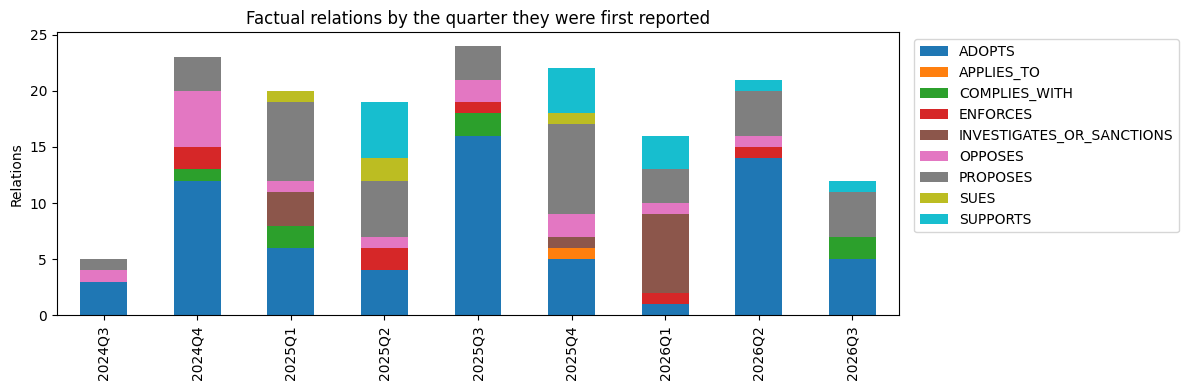

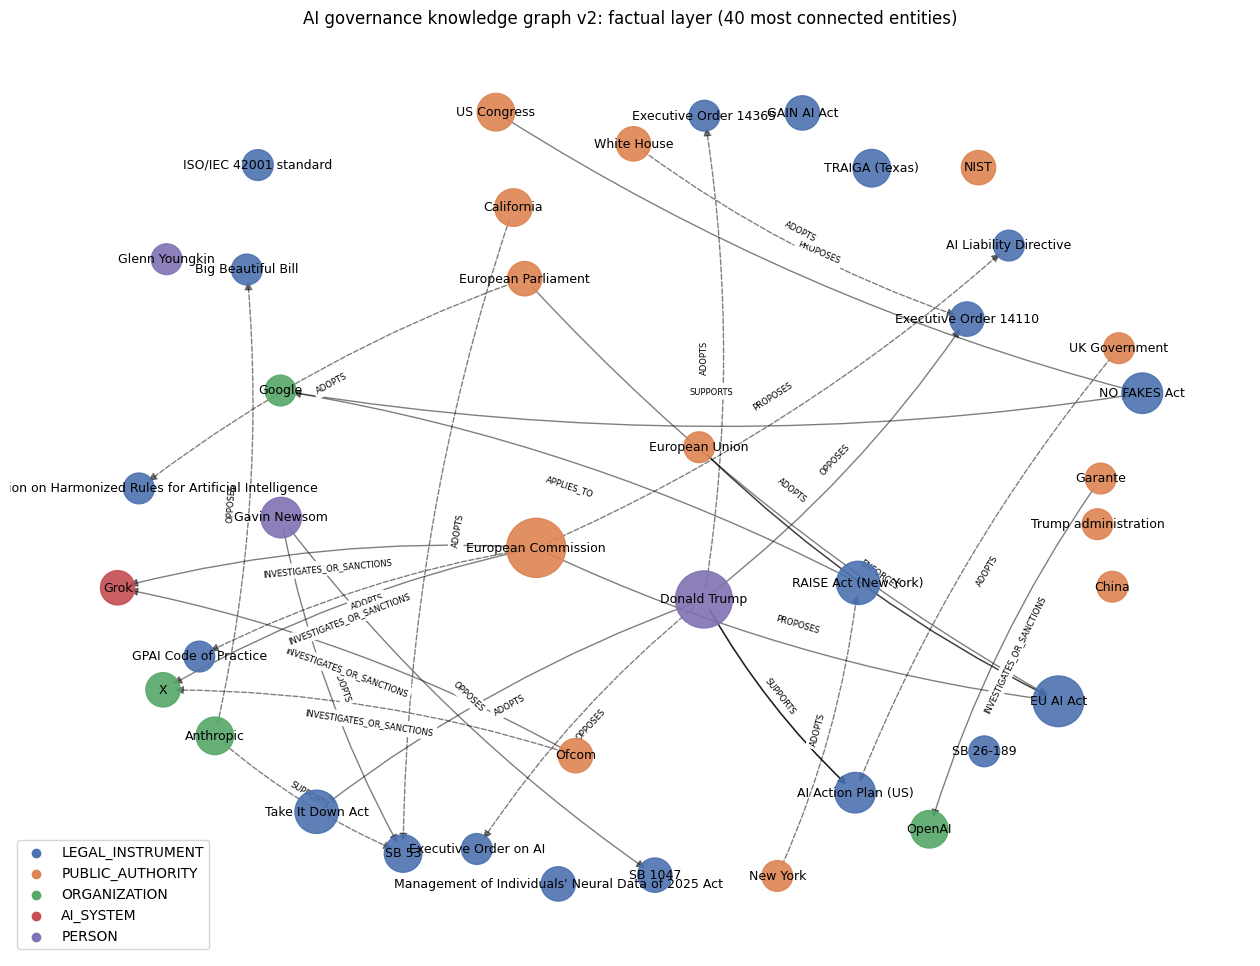

In [40]:
# 1. Metrics of the factual layer
G_simple = nx.DiGraph(G_fact)          # one edge per pair for PageRank
G_undirected = nx.Graph(G_fact)
metrics = pd.DataFrame({
    "entity_type": nx.get_node_attributes(G_fact, "entity_type"),
    "degree": dict(G_fact.degree()),
    "in_degree": dict(G_fact.in_degree()),
    "out_degree": dict(G_fact.out_degree()),
    "pagerank": nx.pagerank(G_simple),
    "betweenness": nx.betweenness_centrality(G_undirected),
}).sort_values("degree", ascending=False)

components = sorted(nx.connected_components(G_undirected), key=len, reverse=True)
print(f"Entities: {G_fact.number_of_nodes()} | edges: {G_fact.number_of_edges()} | "
      f"density: {nx.density(G_simple):.4f}")
print(f"Connected components: {len(components)} | largest: {len(components[0])} entities "
      f"({len(components[0]) / G_fact.number_of_nodes():.0%})")
print("\nMost connected entities:")
display(metrics.head(15).round(4))
print("Entity types:")
display(metrics["entity_type"].value_counts().to_frame("entities"))
metrics.to_csv(os.path.join(KG_FOLDER, "node_metrics_factual.csv"))

# 2. Relations over time (by the date they were first reported)
quarterly = (fact.assign(quarter=fact["first_date"].dt.to_period("Q").astype(str))
             .groupby(["quarter", "predicate"]).size().unstack(fill_value=0))
quarterly.plot(kind="bar", stacked=True, figsize=(12, 4), colormap="tab10")
plt.title("Factual relations by the quarter they were first reported")
plt.ylabel("Relations")
plt.xlabel("")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

# 3. Visualisation of the 40 most connected entities
TYPE_COLORS = {"LEGAL_INSTRUMENT": "#4C72B0", "PUBLIC_AUTHORITY": "#DD8452", "ORGANIZATION": "#55A868",
               "AI_SYSTEM": "#C44E52", "PERSON": "#8172B3"}
top_nodes = metrics.head(40).index
H = G_fact.subgraph(top_nodes)
pos = nx.spring_layout(H, seed=RANDOM_STATE, k=1.2)

plt.figure(figsize=(16, 12))
nx.draw_networkx_nodes(H, pos, node_color=[TYPE_COLORS[H.nodes[n]["entity_type"]] for n in H],
                       node_size=[250 + 120 * metrics.loc[n, "degree"] for n in H], alpha=0.9)
for status, style in [("validated", "solid"), ("corrected", "solid"), ("unreviewed", "dashed")]:
    edge_list = [(u, v) for u, v, d in H.edges(data=True) if d["validation_status"] == status]
    nx.draw_networkx_edges(H, pos, edgelist=edge_list, style=style, alpha=0.5, arrows=True,
                           arrowsize=12, connectionstyle="arc3,rad=0.08")
nx.draw_networkx_labels(H, pos, font_size=9)
nx.draw_networkx_edge_labels(H, pos, edge_labels={(u, v): d["relation"] for u, v, d in H.edges(data=True)},
                             font_size=6)
for entity_type, color in TYPE_COLORS.items():
    plt.scatter([], [], c=color, label=entity_type)
plt.legend(loc="lower left")
plt.title("AI governance knowledge graph v2: factual layer (40 most connected entities)")
plt.axis("off")
plt.show()

**Result.** The factual layer is **sparse and fragmented**: 211 entities, 162 edges, a density of 0.004 and 54 connected components, the largest with 31 entities (15%). Most components are small "stars": a law in the centre (high in-degree, e.g. *EU AI Act* 9, *Take It Down Act* 6, *RAISE Act* 6) and the actors that proposed, adopted, supported or opposed it. Actors have only outgoing edges; the most active are the *European Commission* (13 edges) and *Donald Trump* (12). By PageRank, laws with many supporting and adopting actors rank highest (*NO FAKES Act*, *EU AI Act*, *Take It Down Act*). Almost half of the entities are legal instruments (94), followed by public authorities (58) and persons (34). Only two AI systems remain, because most extracted relations about AI systems were `APPLIES_TO` relations, which did not pass the validation.

For the graph-enhanced RAG system this means: the graph provides reliable **one-hop facts** about a law or an actor (who did what, and when), but hardly any longer paths. Questions about a specific law or actor should profit most; open analytical questions much less.

### Export of the knowledge graph (Pascal)

The graph is saved in `kg_v2/` on Google Drive in the formats that Part 4 and the toolbox read:

| File | Content |
|---|---|
| `kg_v2_facts.csv` | factual layer as an edge table in the format of `ingest_knowledge_graph`: `subject`, `relation`, `object`, `subject_type`, `object_type`, `source_ids` (article ids), `date` (first reported), and our own fields `last_date`, `passage_ids`, `n_docs`, `modality`, `validation_status`, `evidence` |
| `kg_v2_cooccurrence.csv` | co-occurrence layer in the same format, with `relation = CO_MENTIONED_WITH`, `weight`, `pmi`, example `passage_ids` and `factual = False` |
| `kg_v2_entities.csv` | every entity with its type, its surface forms (aliases, used for entity linking in Part 4) and its network metrics |
| `kg_v2_factual.graphml`, `kg_v2_cooccurrence.graphml` | both layers as GraphML for tools such as Gephi |
| `kg_v2_data_dictionary.md` | schema and data dictionary: layers, entity types, predicates, fields, validation statuses and their precision |

In [41]:
# 1. Factual layer: edge table for ingest_knowledge_graph
facts_export = pd.DataFrame({
    "subject": fact["subject"], "relation": fact["predicate"], "object": fact["object"],
    "subject_type": fact["subject_type"], "object_type": fact["object_type"],
    "source_ids": fact["doc_ids"].map(json.dumps),
    "date": fact["first_date"].dt.strftime("%Y-%m-%d"),
    "last_date": fact["last_date"].dt.strftime("%Y-%m-%d"),
    "passage_ids": fact["passage_ids"].map(json.dumps),
    "n_docs": fact["n_docs"], "modality": fact["modality"],
    "validation_status": fact["validation_status"], "evidence": fact["evidence"],
    "layer": "factual",
})
facts_export.to_csv(os.path.join(KG_FOLDER, "kg_v2_facts.csv"), index=False)

# 2. Co-occurrence layer (not factual)
passage_doc = passages.set_index("passage_id")["doc_id"].astype(str)
cooc_export = pd.DataFrame([{
    "subject": a, "relation": "CO_MENTIONED_WITH", "object": b,
    "subject_type": G_fact.nodes[a]["entity_type"], "object_type": G_fact.nodes[b]["entity_type"],
    "source_ids": json.dumps(sorted({passage_doc[p] for p in d["passage_ids"]})),
    "passage_ids": json.dumps(d["passage_ids"]),
    "weight": d["weight"], "pmi": d["pmi"], "factual": False, "layer": "cooccurrence",
} for a, b, d in G_cooc.edges(data=True)])
cooc_export.to_csv(os.path.join(KG_FOLDER, "kg_v2_cooccurrence.csv"), index=False)

# 3. Entities with aliases and metrics (aliases are used for entity linking in Part 4)
aliases = defaultdict(set)
for form, entity in surface_to_entity.items():
    aliases[entity].add(form)
entities_export = metrics.copy()
entities_export["aliases"] = [json.dumps(sorted(aliases.get(e, {e}))) for e in entities_export.index]
entities_export["n_passages"] = [len(entity_passages.get(e, ())) for e in entities_export.index]
entities_export.rename_axis("entity").reset_index().to_csv(os.path.join(KG_FOLDER, "kg_v2_entities.csv"), index=False)


# 4. GraphML (only str, int, float and bool attributes are allowed)
def graphml_safe(graph):
    H = graph.copy()
    for _, data in H.nodes(data=True):
        for k, v in list(data.items()):
            data[k] = json.dumps(v) if isinstance(v, (list, dict)) else v
    for *_, data in H.edges(data=True):
        for k, v in list(data.items()):
            data[k] = json.dumps(v) if isinstance(v, (list, dict)) else v
    return H


nx.write_graphml(graphml_safe(G_fact), os.path.join(KG_FOLDER, "kg_v2_factual.graphml"))
nx.write_graphml(graphml_safe(G_cooc), os.path.join(KG_FOLDER, "kg_v2_cooccurrence.graphml"))

# 5. Data dictionary
status_counts = fact["validation_status"].value_counts().to_dict()
type_lines = "\n".join(f"| `{t}` | {d} |" for t, d in KG_SCHEMA["entity_types"].items())
predicate_lines = "\n".join(
    f"| `{p}` | {' / '.join(v['subject'])} | {' / '.join(v['object'])} | {v['meaning']} |"
    for p, v in KG_SCHEMA["predicates"].items()
)
precision_lines = "\n".join(
    f"| {s} | {int(r['edges'])} | {int(r['correct'])} | {r['precision']:.0%} | {r['ci_95']} |"
    for s, r in precision_table.iterrows()
)
data_dictionary = f"""# AI Governance Knowledge Graph v2 – data dictionary

Built in Stage 3 from relations extracted with `qwen3:14b` (Ollama) from passages of the AI Media Dataset
(September 2024 – August 2026), schema version `{KG_SCHEMA['version']}`.

## Layers

| Layer | Edges | Meaning |
|---|---:|---|
| factual | {len(facts_export)} | relations of the controlled schema, with evidence; may be cited as evidence |
| cooccurrence | {len(cooc_export)} | entities mentioned in the same passage (>= {MIN_SHARED_PASSAGES} passages); **not factual**, only for retrieval expansion |

## Entity types

| Type | Description |
|---|---|
{type_lines}

## Predicates (factual layer)

| Predicate | Subject types | Object types | Meaning |
|---|---|---|---|
{predicate_lines}

## Fields of an edge

| Field | Meaning |
|---|---|
| `subject`, `relation`, `object` | the relation (canonical entity names) |
| `subject_type`, `object_type` | entity types of the schema |
| `source_ids` | ids (`doc_id`) of the articles that report the relation |
| `passage_ids` | ids of the passages with the evidence (also passages of the RAG search corpus) |
| `date`, `last_date` | publication date of the first and the last article that reports the relation |
| `n_docs` | number of articles that report the relation |
| `modality` | `actual` (happened) or `planned` (announced or intended) |
| `validation_status` | `validated`, `corrected` or `unreviewed` (rejected edges are removed) |
| `evidence` | verbatim quote from the first passage |
| `weight`, `pmi` | co-occurrence layer only: shared passages and pointwise mutual information |

## Validation

Status of the factual edges: {status_counts}.

| Review set | Edges | Correct | Precision | 95% CI |
|---|---:|---:|---:|---|
{precision_lines}

The precision of the random sample is the estimate for `unreviewed` edges.
"""
with open(os.path.join(KG_FOLDER, "kg_v2_data_dictionary.md"), "w", encoding="utf-8") as f:
    f.write(data_dictionary)

print("Saved in", KG_FOLDER)
for name in sorted(os.listdir(KG_FOLDER)):
    print("   ", name)

Saved in /content/drive/MyDrive/NLP_Projekt/stage3/kg_v2
    edges_factual.parquet
    kg_v2_cooccurrence.csv
    kg_v2_cooccurrence.graphml
    kg_v2_data_dictionary.md
    kg_v2_entities.csv
    kg_v2_facts.csv
    kg_v2_factual.graphml
    node_metrics_factual.csv


## 1.7 Export of the Part 1 results (Pascal)

The following parts do not need to run Part 1 again. We save its results on Google Drive:

| File | Content |
|---|---|
| `export_articles.parquet` | one row per article of the cleaned corpus: metadata (title, date, domain, URL) and all filter columns (lexical and semantic scores, `gov_v2`, `excluded_source`, `in_rag_corpus`), without full texts |
| `rag/rag_passages.parquet` | the cleaned passages of all articles in the governance corpus: the search corpus of the RAG system and the source of the Q&A dataset |
| `relations_normalized.parquet`, `entities_kg.parquet` | relations and entities of the knowledge graph (saved in section 1.4) |
| `export_manifest.json` | when and with which filter the export was made, and the number of rows |

Parts 2–4 start with a loading cell that reads these files.

In [43]:
EXPORT_ARTICLES_FILE = os.path.join(STAGE3_FOLDER, "export_articles.parquet")
RAG_FOLDER = os.path.join(STAGE3_FOLDER, "rag")
RAG_PASSAGES_FILE = os.path.join(RAG_FOLDER, "rag_passages.parquet")
EXPORT_MANIFEST_FILE = os.path.join(STAGE3_FOLDER, "export_manifest.json")
os.makedirs(RAG_FOLDER, exist_ok=True)

# Filter that defines the governance corpus (topic filter gov_v2 without excluded sources)
CORPUS_FILTER = "gov_v2 & ~excluded_source"
df["in_rag_corpus"] = df["gov_v2"] & ~df["excluded_source"]

# 1. Articles: metadata and filter columns, no full texts
article_columns = [
    "title", "published_at", "domain", "url", "n_words", "in_stage1",
    "gov_score_per_1k", "gov_distinct_terms", "off_max_per_1k", "off_main_category",
    "gov_lexical", "sem_margin", "gov_v2", "excluded_source", "in_rag_corpus",
]
df[article_columns].reset_index().to_parquet(EXPORT_ARTICLES_FILE, index=False)

# 2. Passages of the governance corpus, in the format of the search corpus
selected = passages[passages["doc_id"].isin(df.index[df["in_rag_corpus"]])]
rag_records = pd.DataFrame({
    "id": selected["passage_id"].values,
    "source_id": selected["doc_id"].astype(str).values,
    "chunk_index": selected["chunk_index"].values,
    "title": selected["title"].values,
    "date": selected["published_at"].dt.strftime("%Y-%m-%d").values,
    "domain": selected["domain"].fillna("").values,
    "url": selected["url"].fillna("").values,
    "text": selected["text"].values,
})
rag_records.to_parquet(RAG_PASSAGES_FILE, index=False)

# 3. Manifest
manifest = {
    "created": pd.Timestamp.now(tz="Europe/Zurich").isoformat(timespec="seconds"),
    "corpus_filter": CORPUS_FILTER,
    "articles_total": int(len(df)),
    "articles_in_rag_corpus": int(df["in_rag_corpus"].sum()),
    "rag_passages": int(len(rag_records)),
}
with open(EXPORT_MANIFEST_FILE, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

print(json.dumps(manifest, indent=2))

{
  "created": "2026-10-31T14:27:00+01:00",
  "corpus_filter": "gov_v2 & ~excluded_source",
  "articles_total": 47444,
  "articles_in_rag_corpus": 3794,
  "rag_passages": 37786
}


In [2]:
# ===== QUICK START: skips Part 1 (delete this cell for the final run) =====
# Workflow: run the setup cell, then this cell, then click into the part you work on
# and use "Runtime > Run cell and below". All later parts read the Part 1 results
# from Google Drive (section 1.7) and do not need the variables of Part 1.
import shutil
import subprocess

PART1_EXPORTS = [
    os.path.join(STAGE3_FOLDER, "export_articles.parquet"),
    os.path.join(STAGE3_FOLDER, "rag", "rag_passages.parquet"),
    os.path.join(STAGE3_FOLDER, "relations_normalized.parquet"),
    os.path.join(STAGE3_FOLDER, "entities_kg.parquet"),
    os.path.join(STAGE3_FOLDER, "export_manifest.json"),
]
missing = [f for f in PART1_EXPORTS if not os.path.exists(f)]
if missing:
    raise FileNotFoundError(f"Missing Part 1 export: {missing}. Run Part 1 completely once (incl. section 1.7).")

with open(PART1_EXPORTS[-1], encoding="utf-8") as f:
    manifest = json.load(f)
print(f"Part 1 export from {manifest['created']} | filter: {manifest['corpus_filter']} | "
      f"{manifest['articles_in_rag_corpus']:,} articles, {manifest['rag_passages']:,} passages")

# The later parts need a running Ollama server; in a full run it is started in section 1.4
if shutil.which("ollama") is None:
    !apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1
!pip install -q ollama
import ollama

OLLAMA_LOG_FILE = "/content/ollama_server.log"


def ollama_running():
    try:
        ollama.list()
        return True
    except Exception:
        return False


def start_ollama_server():
    log = open(OLLAMA_LOG_FILE, "a")
    subprocess.Popen(["ollama", "serve"], stdout=log, stderr=subprocess.STDOUT)
    for _ in range(30):
        if ollama_running():
            return True
        time.sleep(1)
    return False


if not ollama_running():
    start_ollama_server()
print("Ollama server running:", ollama_running())

NameError: name 'os' is not defined

# 2. Q&A dataset construction (Timon)

The Q&A dataset is the basis for the evaluation in Parts 3–6. Every Q&A pair is stored in the format of the course skeleton: `id`, `type`, `question`, `reference_answer`, `source_ids` (our `doc_id`s as strings), `passage_id` and `date`. The pairs are generated from passages of the search corpus, so every reference passage can be retrieved and every `source_id` matches the corpus.

Part 2 only reads the Part 1 export on Google Drive (section 1.7): the search corpus `rag_passages.parquet`, the article table with the filter scores and the knowledge-graph relations. It therefore also runs when Part 1 is skipped.

## 2.1 Selection of the source passages

We select about **130 passages**.

**Pool.** All passages of the search corpus, with three additional conditions:

- - The article has a semantic margin of at least 0.02. Borderline articles are the most likely to be off-topic, because the topic filter could not be evaluated (section 1.2), and a question about an off-topic article would not test the governance RAG system.

- The passage is informative enough for questions: at least 80 words, at least two named legal instruments or actors, and at least one term of a governance subtopic.
- Passages with leftover list separators (scraping artefacts, section 1.3) are excluded.

**Subtopic per passage.** The semantic label of section 1.1 describes the lead of the *article*. An article about the AI Act can also contain a passage about a fine or a lawsuit. We therefore assign each *passage* to one of the same eight subtopics (regulation, enforcement, lawsuits, bias and fairness, safety and security, accountability, privacy, deepfakes) with short term lists. The subtopic with the most matches wins.

**Two groups of passages:**

1. **KG passages (40):** passages with at least one relation of the knowledge graph (section 1.4). They are used for the *relational* questions, and they allow us to measure whether the graph integration helps on exactly these questions. They are selected round-robin over the predicates, so that not only `ADOPTS` relations are included.
2. **Stratified passages (90):** selected round-robin over **month × subtopic**, so that every subtopic and the whole period from September 2024 to August 2026 are covered and the peak months do not dominate.

**Diversity constraints:** at most one passage per article, no two articles with the same title (agency reports published by several outlets), at most 6 passages per domain and at most 6 passages per month.

**Frozen selection.** The Q&A pairs are reviewed by hand, so the selection must not change when the notebook runs again. It is drawn once with a fixed seed and saved. Later runs load it and only check that all passages are still in the search corpus.

In [1]:
from collections import Counter

QA_FOLDER = os.path.join(STAGE3_FOLDER, "qa")
QA_PASSAGES_FILE = os.path.join(QA_FOLDER, "qa_passages.parquet")
os.makedirs(QA_FOLDER, exist_ok=True)

# Part 1 export (section 1.7)
qa_articles = pd.read_parquet(os.path.join(STAGE3_FOLDER, "export_articles.parquet")).set_index("doc_id")
qa_corpus = pd.read_parquet(os.path.join(STAGE3_FOLDER, "rag", "rag_passages.parquet"))
qa_relations = pd.read_parquet(os.path.join(STAGE3_FOLDER, "relations_normalized.parquet"))

print(f"Search corpus: {len(qa_corpus):,} passages from {qa_corpus['source_id'].nunique():,} articles")
print(f"KG relations:  {len(qa_relations):,} from {qa_relations['passage_id'].nunique():,} passages "
      f"({qa_relations['passage_id'].isin(qa_corpus['id']).mean():.0%} in the search corpus)")

NameError: name 'os' is not defined

Loaded the frozen selection: 130 passages
130 articles, 58 domains, 40 passages with KG relation


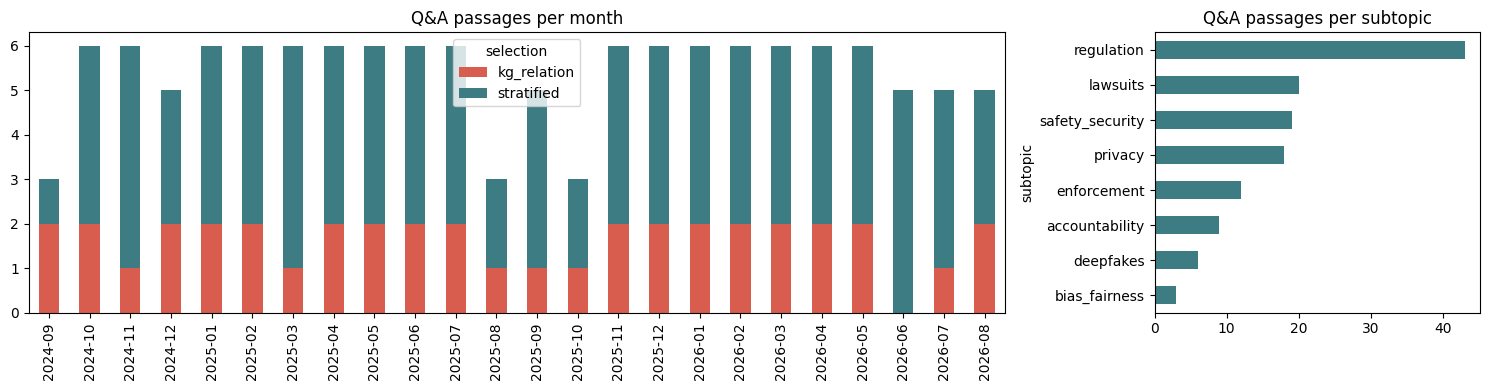

KG predicates covered:


kg_predicate,PROPOSES,OPPOSES,ADOPTS,SUPPORTS,INVESTIGATES_OR_SANCTIONS,APPLIES_TO,ENFORCES,SUES,COMPLIES_WITH
count,6,6,5,5,5,4,4,3,2


Most frequent domains:


domain,gizmodo,technologyreview,csis,bakermckenzie,eutoday,apnews,theconversation,aijourn,ai-regulation,cnbc
count,6,6,6,5,5,5,5,5,4,4



[19430_005] 2025-06-30 | privacy | Cloud CISO Perspectives: The global threats facing EU healthcare
Google Cloud customers such as AiGenomix leverage Confidential Computing to deliver infectious disease
surveillance and early cancer detection. Confidential Computing helps them ensure privacy and security for
genomic and related health data assets, and also align with the EHDS's vision for data-driven improvements in
healthcare delivery and outcomes. We believe that these insights and capabilities offered by Google can
significantly contribute to the successful implementation of the European Health Security Action Plan. We are
committed to continued collaboration with the European Commission, EU member states, and all stakeholders to
build a more secure and resilient digital future for healthcare. To learn more about Google's efforts to
secure and support healthcare organizations around the world, contact our Office of the CISO. At the cutting
edge of social engineering we find the AI-

In [46]:
N_KG_PASSAGES = 40
N_STRATIFIED_PASSAGES = 90
MIN_QA_WORDS = 80
MIN_NAMED_MENTIONS = 2
MIN_SEM_MARGIN = 0.02
MAX_PER_DOMAIN = 6
MAX_KG_PER_MONTH = 2      # KG step: spread over time
MAX_PER_MONTH = 6         # both steps together
RESELECT = False          # True only for a new selection (the reviewed Q&A pairs are then lost)

# Governance subtopics, same labels as the prototypes of section 1.1
SUBTOPIC_PATTERNS = {name: re.compile(pattern, re.IGNORECASE) for name, pattern in {
    "regulation":      r"\b(?:AI Act|bills?|legislat\w+|regulations?|executive orders?|code of practice|"
                       r"lawmakers?|statutes?|into law)\b",
    "enforcement":     r"\b(?:fined?|fines|penalt\w+|investigat\w+|probes?|antitrust|enforc\w+|sanction\w*)\b",
    "lawsuits":        r"\b(?:lawsuits?|sued|sues|suing|courts?|judges?|copyright|plaintiffs?|litigation|settlements?)\b",
    "bias_fairness":   r"\b(?:bias\w*|discriminat\w+|fairness|unfair|civil rights)\b",
    "safety_security": r"\b(?:safety|red[- ]teaming|jailbreak\w*|prompt injections?|misuse|frontier models?|"
                       r"catastrophic|vulnerab\w+)\b",
    "accountability":  r"\b(?:transparen\w+|accountab\w+|oversight|explainab\w+|audits?|disclos\w+)\b",
    "privacy":         r"\b(?:privacy|personal data|data protection|GDPR|surveillance|facial recognition|biometric\w*)\b",
    "deepfakes":       r"\b(?:deepfakes?|misinformation|disinformation|synthetic media|watermark\w*|non-consensual)\b",
}.items()}

# Named legal instruments and actors (compact version of the patterns of section 1.4)
QA_NAMED_PATTERN = re.compile(
    r"\b(?:[A-Z][\w.'-]*\s){0,5}(?:Act|Bill|Directive|Regulation|Executive Order|Code of Practice|"
    r"Framework|Action Plan)\b"
    r"|\b(?:SB|AB|HB)\s?\d{1,5}\b|\b(?:GDPR|DSA|DMA)\b"
    r"|\b(?:Commission|Parliament|Congress|Senate|White House|Ministry|Department|Agency|Authority|"
    r"Court|Judge|Governor|FTC|DOJ|NIST|Ofcom|CNIL|ICO|AI Office|OpenAI|Anthropic|Google|Meta|"
    r"Microsoft|Apple|Amazon|Nvidia|xAI|Mistral|DeepSeek|TikTok|Perplexity)\b"
)
LIST_SEPARATOR = re.compile(r"""['"], ['"]""")


def build_qa_pool():
    pool = qa_corpus.rename(columns={"id": "passage_id"}).copy()
    pool["doc_id"] = pool["source_id"].astype(int)
    pool["month"] = pool["date"].str[:7]
    pool["n_words"] = pool["text"].str.split().str.len()
    pool["sem_margin"] = pool["doc_id"].map(qa_articles["sem_margin"])
    pool["n_named"] = pool["text"].str.count(QA_NAMED_PATTERN)
    pool["title_key"] = pool["title"].str.lower().str.replace(r"\W+", " ", regex=True).str.strip()

    hits = pd.DataFrame({name: pool["text"].str.count(p) for name, p in SUBTOPIC_PATTERNS.items()},
                        index=pool.index)
    pool["subtopic"] = hits.idxmax(axis=1)
    pool["subtopic_hits"] = hits.max(axis=1)

    # Relations of the knowledge graph per passage
    rel = qa_relations.copy()
    rel["triple"] = (rel["subject_canonical"] + " --" + rel["predicate"] + " [" + rel["modality"]
                     + "]--> " + rel["object_canonical"])
    kg = rel.groupby("passage_id").agg(
        kg_predicate=("predicate", lambda s: s.mode().iat[0]),
        kg_relations=("triple", "; ".join),
        kg_n_relations=("triple", "size"),
    )
    pool = pool.join(kg, on="passage_id")
    pool["has_kg_relation"] = pool["kg_predicate"].notna()

    pool["informative"] = (
        (pool["n_words"] >= MIN_QA_WORDS)
        & (pool["n_named"] >= MIN_NAMED_MENTIONS)
        & (pool["subtopic_hits"] >= 1)
    )
    keep = (
        (pool["sem_margin"] >= MIN_SEM_MARGIN)
        & ~pool["text"].str.contains(LIST_SEPARATOR)
        & (pool["informative"] | pool["has_kg_relation"])
    )
    return pool[keep].sort_values("passage_id")


def select_round_robin(pool, n, group_cols, max_per_month, chosen):
    """Shuffle once, then take candidates group by group (1st of every group, then 2nd, ...)."""
    shuffled = pool.sample(frac=1, random_state=RANDOM_STATE)
    shuffled["rank_in_group"] = shuffled.groupby(group_cols).cumcount()
    shuffled = shuffled.sort_values("rank_in_group", kind="stable")
    picked = []
    for row in shuffled.itertuples():
        if len(picked) == n:
            break
        if (row.doc_id in chosen["docs"] or row.title_key in chosen["titles"]
                or chosen["domains"][row.domain] >= MAX_PER_DOMAIN
                or chosen["months"][row.month] >= max_per_month):
            continue
        picked.append(row.Index)
        chosen["docs"].add(row.doc_id)
        chosen["titles"].add(row.title_key)
        chosen["domains"][row.domain] += 1
        chosen["months"][row.month] += 1
    return pool.loc[picked]


QA_COLUMNS = [
    "passage_id", "source_id", "date", "month", "title", "domain", "url", "subtopic", "selection",
    "has_kg_relation", "kg_predicate", "kg_relations", "kg_n_relations", "n_words", "sem_margin", "text",
]

if os.path.exists(QA_PASSAGES_FILE) and not RESELECT:
    qa_passages = pd.read_parquet(QA_PASSAGES_FILE)
    print(f"Loaded the frozen selection: {len(qa_passages)} passages")
else:
    pool = build_qa_pool()
    print(f"Pool: {len(pool):,} passages ({pool['has_kg_relation'].sum()} with KG relation)")

    chosen = {"docs": set(), "titles": set(), "domains": Counter(), "months": Counter()}
    kg_selected = select_round_robin(pool[pool["has_kg_relation"]], N_KG_PASSAGES,
                                     ["kg_predicate"], MAX_KG_PER_MONTH, chosen)
    stratified = select_round_robin(pool[pool["informative"]], N_STRATIFIED_PASSAGES,
                                    ["month", "subtopic"], MAX_PER_MONTH, chosen)

    qa_passages = (
        pd.concat([kg_selected.assign(selection="kg_relation"),
                   stratified.assign(selection="stratified")])
        .sort_values(["date", "passage_id"])[QA_COLUMNS]
        .reset_index(drop=True)
    )
    qa_passages.to_parquet(QA_PASSAGES_FILE, index=False)
    print(f"Selected and saved: {len(qa_passages)} passages")

# Check: are all selected passages still in the search corpus (e.g. after the final filter of 1.2)?
not_in_corpus = qa_passages.loc[~qa_passages["passage_id"].isin(qa_corpus["id"]), "passage_id"]
if len(not_in_corpus):
    print(f"WARNING: {len(not_in_corpus)} passages are no longer in the search corpus: {list(not_in_corpus)}")

print(f"{qa_passages['source_id'].nunique()} articles, {qa_passages['domain'].nunique()} domains, "
      f"{qa_passages['has_kg_relation'].sum()} passages with KG relation")

# Coverage
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [3, 1]})
pd.crosstab(qa_passages["month"], qa_passages["selection"]).plot.bar(
    stacked=True, ax=ax1, color=["#D95D4F", "#3D7C83"])
ax1.set_title("Q&A passages per month")
ax1.set_xlabel("")
qa_passages["subtopic"].value_counts().sort_values().plot.barh(ax=ax2, color="#3D7C83")
ax2.set_title("Q&A passages per subtopic")
plt.tight_layout()
plt.show()

print("KG predicates covered:")
display(qa_passages.loc[qa_passages["selection"] == "kg_relation", "kg_predicate"].value_counts().to_frame().T)
print("Most frequent domains:")
display(qa_passages["domain"].value_counts().head(10).to_frame().T)

for _, row in qa_passages.sample(n=2, random_state=RANDOM_STATE).iterrows():
    print(f"\n[{row['passage_id']}] {row['date']} | {row['subtopic']} | {row['title'][:70]}")
    if row["has_kg_relation"]:
        print(f"KG: {row['kg_relations']}")
    print(textwrap.fill(row["text"], 110))

## 2.2 Question types per passage (Timon)

The project brief asks for a mix of **factual, temporal, relational, analytical and comparative** questions. Not every type fits every passage, so we assign the types by rule:

| Passages | Question types |
|---|---|
| KG passages (40) | `relational` + `temporal` (if the passage mentions a date) or `factual` |
| Stratified passages (90) | `factual` + `analytical`, plus `temporal` for every second passage that mentions a date |
| Passage pairs (20) | one `comparative` question that needs both passages |

**Comparative questions** need two sources. We pair stratified passages that are about a similar topic (cosine similarity of `bge-small-en-v1.5` embeddings ≥ 0.7) but were published at least 3 months apart. Such pairs allow questions about how a debate or a rule changed over time. Every passage is used in at most one pair, and at most 4 pairs share the subtopic of their first passage.

This gives about 320 generated pairs. We generate more than the 200–300 required, because the automatic checks and the manual review remove some of them.

In [47]:
TIME_REF_PATTERN = re.compile(
    r"\b(?:January|February|March|April|May|June|July|August|September|October|November|December|"
    r"20[12]\d|last (?:week|month|year)|this (?:week|month|year))\b"
)
N_COMPARATIVE_PAIRS = 20
MIN_MONTHS_APART = 3
MIN_PAIR_SIMILARITY = 0.7
MAX_PAIRS_PER_SUBTOPIC = 4


def question_types(row, position):
    has_time = bool(TIME_REF_PATTERN.search(row.text))
    if row.selection == "kg_relation":
        return ["relational", "temporal" if has_time else "factual"]
    types = ["factual", "analytical"]
    if has_time and position % 2 == 0:
        types.append("temporal")
    return types


qa_passages["question_types"] = [question_types(r, i) for i, r in enumerate(qa_passages.itertuples())]

# Passage pairs for comparative questions
strat = qa_passages[qa_passages["selection"] == "stratified"].reset_index(drop=True)
pair_embedder = SentenceTransformer("BAAI/bge-small-en-v1.5")
pair_emb = pair_embedder.encode((strat["title"] + ". " + strat["text"]).tolist(), normalize_embeddings=True)
similarity = pair_emb @ pair_emb.T
month_number = strat["date"].str[:4].astype(int) * 12 + strat["date"].str[5:7].astype(int)

candidates = sorted(
    ((similarity[i, j], i, j) for i in range(len(strat)) for j in range(i + 1, len(strat))
     if abs(month_number[i] - month_number[j]) >= MIN_MONTHS_APART and similarity[i, j] >= MIN_PAIR_SIMILARITY),
    reverse=True,
)
used, per_subtopic, pairs = set(), Counter(), []
for sim, i, j in candidates:
    if len(pairs) == N_COMPARATIVE_PAIRS:
        break
    a, b = (i, j) if strat.loc[i, "date"] <= strat.loc[j, "date"] else (j, i)   # a = earlier passage
    if i in used or j in used or per_subtopic[strat.loc[a, "subtopic"]] >= MAX_PAIRS_PER_SUBTOPIC:
        continue
    used.update([i, j])
    per_subtopic[strat.loc[a, "subtopic"]] += 1
    pairs.append({
        "pair_id": f"pair_{len(pairs):02d}", "similarity": round(float(sim), 3),
        "subtopic": strat.loc[a, "subtopic"],
        "passage_id_a": strat.loc[a, "passage_id"], "passage_id_b": strat.loc[b, "passage_id"],
        "source_id_a": strat.loc[a, "source_id"], "source_id_b": strat.loc[b, "source_id"],
        "date_a": strat.loc[a, "date"], "date_b": strat.loc[b, "date"],
        "title_a": strat.loc[a, "title"], "title_b": strat.loc[b, "title"],
    })
qa_pairs = pd.DataFrame(pairs)

type_plan = Counter(t for types in qa_passages["question_types"] for t in types)
type_plan["comparative"] = len(qa_pairs)
print("Planned questions per type:")
display(pd.Series(type_plan).to_frame("questions").T.assign(total=sum(type_plan.values())))

print(f"\n{len(qa_pairs)} passage pairs for comparative questions:")
for p in qa_pairs.itertuples():
    print(f"  {p.similarity:.2f} | {p.date_a} {p.title_a[:45]:<45} | {p.date_b} {p.title_b[:45]}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Planned questions per type:


,factual,analytical,temporal,relational,comparative,total
questions,101,90,58,40,20,309



20 passage pairs for comparative questions:
  0.86 | 2025-05-07 Meta's new AI chatbot is yet another tool for | 2025-11-17 Meta's AI Chat Gambit: Revolutionizing Ads or
  0.85 | 2024-09-20 ANS CEO Talks if the EU AI Act Will Help or H | 2025-09-25 AI Act and DSA: Challenges for EU Innovation
  0.82 | 2025-03-28 Why Centralized AI Fails in Enterprise: The C | 2026-06-04 EU AI Act Compliance Using Enterprise AI Gate
  0.81 | 2025-04-01 Data protection meets AI: GDPR vs. the AI Act | 2026-06-04 What is AI Compliance? Definition and Importa
  0.81 | 2025-04-23 Ex-OpenAI workers ask California and Delaware | 2026-05-15 Musk v. Altman week 3: Musk and Altman traded
  0.80 | 2025-03-02 Canada, other countries struggling to come up | 2026-03-20 Here's how the White House wants Congress to 
  0.80 | 2025-01-02 'Bad Likert Judge ' Jailbreaks OpenAI Defense | 2025-07-08 LLMs Pose Major Security Risks, Serving As ' 
  0.79 | 2024-11-30 Sumsub Compliance Lead Talks Effects of EU's  | 2025-06-10 EU

## 2.3 Generation of the Q&A pairs (Timon)

**Model.** The project brief requires an LLM for the Q&A generation that differs from the one in the RAG pipeline. The RAG system answers with `qwen3:8b` (section 3.4), and the relations were extracted with `qwen3:14b` (section 1.4). We therefore use **`gemma3:12b`** from another model family. A generator from the same family could phrase questions the way the tested model "expects" them and make the evaluation look better than it is. The model runs locally with Ollama on the Colab GPU, like the extraction.

**Prompt.** One request per passage, and one per passage pair. The prompt defines the question types and the following rules:

- **answerable from the passage alone**, without background knowledge;
- **standalone:** the RAG system searches the whole archive, so a question must not refer to "the article" and must name actors, laws and places explicitly;
- **specific:** one clear answer, not many possible answers in different articles (e.g. *"Which California bill did Gavin Newsom veto in September 2024?"* instead of *"Which bill was vetoed?"*);
- **reference answer** in 1–3 sentences, with dates when the question concerns time;
- **evidence:** a verbatim sentence from the passage that supports the answer, which we check automatically in section 2.4.

For relational questions the prompt also lists the knowledge-graph relations of the passage as hints, marked as possibly wrong: the question must still be based on the text. For comparative questions the model may return no question if the two passages do not allow a meaningful comparison. The example in the prompt is invented (fictional country and company), so it cannot leak into the dataset.

**Enforced format and reproducibility.** As in section 1.4, the answer format is passed as a JSON schema (`format=`). The model can only return the requested types and the requested number of questions. Temperature 0, a fixed seed, the recorded model digest and a cache on Google Drive make the generation reproducible. The first run takes about one hour on a T4; later runs read the cache.

In [48]:
from typing import Annotated, List, Literal
from pydantic import create_model, Field

QA_MODEL = "gemma3:12b"
QA_PROMPT_VERSION = "v1"
QA_CACHE_FILE = os.path.join(QA_FOLDER, "qa_generation_cache.jsonl")
QA_OPTIONS = {"temperature": 0, "seed": RANDOM_STATE, "num_ctx": 4096, "num_predict": 1500}
QA_MAX_ATTEMPTS = 3

if QA_MODEL not in [m.model for m in ollama.list().models]:
    print(f"Downloading {QA_MODEL} (about 8 GB) ...")
    ollama.pull(QA_MODEL)
qa_model_digest = next(m.digest for m in ollama.list().models if m.model == QA_MODEL)
print(f"Model: {QA_MODEL} | digest: {qa_model_digest[:12]}")

TYPE_DEFINITIONS = {
    "factual":    "a concrete fact stated in the passage (what, who, which, how much).",
    "temporal":   "when something happened, was decided or takes effect, or what the situation was at a given "
                  "time. Use dates from the passage; if it gives none, anchor the question in the publication "
                  "month (e.g. 'In March 2025, ...').",
    "relational": "the relation between two named entities: which authority proposed, adopted or enforces a "
                  "law, who sued or investigated whom, which companies or AI systems a law applies to, who "
                  "supported or opposed a law.",
    "analytical": "why or how something happened, or which arguments, consequences or risks are described. "
                  "The answer must combine at least two statements of the passage.",
}

COMMON_RULES = """Rules:
1. The question must be answerable from the given text alone. Do not use background knowledge.
2. The question must be standalone: never refer to "the passage", "the article", "the text" or "the author".
   Name actors, laws, products and places explicitly (e.g. "the EU AI Act", not "the law").
3. The question must be specific and have one clear answer, not many possible answers in different news
   articles. Include the distinguishing details (who, which law, which country, which year).
4. reference_answer: 1-3 complete sentences with only facts from the text. Include dates when the question
   concerns time.
5. evidence: copy word for word the one sentence of the text that best supports the answer.
6. Write in English."""

EXAMPLE = """Example passage (published 2025-03-04): The Freedonian Parliament passed the Robot Liability Act on
Monday with 210 votes to 95. The act makes developers of autonomous delivery robots liable for damage caused
by their machines. Acme Robotics said it would challenge the law in court, arguing that it puts small
manufacturers at a disadvantage.
Example output for the types ["relational", "analytical"]:
{"items": [
 {"type": "relational", "evidence": "Acme Robotics said it would challenge the law in court, arguing that it puts small manufacturers at a disadvantage.",
  "question": "Which company announced a court challenge against Freedonia's Robot Liability Act?",
  "reference_answer": "Acme Robotics announced that it would challenge the Robot Liability Act in court."},
 {"type": "analytical", "evidence": "The act makes developers of autonomous delivery robots liable for damage caused by their machines.",
  "question": "Why did Acme Robotics oppose Freedonia's Robot Liability Act, which was passed in March 2025?",
  "reference_answer": "The act makes developers of autonomous delivery robots liable for damage caused by their machines, and Acme Robotics argued that this puts small manufacturers at a disadvantage."}
]}"""

PASSAGE_PROMPT = """You write question-answer pairs to evaluate a question-answering system about AI governance
news (AI regulation, enforcement, lawsuits, bias, AI safety and security, accountability, privacy, deepfakes).
The system searches a large news archive, so every question must make sense on its own.

Question types:
{type_lines}

{rules}
7. Write exactly one question for each requested type, in the requested order.

{example}

Passage (published {date}, source: {domain})
Title: {title}
{text}
{kg_hint}
Requested types: {types}
Answer only with JSON in the format of the example."""

PAIR_PROMPT = """You write question-answer pairs to evaluate a question-answering system about AI governance
news. The system searches a large news archive, so every question must make sense on its own.

Write ONE comparative question that can only be answered with BOTH passages below: how the situation,
the rules or the positions of actors changed between the two publication dates, or how two actors or
approaches differ.

{rules}
7. The reference_answer must use facts from both passages and mention both publication months.
8. evidence_earlier: one sentence copied word for word from passage A; evidence_later: one from passage B.
9. If the two passages do not allow a meaningful comparison, answer {{"items": []}}.

Passage A (published {date_a}, source: {domain_a})
Title: {title_a}
{text_a}

Passage B (published {date_b}, source: {domain_b})
Title: {title_b}
{text_b}

Answer only with JSON."""

Text400 = Annotated[str, Field(max_length=400)]
Text250 = Annotated[str, Field(max_length=250)]
Text700 = Annotated[str, Field(max_length=700)]


def passage_schema(types):
    item = create_model("QAItem", type=(Literal[tuple(types)], ...), evidence=(Text400, ...),
                        question=(Text250, ...), reference_answer=(Text700, ...))
    result = create_model("QAResult", items=(
        Annotated[List[item], Field(min_length=len(types), max_length=len(types))], ...))
    return result.model_json_schema()


PAIR_ITEM = create_model("PairItem", evidence_earlier=(Text400, ...), evidence_later=(Text400, ...),
                         question=(Text250, ...), reference_answer=(Text700, ...))
PAIR_SCHEMA = create_model("PairResult", items=(
    Annotated[List[PAIR_ITEM], Field(min_length=0, max_length=1)], ...)).model_json_schema()

corpus_by_id = qa_corpus.set_index("id")

# All requests
requests_ = []
for row in qa_passages.itertuples():
    types = list(row.question_types)
    kg_hint = ""
    if "relational" in types and pd.notna(row.kg_relations):
        kg_hint = ("\nRelations extracted automatically from this passage (they may contain errors; "
                   f"use one only if the passage clearly states it): {row.kg_relations}\n")
    prompt = PASSAGE_PROMPT.format(
        type_lines="\n".join(f"- {t}: {TYPE_DEFINITIONS[t]}" for t in TYPE_DEFINITIONS),
        rules=COMMON_RULES, example=EXAMPLE, date=row.date, domain=row.domain,
        title=row.title, text=row.text, kg_hint=kg_hint, types=json.dumps(types),
    )
    requests_.append({"kind": "passage", "prompt": prompt, "schema": passage_schema(types),
                      "meta": {"passage_id": row.passage_id, "source_id": row.source_id,
                               "date": row.date, "types": types}})

for p in qa_pairs.itertuples():
    a, b = corpus_by_id.loc[p.passage_id_a], corpus_by_id.loc[p.passage_id_b]
    prompt = PAIR_PROMPT.format(rules=COMMON_RULES, date_a=p.date_a, domain_a=a["domain"], title_a=p.title_a,
                                text_a=a["text"], date_b=p.date_b, domain_b=b["domain"], title_b=p.title_b,
                                text_b=b["text"])
    requests_.append({"kind": "pair", "prompt": prompt, "schema": PAIR_SCHEMA,
                      "meta": {k: getattr(p, k) for k in ["pair_id", "passage_id_a", "passage_id_b",
                                                          "source_id_a", "source_id_b", "date_a", "date_b"]}})

for r in requests_:
    r["key"] = hashlib.md5(json.dumps([QA_MODEL, qa_model_digest, QA_PROMPT_VERSION, r["prompt"]]).encode()).hexdigest()

# Cache: one file per batch on Google Drive. Colab uploads files to Drive in the background, and
# data that is not uploaded yet is lost when the runtime stops. Small batch files that are forced
# to disk (fsync) limit the loss to at most one batch.
import glob
import uuid

QA_CACHE_DIR = os.path.join(QA_FOLDER, "qa_generation_cache")
QA_LOCAL_CACHE_FILE = "/content/qa_generation_cache_local.jsonl"   # current batch, not yet on Drive
QA_SAVE_EVERY = 10              # requests per batch file
QA_MAX_REQUESTS_PER_RUN = None  # e.g. 60 = work in stages; None = everything at once
QA_REQUEST_TIMEOUT = 600        # seconds per request
os.makedirs(QA_CACHE_DIR, exist_ok=True)


def read_jsonl(path):
    """Read a cache file; skip lines that were cut off by an interruption."""
    records = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError:
                pass
    return records


def load_qa_cache():
    paths = sorted(glob.glob(os.path.join(QA_CACHE_DIR, "*.jsonl")))
    # Also the single cache file of the first version and the local file of an interrupted run
    paths += [p for p in [os.path.join(QA_FOLDER, "qa_generation_cache.jsonl"), QA_LOCAL_CACHE_FILE]
              if os.path.exists(p)]
    return {record["key"]: record for path in paths for record in read_jsonl(path)}


def write_synced(path, records, mode="w"):
    with open(path, mode, encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record) + "\n")
        f.flush()
        os.fsync(f.fileno())


def save_batch_to_drive(records):
    if not records:
        return
    name = f"batch_{time.strftime('%Y%m%d_%H%M%S')}_{uuid.uuid4().hex[:6]}.jsonl"
    write_synced(os.path.join(QA_CACHE_DIR, name), records)
    open(QA_LOCAL_CACHE_FILE, "w").close()   # the batch is on Drive, the local copy can be emptied


qa_cache = load_qa_cache()
todo = [r for r in requests_ if r["key"] not in qa_cache]
print(f"Requests: {len(requests_)} | cached: {len(requests_) - len(todo)} | still to do: {len(todo)}")
if QA_MAX_REQUESTS_PER_RUN is not None:
    todo = todo[:QA_MAX_REQUESTS_PER_RUN]
    print(f"This run: {len(todo)} requests")

qa_client = ollama.Client(timeout=QA_REQUEST_TIMEOUT)
pending, failed = [], []
try:
    for r in tqdm(todo, desc="Q&A generation"):
        raw = None
        for attempt in range(1, QA_MAX_ATTEMPTS + 1):
            try:
                raw = qa_client.chat(model=QA_MODEL, messages=[{"role": "user", "content": r["prompt"]}],
                                     format=r["schema"], options=QA_OPTIONS).message.content
                break
            except Exception as e:   # server error, timeout, lost connection; not a manual interrupt
                print(f"  attempt {attempt}/{QA_MAX_ATTEMPTS} failed: {str(e)[:100]}")
                if not ollama_running():
                    start_ollama_server()
                time.sleep(15)
        if raw is None:
            failed.append(r["meta"])
            continue
        record = {"key": r["key"], "kind": r["kind"], "model": QA_MODEL, "model_digest": qa_model_digest,
                  "prompt_version": QA_PROMPT_VERSION, "meta": r["meta"], "response": raw}
        write_synced(QA_LOCAL_CACHE_FILE, [record], mode="a")   # survives an interrupted cell
        qa_cache[record["key"]] = record
        pending.append(record)
        if len(pending) >= QA_SAVE_EVERY:
            save_batch_to_drive(pending)
            pending = []
finally:
    # Also after an error or a manual stop: save what was generated since the last batch
    save_batch_to_drive(pending)

n_done = sum(r["key"] in qa_cache for r in requests_)
print(f"Done: {n_done} / {len(requests_)} requests ({len(glob.glob(os.path.join(QA_CACHE_DIR, '*.jsonl')))} batch files)")
if failed:
    print(f"{len(failed)} requests failed. Run the cell again to retry them.")
if n_done < len(requests_):
    print("Not all requests are done yet: run the cell again to continue.")


# Flatten into one table
rows, n_invalid = [], 0
for r in requests_:
    record = qa_cache.get(r["key"])
    if record is None:
        continue
    try:
        items = json.loads(record["response"])["items"]
    except (json.JSONDecodeError, KeyError):
        n_invalid += 1
        continue
    m = r["meta"]
    for k, item in enumerate(items):
        if r["kind"] == "passage":
            rows.append({"qa_key": f"{m['passage_id']}#{k}", "type": item["type"],
                         "question": item["question"].strip(), "reference_answer": item["reference_answer"].strip(),
                         "evidence": item["evidence"], "evidence_b": None,
                         "source_ids": [m["source_id"]], "passage_id": m["passage_id"],
                         "all_passage_ids": [m["passage_id"]], "date": m["date"]})
        else:
            # Comparative: passage_id and date of the LATER passage (from then on the question is
            # answerable); source_ids contains both articles
            rows.append({"qa_key": m["pair_id"], "type": "comparative",
                         "question": item["question"].strip(), "reference_answer": item["reference_answer"].strip(),
                         "evidence": item["evidence_earlier"], "evidence_b": item["evidence_later"],
                         "source_ids": [m["source_id_a"], m["source_id_b"]], "passage_id": m["passage_id_b"],
                         "all_passage_ids": [m["passage_id_a"], m["passage_id_b"]], "date": m["date_b"]})

qa_generated = pd.DataFrame(rows)
print(f"Invalid JSON answers: {n_invalid}")
print(f"Generated Q&A pairs: {len(qa_generated)}")
display(qa_generated["type"].value_counts().to_frame().T)

KeyboardInterrupt: 

## 2.4 Automatic checks, repair and review table (Timon)

The JSON schema guarantees the format, but not the quality. We check every pair automatically:

1. **Evidence found:** every sentence of the evidence must appear in its passage (fuzzy match ≥ 90, as in section 1.4). We check sentence by sentence, because analytical answers often combine several sentences that are not adjacent in the passage. For comparative pairs, both evidence parts are checked against their passage.
2. **Standalone:** the question must not refer to "the passage", "the article", "the text" or "the author".
3. **Well formed:** the question ends with a question mark and has at least 6 words, and the answer has at least 5 words.
4. **Date in temporal answers:** the reference answer of a temporal question contains a month, a year or a relative time expression.
5. **No duplicates:** a question that is almost identical to an earlier one (fuzzy ratio ≥ 90) is marked.

**Repair of non-standalone questions.** `gemma3:12b` often ignored the standalone rule: about one in five questions started with *"According to the article, …"*. Without the article such a question has no clear answer. We therefore ask the same model to rewrite **only the question**. It receives the passage, the question and the reference answer, removes the reference to the source and adds the specific details from the passage (actors, laws, places, time). The reference answer stays unchanged, so it still answers the question exactly. Questions that still refer to the source after the first round get a second round, in which the model sees its previous version and is told not to use the words *article*, *text*, *passage* or *author*. The original question is kept for the review. The repair requests are cached in batches like the generation.

**Review table.** All pairs are written to `qa_review.csv` on Google Drive, the input of the manual review in section 2.5. Pairs that still fail a check are marked there. Once the review has started, the table is not overwritten again, so the reviewed pairs cannot change.

In [ ]:
!pip install -q rapidfuzz
from rapidfuzz import fuzz

QA_REVIEW_FILE = os.path.join(QA_FOLDER, "qa_review.csv")
QA_REPAIR_CACHE_DIR = os.path.join(QA_FOLDER, "qa_repair_cache")
QA_REPAIR_LOCAL_FILE = "/content/qa_repair_cache_local.jsonl"
QA_REPAIR_VERSION = "v1"
os.makedirs(QA_REPAIR_CACHE_DIR, exist_ok=True)

PASSAGE_REFERENCE = re.compile(
    r"\b(?:the|this|that)\s+(?:passage|article|text|author|excerpt)\b|\baccording to the (?:passage|article|text)\b",
    re.IGNORECASE,
)
SENTENCE_SPLIT = re.compile(r"(?<=[.!?;])\s+")
QA_CHECKS = ["evidence_found", "standalone", "well_formed", "date_if_temporal", "not_duplicate"]


def norm(text):
    return re.sub(r"\W+", " ", str(text).lower()).strip()


def evidence_in(evidence, passage_id):
    """Every sentence of the evidence must appear in the passage (sentences may be non-adjacent)."""
    passage = norm(corpus_by_id.loc[passage_id, "text"])
    sentences = [s for s in SENTENCE_SPLIT.split(str(evidence)) if len(s.split()) >= 4] or [str(evidence)]
    return all(fuzz.partial_ratio(norm(s), passage) >= 90 for s in sentences)


def run_checks(data):
    data = data.copy()
    data["evidence_found"] = [
        evidence_in(e, ids[0]) and (eb is None or pd.isna(eb) or evidence_in(eb, ids[1]))
        for e, eb, ids in zip(data["evidence"], data["evidence_b"], data["all_passage_ids"])
    ]
    data["standalone"] = ~data["question"].str.contains(PASSAGE_REFERENCE)
    data["well_formed"] = (
        data["question"].str.endswith("?")
        & (data["question"].str.split().str.len() >= 6)
        & (data["reference_answer"].str.split().str.len() >= 5)
    )
    data["date_if_temporal"] = (data["type"] != "temporal") | data["reference_answer"].str.contains(TIME_REF_PATTERN)
    normalized = data["question"].map(norm).tolist()
    duplicate = [False] * len(data)
    for i in range(len(data)):
        for j in range(i):
            if not duplicate[j] and fuzz.token_set_ratio(normalized[i], normalized[j]) >= 90:
                duplicate[i] = True
                break
    data["not_duplicate"] = [not d for d in duplicate]
    data["passed_auto"] = data[QA_CHECKS].all(axis=1)
    data["failed_checks"] = [", ".join(c for c in QA_CHECKS if not row[c]) for _, row in data[QA_CHECKS].iterrows()]
    return data


qa = run_checks(qa_generated.assign(question_original=qa_generated["question"], repaired=False))
before = qa[QA_CHECKS + ["passed_auto"]].sum()

# Repair of non-standalone questions: rewrite only the question, keep the answer
REPAIR_PROMPT = """The question below was written for one or two news passages, but it refers to "the article"
(or the passage, text or author) and cannot be understood without it. A question-answering system will
search a large news archive with this question, so it must be standalone.

Rewrite ONLY the question:
1. Remove every reference to the article, passage, text or author.
2. Add the specific details from the passage that make the question unambiguous: names of actors,
   laws, products, places, and the month and year if useful.
3. Keep the meaning: the reference answer must still answer the new question exactly and completely.
4. Write one question in English that ends with a question mark.

{passages}

Question: {question}
Reference answer: {answer}

Answer only with JSON: {{"question": "..."}}"""

REPAIR_SCHEMA = create_model("RepairedQuestion", question=(Text250, ...)).model_json_schema()

QA_REPAIR_ROUNDS = 2
REPAIR_RETRY_NOTE = """

Your previous version still refers to the source and is not standalone: "{previous}"
Do NOT use the words "article", "text", "passage" or "author" in the new question."""


def repair_prompt(row, round_no):
    passage_block = "\n\n".join(
        f"Passage (published {corpus_by_id.loc[p, 'date']}, source: {corpus_by_id.loc[p, 'domain']})\n"
        f"Title: {corpus_by_id.loc[p, 'title']}\n{corpus_by_id.loc[p, 'text']}"
        for p in row["all_passage_ids"]
    )
    prompt = REPAIR_PROMPT.format(passages=passage_block, question=row["question_original"],
                                  answer=row["reference_answer"])
    if round_no > 1:   # round 1 keeps the original prompt, so its answers come from the cache
        prompt = prompt.replace("\n\nAnswer only with JSON",
                                REPAIR_RETRY_NOTE.format(previous=row["question"]) + "\n\nAnswer only with JSON")
    return prompt


repair_cache = {}
for path in sorted(glob.glob(os.path.join(QA_REPAIR_CACHE_DIR, "*.jsonl"))) + (
        [QA_REPAIR_LOCAL_FILE] if os.path.exists(QA_REPAIR_LOCAL_FILE) else []):
    for record in read_jsonl(path):
        repair_cache[record["key"]] = record


def save_repair_batch(records):
    if records:
        name = f"batch_{time.strftime('%Y%m%d_%H%M%S')}_{uuid.uuid4().hex[:6]}.jsonl"
        write_synced(os.path.join(QA_REPAIR_CACHE_DIR, name), records)
        open(QA_REPAIR_LOCAL_FILE, "w").close()


def run_repairs(requests):
    todo = [r for r in requests if r["key"] not in repair_cache]
    pending = []
    try:
        for r in tqdm(todo, desc="repair"):
            raw = None
            for attempt in range(1, QA_MAX_ATTEMPTS + 1):
                try:
                    raw = qa_client.chat(model=QA_MODEL, messages=[{"role": "user", "content": r["prompt"]}],
                                         format=REPAIR_SCHEMA, options=QA_OPTIONS).message.content
                    break
                except Exception as e:
                    print(f"  attempt {attempt}/{QA_MAX_ATTEMPTS} failed: {str(e)[:100]}")
                    if not ollama_running():
                        start_ollama_server()
                    time.sleep(15)
            if raw is None:
                continue
            record = {"key": r["key"], "qa_key": r["qa_key"], "model": QA_MODEL, "model_digest": qa_model_digest,
                      "repair_version": QA_REPAIR_VERSION, "response": raw}
            write_synced(QA_REPAIR_LOCAL_FILE, [record], mode="a")
            repair_cache[record["key"]] = record
            pending.append(record)
            if len(pending) >= QA_SAVE_EVERY:
                save_repair_batch(pending)
                pending = []
    finally:
        save_repair_batch(pending)
    return len(todo)


def apply_repairs(requests, round_no):
    for r in requests:
        record = repair_cache.get(r["key"])
        if record is None:
            continue
        try:
            new_question = json.loads(record["response"])["question"].strip()
        except (json.JSONDecodeError, KeyError):
            continue
        qa.loc[r["idx"], ["question", "repaired", "repair_round"]] = [new_question, True, round_no]


qa["repair_round"] = 0
for round_no in range(1, QA_REPAIR_ROUNDS + 1):
    to_repair = qa[~qa["standalone"]]
    if to_repair.empty:
        break
    round_requests = []
    for idx, row in to_repair.iterrows():
        prompt = repair_prompt(row, round_no)
        key = hashlib.md5(json.dumps([QA_MODEL, qa_model_digest, QA_REPAIR_VERSION, prompt]).encode()).hexdigest()
        round_requests.append({"idx": idx, "key": key, "prompt": prompt, "qa_key": row["qa_key"]})
    n_new = run_repairs(round_requests)
    apply_repairs(round_requests, round_no)
    qa = run_checks(qa)
    print(f"Repair round {round_no}: {len(round_requests)} questions ({n_new} new requests) "
          f"-> still not standalone: {(~qa['standalone']).sum()}")
after = qa[QA_CHECKS + ["passed_auto"]].sum()

print("\nPairs passing each check, before and after the repair:")
display(pd.DataFrame({"before repair": before, "after repair": after}).T)
print("Pairs that passed all checks, per type:")
display(pd.crosstab(qa["type"], qa["passed_auto"], margins=True))

print("\nRepair examples:")
for _, row in qa[qa["repaired"]].sample(n=min(6, qa["repaired"].sum()), random_state=RANDOM_STATE).iterrows():
    print(f"  BEFORE: {row['question_original']}\n  AFTER:  {row['question']}"
          f"{'' if row['standalone'] else '   (still not standalone)'}\n")

# Review table
review = pd.DataFrame({
    "qa_key": qa["qa_key"],
    "type": qa["type"],
    "decision": np.where(qa["passed_auto"], "", "drop"),
    "failed_checks": qa["failed_checks"],
    "question_final": qa["question"],
    "answer_final": qa["reference_answer"],
    "comment": "",
    "evidence": qa["evidence"] + qa["evidence_b"].fillna("").map(lambda e: f" || {e}" if e else ""),
    "date": qa["date"],
    "passage_id": qa["passage_id"],
    "source_ids": qa["source_ids"].map(";".join),
    "all_passage_ids": qa["all_passage_ids"].map(";".join),
    "passage_text": qa["all_passage_ids"].map(
        lambda ids: "\n\n---\n\n".join(corpus_by_id.loc[i, "text"] for i in ids)),
    "question_generated": qa["question"],          # after the automatic repair
    "answer_generated": qa["reference_answer"],
    "repaired": qa["repaired"],
    "question_original": qa["question_original"],  # as generated in 2.3
})


def review_untouched(path):
    """True if nobody has made a decision, an edit or a comment in the existing review table."""
    old = pd.read_csv(path, dtype=str, keep_default_na=False)
    prefilled = np.where(old["failed_checks"] == "", "", "drop")
    return bool(
        (old["decision"].str.strip().str.lower() == prefilled).all()
        and (old["question_final"] == old["question_generated"]).all()
        and (old["answer_final"] == old["answer_generated"]).all()
        and (old["comment"].str.strip() == "").all()
    )


if os.path.exists(QA_REVIEW_FILE) and not review_untouched(QA_REVIEW_FILE):
    print(f"Review table contains manual work and was NOT overwritten: {QA_REVIEW_FILE}")
else:
    review.to_csv(QA_REVIEW_FILE, index=False)
    print(f"Review table saved: {QA_REVIEW_FILE} ({len(review)} pairs, "
          f"{(review['decision'] == 'drop').sum()} pre-marked as drop)")

### Results of the automatic checks

`gemma3:12b` generated **309 Q&A pairs**. In the first check, 83 pairs failed, mainly because of the standalone rule (58 questions). The sentence-wise evidence check removed most false alarms of analytical pairs whose evidence combined several sentences.

After two repair rounds, **no question fails the standalone check, and 290 pairs (94%) pass all checks**. The remaining 19 pairs mainly have real errors: temporal answers without a date (9), near-duplicates (5) and questions that were cut off at the length limit after the repair (4). The reviewers decide about them in section 2.5.

A limitation: a question that names its source (*"According to a cloudnativenow article, …"*) passes the standalone check, although it is not a natural user question. Such cases are corrected in the manual review.

## 2.5 Manual review in Colab (Timon)

Each reviewer sets their name and their part (1–3) in the first lines of the cell and runs it. The cell only needs the setup cell, so it also runs on a CPU runtime. Decisions are saved after every click and the tool continues with the next undecided pair, also after an interruption.

**Guidelines:**
- **Keep** if the question is standalone and specific, and the answer is fully supported by the passage. If you correct the question or the answer, the pair is saved as `edit`.
- **Drop** if the question is vague, has several possible answers, needs background knowledge, or duplicates another question.
- Remove source references such as *"According to a cloudnativenow article, …"*.
- For **repaired questions**, check that the unchanged answer still answers the new question exactly.
- For **temporal answers without a date**, add the publication date (*"As reported in March 2025, …"*) or drop the pair.
- Shorten questions that were cut off at the length limit.

In [ ]:
# Manual review: only needs the setup cell (a CPU runtime is enough)
import html as html_lib
import ipywidgets as widgets

REVIEWER = "timon"      # your name (one decision file per reviewer)
REVIEW_PART = 1         # 1, 2 or 3; None = all pairs
N_REVIEW_PARTS = 3

QA_FOLDER = os.path.join(STAGE3_FOLDER, "qa")
QA_REVIEW_FILE = os.path.join(QA_FOLDER, "qa_review.csv")
DECISIONS_FILE = os.path.join(QA_FOLDER, f"qa_review_decisions_{REVIEWER.lower().strip()}.csv")
DECISION_COLUMNS = ["qa_key", "decision", "question_final", "answer_final", "comment", "reviewer", "reviewed_at"]

base = pd.read_csv(QA_REVIEW_FILE, dtype=str, keep_default_na=False).sort_values("qa_key").reset_index(drop=True)
if REVIEW_PART:
    items = base.iloc[np.array_split(np.arange(len(base)), N_REVIEW_PARTS)[REVIEW_PART - 1]].reset_index(drop=True)
else:
    items = base

decisions = {}
if os.path.exists(DECISIONS_FILE):
    for row in pd.read_csv(DECISIONS_FILE, dtype=str, keep_default_na=False).to_dict("records"):
        decisions[row["qa_key"]] = row


def save_decisions():
    """Write all decisions of this reviewer and force them to disk (Drive syncs in the background)."""
    text = pd.DataFrame(list(decisions.values()), columns=DECISION_COLUMNS).to_csv(index=False)
    tmp = DECISIONS_FILE + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        f.write(text)
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp, DECISIONS_FILE)


def highlight(text, evidence):
    """Escape the passage and mark every evidence sentence that appears in it."""
    out = html_lib.escape(text)
    for part in re.split(r"(?<=[.!?;])\s+|\s\|\|\s", evidence):
        part = part.strip()
        if len(part.split()) >= 4:
            escaped = html_lib.escape(part)
            out = out.replace(escaped, f"<mark>{escaped}</mark>")
    return out.replace("\n\n---\n\n", "<hr>").replace("\n", "<br>")


# Widgets
header = widgets.HTML()
info = widgets.HTML()
passage_view = widgets.HTML(layout=widgets.Layout(max_height="300px", overflow_y="auto",
                                                  border="1px solid #999", padding="6px"))
question_box = widgets.Textarea(description="Question", layout=widgets.Layout(width="100%", height="70px"))
answer_box = widgets.Textarea(description="Answer", layout=widgets.Layout(width="100%", height="110px"))
comment_box = widgets.Text(description="Comment", placeholder="optional, e.g. reason for drop",
                           layout=widgets.Layout(width="100%"))
keep_button = widgets.Button(description="Keep", button_style="success", icon="check")
drop_button = widgets.Button(description="Drop", button_style="danger", icon="times")
back_button = widgets.Button(description="Back", icon="arrow-left")
skip_button = widgets.Button(description="Skip", icon="arrow-right")
status = widgets.HTML()
state = {"pos": 0}


def first_undecided(start=0):
    for offset in range(len(items)):
        pos = (start + offset) % len(items)
        if items.loc[pos, "qa_key"] not in decisions:
            return pos
    return None


def render():
    row = items.loc[state["pos"]]
    done = sum(k in decisions for k in items["qa_key"])
    previous = decisions.get(row["qa_key"])
    header.value = (f"<h3 style='margin:4px 0'>{state['pos'] + 1} / {len(items)} &nbsp;·&nbsp; {row['type']} "
                    f"&nbsp;·&nbsp; {row['date']} &nbsp;·&nbsp; <code>{row['qa_key']}</code></h3>"
                    f"Reviewer <b>{REVIEWER}</b>, part {REVIEW_PART}: <b>{done} / {len(items)}</b> decided")
    notes = []
    if row["failed_checks"]:
        notes.append(f"<span style='color:#c0392b'><b>Failed checks:</b> {row['failed_checks']}</span>")
    if row.get("repaired", "") in ("True", "true", "1"):
        notes.append(f"<b>Repaired.</b> Original question: <i>{html_lib.escape(row['question_original'])}</i>")
    if previous:
        notes.append(f"<b>Your decision:</b> {previous['decision']}")
    info.value = "<br>".join(notes)
    passage_view.value = highlight(row["passage_text"], row["evidence"])
    question_box.value = previous["question_final"] if previous else row["question_final"]
    answer_box.value = previous["answer_final"] if previous else row["answer_final"]
    comment_box.value = previous["comment"] if previous else ""


def decide(decision):
    row = items.loc[state["pos"]]
    question, answer_text = question_box.value.strip(), answer_box.value.strip()
    if decision == "keep":
        if not question or not answer_text:
            status.value = "<span style='color:#c0392b'>Question and answer must not be empty.</span>"
            return
        if question != row["question_generated"] or answer_text != row["answer_generated"]:
            decision = "edit"
    decisions[row["qa_key"]] = {
        "qa_key": row["qa_key"], "decision": decision, "question_final": question, "answer_final": answer_text,
        "comment": comment_box.value.strip(), "reviewer": REVIEWER,
        "reviewed_at": pd.Timestamp.now(tz="Europe/Zurich").isoformat(timespec="seconds"),
    }
    save_decisions()
    warning = "" if question.endswith("?") or decision == "drop" else " (note: no question mark)"
    status.value = f"Saved: <code>{row['qa_key']}</code> → <b>{decision}</b>{warning}"
    next_pos = first_undecided(state["pos"] + 1)
    if next_pos is None:
        status.value += "<br><b>All pairs of your part are decided. Thank you!</b>"
        return
    state["pos"] = next_pos
    render()


def move(step):
    state["pos"] = (state["pos"] + step) % len(items)
    status.value = ""
    render()


keep_button.on_click(lambda _: decide("keep"))
drop_button.on_click(lambda _: decide("drop"))
back_button.on_click(lambda _: move(-1))
skip_button.on_click(lambda _: move(1))

state["pos"] = first_undecided() or 0
render()
display(widgets.VBox([
    header, info,
    widgets.HTML("<b>Passage</b> (evidence highlighted)"), passage_view,
    question_box, answer_box, comment_box,
    widgets.HBox([keep_button, drop_button, back_button, skip_button]), status,
]))

## 2.6 Final Q&A dataset (Timon)

After the manual review, this section reads the review table back and builds the final test set. It only needs the setup cell and the files on Google Drive, so it can run without the generation steps 2.2–2.4.

**Review decisions.** `keep` and `edit` include a pair with its final question and answer (`question_final`, `answer_final`). `drop` removes it. Pairs without a decision are not reviewed yet and are excluded, unless `INCLUDE_UNREVIEWED = True` (only for a preliminary test set while the review is still running). A reviewer may also keep a pair that failed an automatic check, e.g. when the fuzzy match missed a correct evidence sentence. Such overrides are counted.

**Checks before saving.** Final questions and answers must not be empty, every question should end with a question mark, all source passages must still be in the search corpus, and no question may appear twice.

**Format.** The test set is saved in the format of the course skeleton:

| Field | Content |
|---|---|
| `id` | stable id derived from the source passage, e.g. `qa_1815_000_1` or `qa_pair_03` |
| `type` | factual, temporal, relational, analytical or comparative |
| `question`, `reference_answer` | the reviewed question and answer |
| `source_ids` | our `doc_id`s as strings (two for comparative questions) |
| `passage_id` | the source passage (for comparative questions: the later passage) |
| `date` | publication date of that passage (YYYY-MM-DD) |

The ids do not change when other pairs are dropped, so results and caches of the evaluation stay assigned to the right question. A second file with additional metadata (subtopic, selection group, review decision, all source passages) is used for the analysis by question group in the evaluation.

In [ ]:
# Final Q&A dataset: only needs the setup cell and the files on Google Drive
QA_FOLDER = os.path.join(STAGE3_FOLDER, "qa")
QA_REVIEW_FILE = os.path.join(QA_FOLDER, "qa_review.csv")
INCLUDE_UNREVIEWED = False      # True only for a preliminary test set while the review is running

QA_TESTSET_FILE = os.path.join(QA_FOLDER, "qa_testset.json")
QA_TESTSET_META_FILE = os.path.join(QA_FOLDER, "qa_testset_meta.parquet")
QA_TESTSET_MANIFEST_FILE = os.path.join(QA_FOLDER, "qa_testset_manifest.json")
TYPE_ORDER = ["factual", "temporal", "relational", "analytical", "comparative"]


import glob


def load_review():
    """Review table + the decisions of all reviewers (the latest decision per pair wins).
    Pairs without a reviewer decision count as unreviewed."""
    review = pd.read_csv(QA_REVIEW_FILE, dtype=str, keep_default_na=False).set_index("qa_key")
    review["decision"] = ""
    review["comment"] = ""
    review["reviewer"] = ""
    files = sorted(glob.glob(os.path.join(QA_FOLDER, "qa_review_decisions_*.csv")))
    n_decisions = 0
    if files:
        decided = pd.concat([pd.read_csv(f, dtype=str, keep_default_na=False) for f in files])
        decided = decided.sort_values("reviewed_at").drop_duplicates("qa_key", keep="last").set_index("qa_key")
        decided = decided[decided.index.isin(review.index)]
        columns = ["decision", "question_final", "answer_final", "comment", "reviewer"]
        review.loc[decided.index, columns] = decided[columns].values
        n_decisions = len(decided)
    return review.reset_index(), f"qa_review.csv + {len(files)} decision files ({n_decisions} decisions)"

review, review_source = load_review()
qa_passages_meta = pd.read_parquet(os.path.join(QA_FOLDER, "qa_passages.parquet")).set_index("passage_id")
corpus_ids = set(pd.read_parquet(os.path.join(STAGE3_FOLDER, "rag", "rag_passages.parquet"), columns=["id"])["id"])

# 1. Review decisions
for col in ["question_final", "answer_final", "question_generated", "answer_generated", "failed_checks"]:
    review[col] = review[col].fillna("").str.strip()
review["decision"] = review["decision"].fillna("").str.strip().str.lower()

unknown = set(review["decision"]) - {"keep", "edit", "drop", ""}
if unknown:
    raise ValueError(f"Unknown decisions in the review table: {unknown} (allowed: keep, edit, drop)")

review["status"] = np.select(
    [review["decision"] == "drop", review["decision"].isin(["keep", "edit"])],
    ["dropped", "kept"], default="unreviewed",
)
review["edited"] = ((review["question_final"] != review["question_generated"])
                    | (review["answer_final"] != review["answer_generated"]))
review["override"] = (review["status"] == "kept") & (review["failed_checks"] != "")

include = (review["status"] == "kept") | (
    INCLUDE_UNREVIEWED & (review["status"] == "unreviewed") & (review["failed_checks"] == "")
)
final = review[include].copy()

# Stop with a clear message (and without overwriting an existing test set) if nothing is included yet
if final.empty:
    print(f"Review read from: {review_source}")
    display(pd.crosstab(review["type"], review["status"]).reindex(TYPE_ORDER).fillna(0).astype(int))
    raise RuntimeError(
        "No Q&A pair is marked 'keep' or 'edit' yet, so the test set would be empty. "
        "If the review was done in a Google Sheet, set QA_REVIEW_SHEET_URL to its URL. "
        "For a preliminary test set while the review is running, set INCLUDE_UNREVIEWED = True."
    )


# 2. Checks
final["source_ids"] = final["source_ids"].str.split(";")
final["all_passage_ids"] = final["all_passage_ids"].str.split(";")

empty = final[(final["question_final"] == "") | (final["answer_final"] == "")]
if len(empty):
    raise ValueError(f"Empty final question or answer: {list(empty['qa_key'])}")

not_in_corpus = final["all_passage_ids"].map(lambda ids: not set(ids) <= corpus_ids)
if not_in_corpus.any():
    print(f"WARNING: {not_in_corpus.sum()} pairs removed, their passage is no longer in the search corpus: "
          f"{list(final.loc[not_in_corpus, 'qa_key'])}")
    final = final[~not_in_corpus]

no_question_mark = final.loc[~final["question_final"].str.endswith("?"), "qa_key"]
if len(no_question_mark):
    print(f"Note: {len(no_question_mark)} questions without a question mark: {list(no_question_mark)}")

duplicated = final.loc[final["question_final"].str.lower().duplicated(keep=False), "qa_key"]
if len(duplicated):
    raise ValueError(f"Identical questions: {list(duplicated)}")

# 3. Final test set in the format of the course skeleton
final["id"] = "qa_" + final["qa_key"].str.replace("#", "_", regex=False)
final["subtopic"] = final["passage_id"].map(qa_passages_meta["subtopic"])
final["selection"] = final["passage_id"].map(qa_passages_meta["selection"])
final["month"] = final["date"].str[:7]
final = final.sort_values(["date", "id"]).reset_index(drop=True)

qa_testset = [
    {"id": r.id, "type": r.type, "question": r.question_final, "reference_answer": r.answer_final,
     "source_ids": list(r.source_ids), "passage_id": r.passage_id, "date": r.date}
    for r in final.itertuples()
]
with open(QA_TESTSET_FILE, "w", encoding="utf-8") as f:
    json.dump(qa_testset, f, indent=2, ensure_ascii=False)

(final.rename(columns={"question_final": "question", "answer_final": "reference_answer"})
 [["id", "type", "question", "reference_answer", "source_ids", "passage_id", "date", "month",
   "all_passage_ids", "subtopic", "selection", "decision", "status", "edited", "override", "qa_key"]]
 .to_parquet(QA_TESTSET_META_FILE, index=False))

n_unreviewed = int((review["status"] == "unreviewed").sum())
qa_manifest = {
    "created": pd.Timestamp.now(tz="Europe/Zurich").isoformat(timespec="seconds"),
    "review_source": review_source,
    "review_complete": n_unreviewed == 0,
    "includes_unreviewed": bool(INCLUDE_UNREVIEWED and n_unreviewed > 0),
    "pairs_generated": int(len(review)),
    "pairs_final": int(len(final)),
    "source_passages": int(final["all_passage_ids"].explode().nunique()),
    "pairs_per_type": final["type"].value_counts().reindex(TYPE_ORDER, fill_value=0).to_dict(),
}
with open(QA_TESTSET_MANIFEST_FILE, "w", encoding="utf-8") as f:
    json.dump(qa_manifest, f, indent=2)

# 4. Overview
print(f"Review read from: {review_source}")
if n_unreviewed:
    print(f"WARNING: {n_unreviewed} pairs are not reviewed yet"
          + (" (passed pairs are included: PRELIMINARY test set)" if INCLUDE_UNREVIEWED else " and are excluded"))

review_stats = pd.crosstab(review["type"], review["status"]).reindex(TYPE_ORDER).fillna(0).astype(int)
review_stats["edited"] = review[review["status"] == "kept"].groupby("type")["edited"].sum().reindex(TYPE_ORDER).fillna(0).astype(int)
review_stats["auto-check overridden"] = review.groupby("type")["override"].sum().reindex(TYPE_ORDER).fillna(0).astype(int)
review_stats["final"] = final["type"].value_counts().reindex(TYPE_ORDER).fillna(0).astype(int)
review_stats.loc["total"] = review_stats.sum()
print("\nReview results per question type:")
display(review_stats)

n_pairs, n_passages = qa_manifest["pairs_final"], qa_manifest["source_passages"]
print(f"Q&A pairs:       {n_pairs:>4}  (brief: about 200-300)  {'OK' if 200 <= n_pairs <= 300 else 'CHECK'}")
print(f"Source passages: {n_passages:>4}  (brief: about 100-150)  {'OK' if 100 <= n_passages <= 150 else 'CHECK'}")
print(f"Articles: {final['source_ids'].explode().nunique()} | "
      f"domains: {final['passage_id'].map(qa_passages_meta['domain']).nunique()} | "
      f"months covered: {final['month'].nunique()} of 24")

all_months = pd.period_range("2024-09", "2026-08", freq="M").astype(str)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [3, 1.2]})
(pd.crosstab(final["month"], final["type"]).reindex(index=all_months, columns=TYPE_ORDER).fillna(0)
 .plot.bar(stacked=True, ax=ax1, colormap="tab10", width=0.85))
ax1.set_title("Final Q&A pairs per month and question type")
ax1.set_xlabel("")
ax1.legend(fontsize=8)
(pd.crosstab(final["subtopic"], final["type"]).reindex(columns=TYPE_ORDER).fillna(0)
 .plot.barh(stacked=True, ax=ax2, colormap="tab10", legend=False))
ax2.set_title("Final Q&A pairs per subtopic")
ax2.set_ylabel("")
plt.tight_layout()
plt.show()

print(f"\nSaved: {QA_TESTSET_FILE}\n       {QA_TESTSET_META_FILE}")
print("\nOne example per type:")
for q_type in TYPE_ORDER:
    rows = final[final["type"] == q_type]
    if len(rows):
        r = rows.sample(1, random_state=RANDOM_STATE).iloc[0]
        print(f"\n[{r['id']} | {q_type} | {r['date']}]\nQ: {r['question_final']}")
        print(textwrap.fill(f"A: {r['answer_final']}", 110))

# 3. Text-only RAG baseline (Pascal)

We build the text-only RAG system on the course skeleton (`course_project_skeleton.ipynb`) and its toolbox `anatoolbox`: retrieval with `retrieve_passages`, answer generation with `synthesize_answer`, and the retrieval metrics with `calculate_retrieval_metrics`. Each tool records its settings (provenance), so every number in the result tables can be traced back to the configuration that produced it.

We change two things compared with the skeleton:

1. **Corpus:** instead of the skeleton's keyword filter we use our AI Governance corpus from Part 1 (tightened topic filter, excluded template sources).
2. **Passages instead of fixed-size chunks:** the skeleton cuts articles into windows of 200 words, without regard for sentences. We use the sentence-based passages of section 1.3 (at most 180 words, one sentence overlap), which are cleaned (list format, encoding errors, boilerplate). They are also the unit of our knowledge graph: every relation points to a passage that the retriever can find and cite. This makes the graph integration in Part 4 straightforward.

In [49]:
%pip install -q "anatoolbox[embeddings] @ git+https://github.com/umagira/anatoolbox"

import anatoolbox
from anatoolbox import ToolContext, resolve_tools
from anatoolbox.corpus import LocalCorpus, register_corpus, get_corpus

anatoolbox.register_reference_tools()
ctx = ToolContext()   # passed to every tool

retrieve, rerank, synthesize, retrieval_metrics, judge = resolve_tools([
    "retrieve_passages", "rerank_passages", "synthesize_answer",
    "calculate_retrieval_metrics", "score_rag_answer",
])
print("anatoolbox:", anatoolbox.__version__)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
anatoolbox: 0.1.0


## 3.1 The search corpus

The search corpus contains all passages of the articles in our governance corpus. Every passage keeps the metadata that the RAG system needs:

| Field | Content | Used for |
|---|---|---|
| `id` | passage id (`<doc_id>_<number>`) | citing the passage, linking it to graph relations |
| `source_id` | article id (`doc_id`) | retrieval metrics: several passages of one article count as one article |
| `date` | publication date (YYYY-MM-DD) | date filters, recency, and dates in the answers |
| `title`, `domain`, `url` | article metadata | shown with every source in the prompt |
| `text` | the passage | what is searched and given to the language model |

The table is also saved as `rag_passages.parquet`. The Q&A dataset of Part 2 is built from the same passages, so its `source_ids` and `passage_id`s match the corpus.

*Note:* the corpus uses the topic filter `gov_v2` of section 1.1, which could not be evaluated quantitatively (section 1.2).

In [50]:
RAG_FOLDER = os.path.join(STAGE3_FOLDER, "rag")
RAG_PASSAGES_FILE = os.path.join(RAG_FOLDER, "rag_passages.parquet")

rag_records = pd.read_parquet(RAG_PASSAGES_FILE)
rag_corpus = register_corpus(LocalCorpus.from_records(
    rag_records.to_dict("records"), name="governance_passages",
    id_field="id", text_field="text", parse_lists=False,
))
RAG_CORPUS = {"corpus": rag_corpus.name}   # the "input" of every retrieval call

print(f"{len(rag_records):,} passages from {rag_records['source_id'].nunique():,} articles, "
      f"{rag_records['date'].min()} to {rag_records['date'].max()}")
print(f"Median words per passage: {rag_records['text'].str.split().str.len().median():.0f}")

37,786 passages from 3,785 articles, 2024-09-11 to 2026-08-31
Median words per passage: 168


## 3.2 Embeddings for dense retrieval

Dense retrieval needs a vector for every passage. As in the skeleton, the baseline model is `all-MiniLM-L6-v2`. It reads up to 256 tokens, which fits our passages of at most 180 words. Alternative models (e.g. `bge-small-en-v1.5`, which we use in the topic filter, or our Stage 2 model) are compared in the retrieval evaluation.

The vectors are saved on Google Drive. The file name contains the model and a fingerprint of the passage ids, so a changed corpus or another model leads to new embeddings instead of silently reusing old ones.

In [51]:
import torch

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", DEVICE)


from sentence_transformers import SentenceTransformer
from anatoolbox.corpus import configure_embedder, ensure_embeddings, load_embeddings, save_embeddings

EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"


def use_embedding_model(name):
    """Use `name` for every dense search from here on (passages and questions)."""
    model = SentenceTransformer(name, device=DEVICE)
    configure_embedder(lambda texts: model.encode(
        texts, batch_size=128, normalize_embeddings=True, show_progress_bar=len(texts) > 1000))


def embed(corpus, model_name):
    """Embed a corpus once and cache the vectors on Drive."""
    fingerprint = hashlib.md5("|".join(corpus.ids).encode()).hexdigest()[:8]
    slug = re.sub(r"\W+", "_", model_name.split("/")[-1])
    cache = os.path.join(RAG_FOLDER, f"embeddings_{corpus.name}_{slug}_{fingerprint}.npy")
    started = time.perf_counter()
    if os.path.exists(cache):
        load_embeddings(corpus, cache)
        print(f"Loaded {len(corpus):,} vectors from cache in {time.perf_counter() - started:.0f} s")
    else:
        ensure_embeddings(corpus)
        save_embeddings(corpus, cache)
        print(f"Embedded {len(corpus):,} passages with {model_name} in {time.perf_counter() - started:.0f} s")


use_embedding_model(EMBEDDING_MODEL)
embed(rag_corpus, EMBEDDING_MODEL)

Device: cuda


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Loaded 37,786 vectors from cache in 3 s


## 3.3 Retrieval strategies

`retrieve_passages` offers three strategies:

- **sparse:** BM25 keyword search. It matches names, bill numbers and acronyms literally (e.g. *SB 1047*, *GPAI*), which are frequent in governance questions.
- **dense:** cosine similarity of embeddings. It also finds passages that use other words for the same thing (e.g. *veto* for *rejected the bill*).
- **hybrid:** reciprocal rank fusion of the sparse and the dense ranking.

Below we compare the top 5 passages of each strategy for a few sample questions, as a qualitative relevance assessment.

In [52]:
def search(question, strategy="dense", size=30, tool=None, **args):
    """Retrieve `size` passages for `question` from the governance corpus."""
    tool = tool or retrieve
    return tool.run({"query": question, "input": RAG_CORPUS, "strategy": strategy, "size": size, **args},
                    context=ctx)


SAMPLE_QUESTIONS = [
    "What does the EU AI Act require, and when does it take effect?",
    "Why did Governor Newsom veto SB 1047?",
    "Which AI laws did California sign in 2025?",
    "How did the Trump administration change US AI policy in January 2025?",
    "How are companies addressing bias and accountability in AI systems?",
]

for question in SAMPLE_QUESTIONS:
    top5 = {
        strategy: [f"{p['date']} · {str(p['title'])[:60]}" for p in search(question, strategy=strategy, size=5)["passages"]]
        for strategy in ("sparse", "dense", "hybrid")
    }
    display(Markdown(f"**{question}**"))
    display(pd.DataFrame(top5))

**What does the EU AI Act require, and when does it take effect?**

,sparse,dense,hybrid
0,2025-06-26 · International: Navigating labor's...,2025-07-23 · The roadmap to the EU AI Act: a d...,2026-05-07 · Why AI regulation is now an opera...
1,2025-04-04 · After the Virginia AI Bill Was Ve...,2025-07-23 · The roadmap to the EU AI Act: a d...,2025-06-26 · International: Navigating labor's...
2,2026-08-02 · Rejected by Machines,2025-07-23 · The roadmap to the EU AI Act: a d...,2025-10-17 · Europe's AI Policy Momentum: From...
3,2026-04-30 · The Hidden Costs of AI Adoption: ...,2025-01-06 · The EU AI Act: The impact on fina...,2025-07-23 · The roadmap to the EU AI Act: a d...
4,2025-03-25 · Unpacking Japan's AI Policy with ...,2026-05-07 · Why AI regulation is now an opera...,2025-01-06 · The EU AI Act: The impact on fina...


**Why did Governor Newsom veto SB 1047?**

,sparse,dense,hybrid
0,2024-09-30 · California governor vetoed SB 104...,2024-09-30 · California governor vetoed SB 104...,2024-09-30 · California governor vetoed SB 104...
1,2024-09-30 · California AI bill veto could all...,2024-09-30 · California AI bill veto could all...,2024-09-30 · California AI bill veto could all...
2,2024-09-30 · California Governor Vetoes AI Bil...,2024-09-30 · California AI bill veto could all...,2024-09-30 · California Governor Vetoes AI Bil...
3,2024-09-30 · California AI bill veto could all...,2025-10-03 · US: California Law Opens American...,2024-09-30 · California AI bill veto could all...
4,2024-09-30 · Calif. Gov. Vetoes AI Safety Bill...,2024-09-30 · California Governor Vetoes AI Bil...,2024-09-30 · Calif. Gov. Vetoes AI Safety Bill...


**Which AI laws did California sign in 2025?**

,sparse,dense,hybrid
0,2024-12-25 · 2024 Showed It Really Is Possible...,2025-02-14 · AI in the spotlight: What directo...,2025-06-18 · State AI Safety Laws: California ...
1,2025-06-18 · State AI Safety Laws: California ...,2024-11-21 · How AI laws in California and bey...,2026-01-08 · 4 CIO trends to watch in 2026
2,2024-09-18 · California laws cracking down on ...,2026-01-08 · 4 CIO trends to watch in 2026,2024-12-25 · 2024 Showed It Really Is Possible...
3,2025-11-26 · There's an AI Industry Civil War ...,2024-10-03 · California's AI Safety Bill Will ...,2025-02-14 · AI in the spotlight: What directo...
4,2026-01-08 · 4 CIO trends to watch in 2026,2024-10-03 · California's AI Safety Bill Will ...,2025-12-15 · US: Pre-emption by Executive Orde...


**How did the Trump administration change US AI policy in January 2025?**

,sparse,dense,hybrid
0,2025-06-17 · Norms in New Technological Domain...,"2024-11-20 · US, allies meeting to talk AI saf...",2024-12-18 · AI will continue to grow in 2025....
1,2026-04-04 · Autonomous AI in Legal Limbo,2024-12-18 · AI will continue to grow in 2025....,2026-04-04 · Autonomous AI in Legal Limbo
2,2025-01-23 · How Trump Scrapping AI Safety Reg...,2025-03-11 · Why Revoking Biden's AI Executive...,2025-03-11 · Why Revoking Biden's AI Executive...
3,2025-06-17 · Norms in New Technological Domain...,2025-03-25 · Unpacking Japan's AI Policy with ...,2025-02-09 · 2025 and Beyond: What Regulations...
4,2025-09-08 · How Trump's policies are affectin...,2025-08-27 · The Race for AGI Poses New Risks ...,2025-06-17 · Norms in New Technological Domain...


**How are companies addressing bias and accountability in AI systems?**

,sparse,dense,hybrid
0,2026-05-18 · Ethics as a Competitive Advantage...,2024-09-26 · Building and securing a governed ...,2025-01-24 · What is Responsible AI?
1,2026-04-04 · When Tech Hubs Fail Ethics,2025-08-20 · The business case for responsible AI,2024-10-10 · AI Bias: Artificial Intelligence ...
2,2025-01-24 · What is Responsible AI?,2025-01-24 · What is Responsible AI?,"2024-11-17 · Beyond bias: Equity, diversity an..."
3,2024-11-07 · Safe and equitable AI needs guard...,2025-06-12 · Top Artificial Intelligence Speak...,2024-10-10 · AI Bias: Artificial Intelligence ...
4,2025-01-24 · AI Ethics: What Is It and Why It ...,2025-01-20 · Accenture's AI Agent Security: En...,2025-01-20 · Accenture's AI Agent Security: En...


**First look at the answers.** The answers to content questions are well grounded and cite their sources, e.g. the reasons for the veto of SB 1047 or the measures against bias. The model invented no source labels. The answers to **temporal questions** are the weak point:

- For "Which AI laws did California sign in 2025?", the answer correctly names the Transparency in Frontier AI Act (September 2025). It also includes a law from 2024 and dates the veto of SB 1047 to September *2025* (correct: September 2024).
- For "How did the Trump administration change US AI policy in January 2025?", the answer correctly names the revocation of the Biden executive order. It attributes the AI Action Plan (published in July 2025) to January, and it mentions no dates at all.
- In the answer about the EU AI Act, the deadlines of 2025 and 2026 are correct, but the Act entered into force on 1 August 2024, not on 2 August 2024.

Two causes add up: retrieval returns passages from other periods (section 3.3), and the model hardly uses the publication dates of the sources, although the system prompt asks for it. The systematic evaluation in Part 5 therefore scores **temporal grounding** separately, and the enhancement in Part 6 addresses this limitation.

## 3.4 Answer generation

**Model.** The RAG system answers with `qwen3:8b`, an open model of the Qwen3 family that we also considered in Stage 2. It runs locally with Ollama, which offers an OpenAI-compatible endpoint, so the toolbox can use it without changes. It is a different model from the one that extracted the relations (`qwen3:14b`) and from the one that generated the Q&A pairs in Part 2, as the project brief requires. Qwen3 can "think" before it answers. We switch this off with Ollama's option `think=False`, because the reasoning would only cost time, and the answers should be based on the sources rather than on the model's own reasoning. A first attempt with the prompt instruction `/no_think` was not reliable: for some questions the model still produced a long reasoning block and no answer. We therefore replace only the model call of `synthesize_answer` (its `generate` hook); the prompt, the selection of sources and the citation checks of the toolbox are unchanged.

**Prompt.** We use `synthesize_answer` from the toolbox in its `grounded` mode, unchanged:

- The **system prompt** asks the model to base every statement on the sources, to cite them with labels such as `[S1]`, to say when the sources are not sufficient, and to mention the publication dates when a question concerns time.
- The **context** contains at most 6 passages, at most 2 per article, each shown with its title, **publication date** and URL. The most relevant passages are placed at the beginning and the end of the prompt, where language models use information best.
- The tool **checks the citations**: unknown labels, sources that were not cited, and the share of sentences with a citation (*citation coverage*).

In the baseline, the passages come from dense retrieval (30 candidates). The final strategy is chosen with the quantitative evaluation.

In [57]:
import shutil
import subprocess
from anatoolbox.llm_client import configure_llm, model_for
from anatoolbox.enrich.synthesize.synthesize_answer import SynthesizeAnswerTool

# Ollama: install and start the server if this session has none yet
if shutil.which("ollama") is None:
    !apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1
!pip install -q ollama
import ollama


def ollama_is_running():
    try:
        ollama.list()
        return True
    except Exception:
        return False


if not ollama_is_running():
    subprocess.Popen(["ollama", "serve"], stdout=open("/content/ollama_server.log", "a"), stderr=subprocess.STDOUT)
    for _ in range(30):
        if ollama_is_running():
            break
        time.sleep(1)
print("Ollama server running:", ollama_is_running())

RAG_MODEL = "qwen3:8b"

# Download the model (about 5 GB; again in every new Colab session) and show the progress
if RAG_MODEL not in [m.model for m in ollama.list().models]:
    print(f"Downloading {RAG_MODEL} ...")
    last_status, last_percent = None, -10
    for progress in ollama.pull(RAG_MODEL, stream=True):
        if progress.total and progress.completed:
            percent = 100 * progress.completed / progress.total
            if progress.status != last_status or percent - last_percent >= 10:
                print(f"{progress.status[:40]:<40} {percent:5.0f}%")
                last_status, last_percent = progress.status, percent
        elif progress.status != last_status:
            print(progress.status)
            last_status, last_percent = progress.status, -10
print(f"{RAG_MODEL} available")

# The toolbox records which model produced each answer
configure_llm(base_url="http://localhost:11434/v1", api_key="ollama", models={"default": RAG_MODEL})

OLLAMA_RAG_OPTIONS = {"temperature": 0, "seed": RANDOM_STATE, "num_ctx": 8192}


class SynthesizeAnswerOllama(SynthesizeAnswerTool):
    """synthesize_answer, generated through Ollama's own API with Qwen3's thinking mode switched off.

    Only the model call changes: prompt, source selection and citation checks are inherited.
    """
    tool_name = "synthesize_answer_ollama"

    def generate(self, system, user, settings, context):
        response = ollama.chat(
            model=settings["model"],
            messages=[{"role": "system", "content": system}, {"role": "user", "content": user}],
            think=False,
            options={**OLLAMA_RAG_OPTIONS, "num_predict": settings["max_tokens"]},
        )
        return response.message.content


synthesize_rag = SynthesizeAnswerOllama()
ANSWER_ARGS = {"mode": "grounded", "max_passages": 6, "max_per_source": 2,
               "max_chars_per_passage": 1200, "max_tokens": 800}


def answer(question, passages, tool=None, **args):
    """Answer `question` (a test-set entry or {"question": ...}) from a retrieval or rerank result."""
    tool = tool or synthesize_rag
    return tool.run({"question": question["question"], "input": passages, **ANSWER_ARGS, **args}, context=ctx)


# Is the model responding?
started = time.perf_counter()
reply = ollama.chat(model=RAG_MODEL, messages=[{"role": "user", "content": "Say: ready"}],
                    think=False, options=OLLAMA_RAG_OPTIONS)
print(f"{RAG_MODEL} responding: {reply.message.content.strip()!r} ({time.perf_counter() - started:.1f} s)\n")

print("System prompt:\n")
print(synthesize_rag.system_prompt({"mode": "grounded"}))

Ollama server running: True
pulling manifest
pulling a3de86cd1c13                        83%
pulling a3de86cd1c13                        94%
pulling ae370d884f10                       100%
pulling d18a5cc71b84                       100%
pulling cff3f395ef37                       100%
pulling 05a61d37b084                       100%
verifying sha256 digest
writing manifest
success
qwen3:8b available
qwen3:8b responding: 'Ready! What can I assist you with?' (122.0 s)

System prompt:

You answer questions using numbered sources from a document collection.

Rules:
- Base every statement on the sources. If they do not contain enough information to answer, say so plainly and answer only what they support.
- Cite with the source labels in square brackets right after the sentence they support, for example [S1] or [S2][S4]. Do not collect citations at the end of the answer.
- Use only the labels you are given. Never invent sources, URLs, names, figures, or dates.
- When the question concerns tim

In [58]:
for question in SAMPLE_QUESTIONS:
    started = time.perf_counter()
    result = answer({"question": question}, search(question, strategy="dense"))
    display(Markdown(
        f"### {question}\n"
        f"*{result['model']} · {time.perf_counter() - started:.0f} s · "
        f"citation coverage: {result['citation_coverage']} · unknown citations: {result['unknown_citations']}*\n\n"
        f"{result['answer_markdown']}"
    ))

### What does the EU AI Act require, and when does it take effect?
*qwen3:8b · 9 s · citation coverage: 0.75 · unknown citations: []*

The EU AI Act requires AI providers, importers, vendors, and organisations to comply with obligations based on the risk level of AI systems. These include ensuring AI systems are safe, respect fundamental rights, and are developed and used ethically and responsibly. The Act also mandates that organisations maintain an up-to-date inventory of AI systems and understand specific obligations for each risk category [S1](https://www.alexanderthamm.com/en/blog/eu-ai-act-timeline/). It covers a broad definition of AI, impacting various technologies and systems, and aims to balance promoting AI adoption with safeguarding individual rights [S5](https://www.kpmg.com/de/en/insights/digital-transformation/artificial-intelligence/the-meaning-of-the-eu-law-on-ai.html). The Act has extraterritorial application, affecting any company that provides or uses AI services or products in the EU, including those headquartered outside the EU [S3](https://www.consultancy.eu/news/11237/the-eu-ai-act-the-impact-on-financial-services-institutions).

The EU AI Act entered into force on 2 August 2024 [S1](https://www.alexanderthamm.com/en/blog/eu-ai-act-timeline/)[S2](https://www.alexanderthamm.com/en/blog/eu-ai-act-timeline/). However, full implementation of all provisions is scheduled for 2 August 2026 [S1](https://www.alexanderthamm.com/en/blog/eu-ai-act-timeline/)[S5](https://www.kpmg.com/de/en/insights/digital-transformation/artificial-intelligence/the-meaning-of-the-eu-law-on-ai.html). Some provisions, such as those under Chapter I and Chapter II, became applicable from 2 February 2025, and others, like those on general-purpose AI models, from 2 August 2025 [S6](https://www.bakermckenzie.com/en/insight/publications/resources/product-risk-radar-articles/eu-regulation-on-ai).

### Why did Governor Newsom veto SB 1047?
*qwen3:8b · 6 s · citation coverage: 0.667 · unknown citations: []*

Governor Gavin Newsom vetoed SB 1047 due to its broad language and scope, which he believed could stifle innovation and lack evidence-based tailoring to actual risks. He stated that the bill did not take into account whether an AI system is deployed in high-risk environments, involves critical decision-making, or the use of sensitive data, and instead applied stringent standards to even the most basic functions [S1](https://www.ciodive.com/news/california-senate-bill-SB1047-AI-regulation-landscape/728481/). Additionally, Newsom expressed concerns that the bill was premature and that existing civil rights laws might be sufficient to address violations perpetrated through algorithms [S6](https://gizmodo.com/gavin-newsom-seeks-to-rein-in-the-ai-wild-west-2000672127).

### Which AI laws did California sign in 2025?
*qwen3:8b · 7 s · citation coverage: 0.5 · unknown citations: []*

1. California signed the "Transparency in Frontier Artificial Intelligence Act" (TFAIA) in September 2025, which took effect on January 1, 2026 [S6](https://www.kpmg.com/us/en/articles/2026/state-ai-safety-laws-ca-and-ny-reg-alert.html).  
2. Additionally, California signed another bill requiring transparency in generative AI systems, which was signed into law at the end of September 2024 [S1](https://www.wtwco.com/en-au/insights/2025/02/ai-in-the-spotlight-what-directors-and-officers-need-to-know).  
3. California also passed a bill known as the "Safe and Secure Innovation for Frontier Artificial Intelligence Models Act," which aimed to prevent catastrophic damages caused by AI software, though it was vetoed by Governor Newsom in September 2025 [S4](https://spectrum.ieee.org/california-ai-bill).

### How did the Trump administration change US AI policy in January 2025?
*qwen3:8b · 9 s · citation coverage: 1.0 · unknown citations: []*

In January 2025, the Trump administration changed US AI policy by rescinding former President Joe Biden's 2023 executive order on artificial intelligence (AI), which had established comprehensive guidelines for developing and deploying AI technologies [S3](https://hiddenlayer.com/innovation-hub/why-revoking-bidens-ai-executive-order-wont-change-course-for-cisos/). This action marked a shift in federal policy, moving away from the guardrail-heavy approach under Biden toward a focus on rapid infrastructure build-out, deregulation, and global expansion of US AI leadership [S6](https://www.mindtheproduct.com/walmart-rolls-out-ai-powered-super-agents-openai-launches-chatgpt-agent/). The new policy, known as the AI Action Plan, emphasized encouraging investment in energy infrastructure, removing "onerous regulation," and boosting U.S.-based data centers and chip-manufacturing plants [S5](https://time.com/7312305/agi-race-us-china-trump/). The plan also called for American companies to disseminate "open" versions of their AI systems to prevent the soft power that would accrue to Beijing if the world were to come to rely on Chinese models [S5](https://time.com/7312305/agi-race-us-china-trump/). Notably, the plan did not reference AGI or the specific risk of losing control of superhuman AI systems [S5](https://time.com/7312305/agi-race-us-china-trump/). The rescission of Biden's order did not negate the value of the studies initiated under it, which continue to shape AI policy and development [S3](https://hiddenlayer.com/innovation-hub/why-revoking-bidens-ai-executive-order-wont-change-course-for-cisos/).

### How are companies addressing bias and accountability in AI systems?
*qwen3:8b · 10 s · citation coverage: 0.778 · unknown citations: []*

Companies are addressing bias and accountability in AI systems through various strategies, including the implementation of fairness and transparency measures, the use of adversarial debiasing techniques, and the establishment of governance frameworks. Organizations are also emphasizing the importance of accountability by creating oversight bodies, such as IBM's AI Ethics Board, to ensure ethical compliance [S1](https://venturebeat.com/security/building-and-securing-a-governed-ai-infrastructure-for-the-future/). 

Fairness is highlighted as a guiding principle to avoid exacerbating existing disparities, with a focus on addressing bias in algorithms and data while ensuring that AI systems benefit all users [S3](https://www.geeksforgeeks.org/what-is-responsible-ai/). Additionally, companies are being encouraged to adopt comprehensive AI governance frameworks that include fairness, accountability, risk management, security, and data integrity, often in response to regulations like the Algorithmic Accountability Act [S5](https://www.accenture.com/in-en/blogs/security/strengthening-ai-agent-security-identity-management).

Transparency is crucial for building trust and enabling users to understand how AI systems operate and make decisions. This transparency allows for quicker identification and resolution of issues, supporting accountability [S3](https://www.geeksforgeeks.org/what-is-responsible-ai/). Policy approaches also involve implementing regulations that mandate transparency and accountability, as well as increasing public awareness to empower users to challenge biases in AI systems [S6](https://www.netguru.com/glossary/ai-bias).

The importance of addressing these issues is underscored by the potential reputational and operational risks associated with biased or opaque AI systems, as seen in cases like Amazon's biased hiring tool [S4](https://aijourn.com/top-artificial-intelligence-speaker-milos-maricic-on-ai-leadership-the-future-of-society/). Regulators are also introducing laws, such as New York's Local Law 144, which requires bias audits for automated employment decision tools [S2](https://www.ey.com/en_us/insights/ai/the-business-case-for-responsible-ai).

**First look at the answers.** The answers to content questions are well grounded and cite their sources, e.g. the reasons for the veto of SB 1047 or the measures against bias. The model invented no source labels. The answers to **temporal questions** are the weak point:

- For "Which AI laws did California sign in 2025?", the answer correctly names the Transparency in Frontier AI Act (September 2025). It also includes a law from 2024 and dates the veto of SB 1047 to September *2025* (correct: September 2024).
- For "How did the Trump administration change US AI policy in January 2025?", the answer correctly names the revocation of the Biden executive order. It attributes the AI Action Plan (published in July 2025) to January, and it mentions no dates at all.
- In the answer about the EU AI Act, the deadlines of 2025 and 2026 are correct, but the Act entered into force on 1 August 2024, not on 2 August 2024.

Two causes add up: retrieval returns passages from other periods (section 3.3), and the model hardly uses the publication dates of the sources, although the system prompt asks for it. The systematic evaluation in Part 5 therefore scores **temporal grounding** separately, and the enhancement in Part 6 addresses this limitation.

## 3.5 Quantitative evaluation of retrieval

For every question of the Q&A dataset (Part 2) we know the article (`source_ids`) and the passage (`passage_id`) it was generated from. We measure with `calculate_retrieval_metrics` of the toolbox at the cut-offs k = 1, 3, 5, 10:

- **hit@k:** is a relevant article among the top k?
- **recall@k:** the share of the relevant articles in the top k (equal to hit@k when a question has one source article);
- **MRR:** the mean of 1 / rank of the first relevant article.

Several passages of one article count as that article, once. We additionally report **passage-level** hit@5 and MRR: did the retriever find the exact passage the question was generated from?

We compare six configurations: **sparse** (BM25), **dense** and **hybrid** with the baseline embedding model `all-MiniLM-L6-v2`; dense and hybrid with **`bge-small-en-v1.5`**, which we also use in the topic filter; and dense retrieval followed by **reranking** with a cross-encoder (`ms-marco-MiniLM-L-6-v2`), which reads question and passage together.

*Caution:* the questions were generated from single passages and often reuse their words. This favours keyword search (BM25), and another article can answer a question just as well as its source article. With a few hundred questions, small differences between configurations are noise.

In [59]:
# Q&A dataset of Part 2 (final test set of section 2.6)
QA_FOLDER = os.path.join(STAGE3_FOLDER, "qa")
QA_TESTSET_FILE = os.path.join(QA_FOLDER, "qa_testset.json")

EVAL_SET = []
if not os.path.exists(QA_TESTSET_FILE):
    print(f"No Q&A test set yet ({QA_TESTSET_FILE}): the evaluation cells are skipped.")
else:
    with open(QA_TESTSET_FILE, encoding="utf-8") as f:
        qa_all = json.load(f)
    corpus_articles, corpus_passages = set(rag_records["source_id"]), set(rag_records["id"])
    for q in qa_all:
        q["source_ids"] = [str(s) for s in q.get("source_ids", [])]
    # Keep only questions whose source article is in the current search corpus
    EVAL_SET = [q for q in qa_all if set(q["source_ids"]) & corpus_articles]
    print(f"Loaded {len(qa_all)} questions; {len(EVAL_SET)} have their source article in the search corpus.")
    n_passage = sum(q.get("passage_id") in corpus_passages for q in EVAL_SET)
    print(f"Questions with their source passage in the corpus: {n_passage}")
    display(pd.Series([q.get("type", "untyped") for q in EVAL_SET]).value_counts().rename("questions").to_frame())

Loaded 0 questions; 0 have their source article in the search corpus.
Questions with their source passage in the corpus: 0


,questions


In [ ]:
RETRIEVAL_RESULTS = []   # one row per configuration
RETRIEVAL_METRICS = {}   # configuration -> full metrics including every question
K = [1, 3, 5, 10]


def evaluate_retrieval(label, search_fn):
    """Run search_fn(question) for every test question, score the results, add a table row."""
    if not EVAL_SET:
        print(f"skipped {label!r}: no test set")
        return
    started, article_runs, passage_runs = time.perf_counter(), [], []
    for q in EVAL_SET:
        retrieved = search_fn(q["question"])
        article_runs.append({"id": q["id"], "question": q["question"],
                             "relevant": q["source_ids"], "retrieved": retrieved})
        if q.get("passage_id"):
            passage_runs.append({"id": q["id"], "question": q["question"],
                                 "relevant": [q["passage_id"]], "retrieved": retrieved})
    articles = retrieval_metrics.run({"results": article_runs, "k": K}, context=ctx)
    passages_m = retrieval_metrics.run({"results": passage_runs, "k": K, "match_on": "id"}, context=ctx) \
        if passage_runs else None
    RETRIEVAL_METRICS[label] = articles
    RETRIEVAL_RESULTS.append({
        "configuration": label,
        **{key: articles["summary"][key] for key in ["hit@1", "hit@5", "recall@10", "mrr"]},
        "passage_hit@5": passages_m["summary"]["hit@5"] if passages_m else None,
        "passage_mrr": passages_m["summary"]["mrr"] if passages_m else None,
        "seconds": round(time.perf_counter() - started, 1),
    })
    print(f"{label}: done in {time.perf_counter() - started:.0f} s")


def by_question_type(label, columns=("hit@1", "hit@5", "reciprocal_rank")):
    """Mean article-level metrics per question type for one configuration."""
    types = {q["id"]: q.get("type") or "untyped" for q in EVAL_SET}
    rows = pd.DataFrame(RETRIEVAL_METRICS[label]["per_question"]).assign(type=lambda d: d["id"].map(types))
    return rows.groupby("type")[list(columns)].mean().round(3).assign(questions=rows.groupby("type").size())

In [ ]:
BGE_MODEL = "BAAI/bge-small-en-v1.5"


def search_and_rerank(question):
    """Dense retrieval of 30 passages, then a cross-encoder puts them in a new order."""
    return rerank.run({"input": search(question, strategy="dense"), "keep": 30}, context=ctx)


if EVAL_SET:
    # Baseline embedding model
    use_embedding_model(EMBEDDING_MODEL)
    embed(rag_corpus, EMBEDDING_MODEL)
    evaluate_retrieval("sparse (BM25)", lambda q: search(q, strategy="sparse"))
    evaluate_retrieval("dense · MiniLM", lambda q: search(q, strategy="dense"))
    evaluate_retrieval("hybrid · MiniLM", lambda q: search(q, strategy="hybrid"))
    evaluate_retrieval("dense · MiniLM → rerank", search_and_rerank)

    # Second embedding model (embedded once, then cached)
    use_embedding_model(BGE_MODEL)
    embed(rag_corpus, BGE_MODEL)
    evaluate_retrieval("dense · bge-small", lambda q: search(q, strategy="dense"))
    evaluate_retrieval("hybrid · bge-small", lambda q: search(q, strategy="hybrid"))

    retrieval_table = pd.DataFrame(RETRIEVAL_RESULTS).set_index("configuration").round(3)
    display(retrieval_table)
    retrieval_table.to_csv(os.path.join(RAG_FOLDER, "retrieval_results.csv"))

    print("\nPer question type (article level):")
    for label in RETRIEVAL_METRICS:
        display(Markdown(f"**{label}**"))
        display(by_question_type(label))